# Cuaderno técnico: El trabajo en México: ¿Cómo vamos?

## Veinte años de empleo, jornadas e ingresos  
**ENOE · 2006T1–2026T1**

**Autor:** José Armando Carreón Montañez  
**Fecha de elaboración:** noviembre de 2026  

**Repositorio:**  
https://github.com/DevArmando99/enoe-mercado-laboral-mexico-2006-2026

**Datos para reproducción:**  
https://mega.nz/folder/RtVilTqL#HwadnXj5Ch8BmGkU55xvfw

El código se distribuye bajo licencia MIT. El contenido editorial, las visualizaciones y los resultados se distribuyen bajo licencia CC BY-SA 4.0.

> Investigación independiente basada en datos abiertos. No es una publicación oficial del INEGI.



**Radiografía del mercado laboral con la ENOE · 2006T1–2026T1**  
Jose Armando Carreon Montañez · Proyecto de replicación y análisis de la pobreza laboral, parte II

En 2026T1, el piso salarial mensual usado aquí y la mediana del ingreso laboral real positivo están separados por menos de cinco pesos. Sin embargo, ese mismo piso representa apenas tres cuartas partes de la mediana formal. ¿Cómo pueden ser ciertas ambas cosas? Para responder, hay que conocer a quienes trabajan, cuántas horas dedican y cómo cambia su ingreso al pasar de un grupo o territorio a otro.

Este cuaderno va de la población a la ocupación, de la jornada al ingreso, y del total nacional a los territorios, sectores, escuelas y hogares. Al final vuelve al salario mínimo. La pregunta no es quién «ganó» o «perdió» individualmente: son cortes trimestrales de la ENOE, no trayectorias de las mismas personas.

**Clave de lectura.** Los montos son pesos de poder adquisitivo de 2026T1. Salvo indicación expresa, las medianas monetarias corresponden a ocupados con ingreso positivo del empleo principal y factor válido. Los conteos poblacionales son niveles trimestrales o promedios de esos niveles; las distribuciones por año o lustro combinan observaciones persona-trimestre con sus pesos. El último punto es un trimestre y 2020 no incluye T2.

**Fuentes y atribución.** [Microdatos y cuestionarios ENOE](https://www.inegi.org.mx/programas/enoe/15ymas/), [INPC](https://www.inegi.org.mx/temas/inpc/), [cartografía estatal](https://www.inegi.org.mx/servicios/catalogounico.html) y [réplica que genera el Parquet](https://github.com/DevArmando99/enoe-labor-poverty-replication). Los salarios mínimos provienen de [resoluciones CONASAMI](https://www.gob.mx/conasami/documentos/resoluciones-emitidas-por-el-h-consejo-de-representantes-de-la-comision-nacional-de-los-salarios-minimos) y de [datos abiertos](https://www.datos.gob.mx/dataset/salarios_minimos/resource/d91d205f-c37d-4d46-8e44-21e1cbdcbf9e). Trabajo académico independiente, no oficial. © 2026 Jose Armando Carreon Montañez. El texto del proyecto conserva su [licencia CC BY 4.0](https://creativecommons.org/licenses/by/4.0/deed.es); las fuentes externas se atribuyen por separado.


**Metadatos**

```yaml
title: "Veinte años de trabajo en México: quién trabaja, cuánto tiempo y a qué ingreso"
author: "Jose Armando Carreon Montañez"
project-part: 2
version: 2.0.0
kernel: python3
python-version: ">=3.11"
period: "2006T1–2026T1"
monetary-base: "INPC promedio de 2026T1"
license: "MIT"
license-code: "MIT"
license_content: "CC BY-SA 4.0"
spdx_expression: "MIT AND CC-BY-SA-4.0"
```

# 1. Preparar una comparación de veinte años

¿Cómo comparar 2006 con 2026 sin confundir inflación, población y salarios? La primera celda fija rutas relativas, abre DuckDB y reúne las dependencias. El Parquet permanece en disco; a pandas llegan principalmente agregados.

**Lectura.** El resultado es la configuración compartida, no una estimación. La unidad es una persona observada en un trimestre: cuatro entrevistas trimestrales no equivalen a cuatro personas distintas en un año.

In [1]:
from pathlib import Path
import re

import duckdb
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import pyarrow.parquet as pq
import seaborn as sns
from IPython.display import display
from matplotlib.lines import Line2D
from matplotlib.patches import Patch
from matplotlib.ticker import FuncFormatter, PercentFormatter
from openpyxl import load_workbook
from scipy.ndimage import gaussian_filter1d

try:
    import geopandas as gpd
except ImportError:
    gpd = None

RAIZ = Path.cwd()
PARQUET = RAIZ / "data" / "parquet" / "historical" / "enoe_analisis_pl_2006T1_2026T1.parquet"
RUTA_INPC = RAIZ / "data" / "raw" / "INPC" / "INP_INP20260831105110.xlsx"
RUTA_ENTIDADES = RAIZ / "data" / "geo" / "entidades_federativas.geojson"
RUTA_SALARIO_MINIMO = RAIZ / "data" / "raw" / "salarios_minimos" / "sm_general_profesionales_zonas.csv"
TABLA_ANALISIS = "enoe_eda"

COLOR_SEXO = {"Hombre": "#238B45", "Mujer": "#7A3EB1"}
PALETA_PASTEL = ["#9ECAE1", "#F7B6A6", "#B7E4C7", "#D7B5D8", "#F6D186", "#B8C0FF", "#FFCAD4", "#CDEAC0"]
COLOR_EMPLEO = {"Formal": PALETA_PASTEL[0], "Informal": PALETA_PASTEL[1]}
COLOR_AMBITO = {"urbano": PALETA_PASTEL[5], "rural": PALETA_PASTEL[2]}
ORDEN_PERIODOS = ["2006–2010", "2011–2015", "2016–2020", "2021–2025", "2026T1"]
ORDEN_EDAD = [f"{e}–{e + 4}" for e in range(15, 85, 5)] + ["85+"]
SEMANAS_POR_MES = 4.3

sns.set_theme(style="whitegrid", context="notebook", palette=PALETA_PASTEL)
pd.set_option("display.max_columns", 80)
pd.set_option("display.float_format", lambda x: f"{x:,.2f}")
con = duckdb.connect()


## ¿Qué contiene la fuente?

Se leen los metadatos del Parquet, se comprueban los campos requeridos y se inspeccionan registros de ejemplo antes de calcular indicadores.

**Lectura.** Hay **31,788,662 filas, 80 columnas y 1.44 GiB**. Son observaciones persona-trimestre, no el tamaño de la población de México. Las primeras filas sirven para revisar tipos y códigos, no para describir al país.

In [2]:
if not PARQUET.exists():
    raise FileNotFoundError(f"No se encontró el Parquet histórico: {PARQUET}")

parquet_file = pq.ParquetFile(PARQUET)
columnas_parquet = parquet_file.schema_arrow.names
resumen_dataset = pd.DataFrame({
    "métrica": ["Filas", "Columnas", "Tamaño físico (GiB)"],
    "valor": [parquet_file.metadata.num_rows, len(columnas_parquet), PARQUET.stat().st_size / 1024**3]
})
esquema_parquet = pd.DataFrame({
    "columna": columnas_parquet,
    "tipo": [str(c.type) for c in parquet_file.schema_arrow]
})

COLUMNAS_REQUERIDAS = [
    "niv_ins", "anios_esc", "id_persona_periodo", "id_hogar_periodo", "periodo", "anio", "trimestre", "cve_ent", "ambito",
    "sex", "eda", "estado_conyugal_codigo", "numero_hijos_declarado", "tiene_hijos_declarados",
    "parentesco_codigo", "clase2", "pos_ocu", "es_ocupado", "es_sin_pago", "ingreso_laboral_ind",
    "fuente_ingreso", "fac_tri", "factor_valido", "emp_ppal", "tue_ppal", "hrsocup", "ing_x_hrs",
    "scian", "p7", "p7c", "p7f", "p7f_dias", "p7f_horas", "p7g1", "p7g2", "p7g9", "p7gcan"
]
faltantes = sorted(set(COLUMNAS_REQUERIDAS) - set(columnas_parquet))
if faltantes:
    raise ValueError(f"Faltan columnas requeridas en el Parquet: {faltantes}")

ruta_parquet_sql = PARQUET.as_posix().replace("'", "''")
df_preview = con.sql(f"SELECT * FROM read_parquet('{ruta_parquet_sql}') LIMIT 5").df()
display(resumen_dataset, esquema_parquet, df_preview)


,métrica,valor
0,Filas,"31,788,662.00"
1,Columnas,80.00
2,Tamaño físico (GiB),1.44


,columna,tipo
0,cd_a,string
1,cve_ent,string
2,con,string
3,upm,string
4,d_sem,string
...,...,...
75,lpei,double
76,entra_calculo_pl,bool
77,motivo_elegibilidad_pl,string
78,ingreso_pc_lpei_ratio,double


,cd_a,cve_ent,con,upm,d_sem,n_pro_viv,v_sel,n_hog,h_mud,n_ent,per,n_ren,r_def,c_res,par_c,sex,eda,n_hij,niv_ins,anios_esc,e_con,t_loc_tri,clase2,pos_ocu,salario,fac_tri,p6_9,p6b1,p6b2,p6c,emp_ppal,tue_ppal,hrsocup,ing_x_hrs,scian,p7,p7c,p7f,p7f_dias,p7f_horas,p7g1,p7g2,p7g9,p7gcan,periodo,anio,trimestre,cruce_coe2,es_ocupado,es_sin_pago,p6b2_valido,multiplicador_p6c,p6c_valido,ingreso_imputado_p6c,ingreso_laboral_ind,fuente_ingreso,ingreso_no_recuperable,parentesco_codigo,estado_conyugal_codigo,numero_hijos_declarado,tiene_hijos_declarados,id_hogar,id_persona,id_hogar_periodo,id_persona_periodo,integrantes_hogar,ingreso_hogar_observado,hogar_ingreso_incompleto,ingresos_directos_hogar,ingresos_imputados_hogar,ingresos_no_recuperables_hogar,ingreso_hogar,ingreso_pc,ambito,factor_valido,lpei,entra_calculo_pl,motivo_elegibilidad_pl,ingreso_pc_lpei_ratio,pobreza_laboral_persona
0,1,9,505,27724,101,55,3,1,0,4,106,2,0,1,201,2,43,6,2,6,5,1,4,0,"1,460.00",871.00,<NA>,<NA>,NaN,<NA>,0,0,0.00,0.00,0,<NA>,,<NA>,<NA>,NaN,<NA>,<NA>,<NA>,NaN,2006T1,2006,1,both,False,False,False,NaN,False,NaN,0.00,no_ocupado,False,201,5,6,True,1|9|505|27724|101|55|3|1|0|4|106,1|9|505|27724|101|55|3|1|0|4|106|2,2006T1|1|9|505|27724|101|55|3|1|0|4|106,2006T1|1|9|505|27724|101|55|3|1|0|4|106|2,8,"6,450.00",False,2.00,0.00,0.00,"6,450.00",806.25,urbano,True,793.88,True,elegible,1.02,False
1,1,9,506,32578,101,15,1,1,0,4,106,2,0,1,201,2,50,3,4,16,5,1,4,0,"1,460.00",886.00,<NA>,<NA>,NaN,<NA>,0,0,0.00,0.00,0,<NA>,,<NA>,<NA>,NaN,<NA>,<NA>,<NA>,NaN,2006T1,2006,1,both,False,False,False,NaN,False,NaN,0.00,no_ocupado,False,201,5,3,True,1|9|506|32578|101|15|1|1|0|4|106,1|9|506|32578|101|15|1|1|0|4|106|2,2006T1|1|9|506|32578|101|15|1|1|0|4|106,2006T1|1|9|506|32578|101|15|1|1|0|4|106|2,4,"9,400.00",False,2.00,0.00,0.00,"9,400.00","2,350.00",urbano,True,793.88,True,elegible,2.96,False
2,1,9,509,23618,101,3,1,1,0,4,106,1,0,1,101,1,47,<NA>,4,15,5,1,1,2,"1,460.00","1,117.00",<NA>,8,NaN,6,2,2,0.00,0.00,4,7,,<NA>,<NA>,NaN,<NA>,<NA>,<NA>,NaN,2006T1,2006,1,both,True,False,False,7.50,True,"10,950.00","10,950.00",imputado_p6c,False,101,5,<NA>,<NA>,1|9|509|23618|101|3|1|1|0|4|106,1|9|509|23618|101|3|1|1|0|4|106|1,2006T1|1|9|509|23618|101|3|1|1|0|4|106,2006T1|1|9|509|23618|101|3|1|1|0|4|106|1,3,"21,900.00",False,0.00,2.00,0.00,"21,900.00","7,300.00",urbano,True,793.88,True,elegible,9.20,False
3,1,9,510,18882,101,69,3,1,0,4,106,4,0,1,301,1,14,<NA>,2,8,6,1,4,0,"1,460.00",849.00,<NA>,<NA>,NaN,<NA>,0,0,0.00,0.00,0,<NA>,,<NA>,<NA>,NaN,<NA>,<NA>,<NA>,NaN,2006T1,2006,1,both,False,False,False,NaN,False,NaN,0.00,no_ocupado,False,301,6,<NA>,<NA>,1|9|510|18882|101|69|3|1|0|4|106,1|9|510|18882|101|69|3|1|0|4|106|4,2006T1|1|9|510|18882|101|69|3|1|0|4|106,2006T1|1|9|510|18882|101|69|3|1|0|4|106|4,4,"16,790.00",False,0.00,2.00,0.00,"16,790.00","4,197.50",urbano,True,793.88,True,elegible,5.29,False
4,1,9,518,14709,201,50,3,1,0,3,106,1,0,1,101,1,32,<NA>,4,16,6,1,1,1,"1,460.00",991.00,<NA>,2,"16,000.00",<NA>,2,2,0.00,0.00,5,7,,<NA>,<NA>,NaN,<NA>,<NA>,<NA>,NaN,2006T1,2006,1,both,True,False,True,NaN,False,NaN,"16,000.00",directo_p6b2,False,101,6,<NA>,<NA>,1|9|518|14709|201|50|3|1|0|3|106,1|9|518|14709|201|50|3|1|0|3|106|1,2006T1|1|9|518|14709|201|50|3|1|0|3|106,2006T1|1|9|518|14709|201|50|3|1|0|3|106|1,3,"16,000.00",False,1.00,0.00,0.00,"16,000.00","5,333.33",urbano,True,793.88,True,elegible,6.72,False


## Guía de variables: qué representa cada medida

| Tema | Variable | Uso en el notebook |
|---|---|---|
| Tiempo | `periodo`, `anio`, `trimestre` | Cobertura temporal y agregación. |
| Geografía | `cve_ent`, `ambito` | Entidad federativa y ámbito urbano/rural. |
| Demografía | `sex`, `eda`, `estado_conyugal_codigo`, `parentesco_codigo` | Sexo, edad, estado conyugal y parentesco con la jefatura. |
| Hijos | `numero_hijos_declarado`, `tiene_hijos_declarados` | Hijos nacidos declarados por mujeres; no identifica directamente paternidad masculina. |
| Escolaridad | `niv_ins` | Nivel de instrucción: 1: primaria incompleta; 2: primaria completa; 3: secundaria completa; 4: media superior y superior; 5: no especificado. |
| Escolaridad | `anios_esc` | Años de escolaridad aprobados; el código 99 se trata como no especificado y se excluye de los cálculos. |
| Actividad | `es_ocupado`, `pos_ocu`, `clase2` | Universo ocupado y posición laboral. |
| Ingreso | `ingreso_laboral_ind` | Ingreso mensual nominal recuperado del empleo principal. |
| Diseño | `fac_tri`, `factor_valido` | Factor de expansión trimestral y validación. |
| Formalidad | `emp_ppal` | `1 = Informal`, `2 = Formal` en la primera actividad. |
| Unidad económica | `tue_ppal` | `1 = Sector informal`, `2 = Fuera del sector informal`. No equivale a `emp_ppal`. |
| Jornada | `hrsocup` | Horas trabajadas durante la semana, de 1 a 168. |
| Ingreso por hora | `ing_x_hrs` | Promedio por hora precalculado por INEGI; se usa para validación. |
| Actividad económica | `scian` | Sector agregado SCIAN, códigos 1 a 21. |
| Segundo empleo | `p7` | Códigos 1–6: realiza otra actividad; 7: no; 9: no sabe. |
| Segundo empleo | `p7c` | Actividad económica del segundo trabajo en SCIAN Hogares. |
| Segundo empleo | `p7f`, `p7f_dias`, `p7f_horas` | Situación, días y horas del segundo trabajo. |
| Segundo empleo | `p7g1`, `p7g2`, `p7g9`, `p7gcan` | Modalidad y monto mensual declarado del segundo trabajo. |

## Un peso de 2006 no compra lo mismo que uno de 2026

Se promedian los tres índices mensuales de cada trimestre y se aplica el cociente INPC de 2026T1 / INPC del trimestre de origen. No se vuelve a deflactar una columna que ya está en términos reales.

**Lectura.** El INPC pasa de 60.69 en 2006T1 a 144.48 en 2026T1: el factor inicial es aproximadamente 2.38 y el de referencia, 1.00. En adelante, los montos monetarios se leen como **pesos de 2026T1**.

In [3]:
if not RUTA_INPC.exists():
    raise FileNotFoundError(f"No se encontró el Excel del INPC: {RUTA_INPC}")

libro = load_workbook(RUTA_INPC, data_only=True, read_only=True)
hoja = libro["Página 1"]
inpc_mensual = pd.DataFrame(
    hoja.iter_rows(min_row=12, max_row=254, min_col=1, max_col=2, values_only=True),
    columns=["fecha", "inpc"]
).dropna()
libro.close()

meses = {"Ene": 1, "Feb": 2, "Mar": 3, "Abr": 4, "May": 5, "Jun": 6,
         "Jul": 7, "Ago": 8, "Sep": 9, "Oct": 10, "Nov": 11, "Dic": 12}
partes = inpc_mensual["fecha"].astype(str).str.extract(r"^(\S+)\s+(\d{4})$")
inpc_mensual = inpc_mensual.assign(
    mes=partes[0], anio=pd.to_numeric(partes[1], errors="raise").astype(int),
    mes_num=partes[0].map(meses), inpc=pd.to_numeric(inpc_mensual["inpc"], errors="raise")
)
if inpc_mensual["mes_num"].isna().any():
    raise ValueError("El Excel contiene abreviaturas de mes no reconocidas.")

inpc_mensual["trimestre"] = ((inpc_mensual["mes_num"] - 1) // 3 + 1).astype(int)
inpc_trimestral = (inpc_mensual.groupby(["anio", "trimestre"], as_index=False)
                   .agg(inpc_trimestral=("inpc", "mean"), n_meses=("inpc", "size")))
if not inpc_trimestral["n_meses"].eq(3).all():
    raise ValueError("Existe al menos un trimestre del INPC con un número de meses distinto de tres.")

base = inpc_trimestral.query("anio == 2026 and trimestre == 1")["inpc_trimestral"]
if len(base) != 1:
    raise ValueError("No se identificó de forma única el INPC base de 2026T1.")
inpc_trimestral["factor_deflactor"] = base.iloc[0] / inpc_trimestral["inpc_trimestral"]
inpc_trimestral = inpc_trimestral.drop(columns="n_meses")
display(pd.concat([inpc_trimestral.head(), inpc_trimestral.tail()]))


,anio,trimestre,inpc_trimestral,factor_deflactor
0,2006,1,60.69,2.38
1,2006,2,60.70,2.38
2,2006,3,61.22,2.36
3,2006,4,62.34,2.32
4,2007,1,63.18,2.29
76,2025,1,138.74,1.04
77,2025,2,140.01,1.03
78,2025,3,140.95,1.03
79,2025,4,142.47,1.01
80,2026,1,144.48,1.00


## Construir una sola base de comparación

La vista temporal une por año y trimestre, deriva categorías y construye los ingresos reales. Se revisa el cruce con el INPC, no solo la existencia de ambas fuentes.

**Lectura.** La vista conserva 31,788,662 filas en **80 trimestres**; ninguna quedó sin INPC. Hay 6,339,967 filas con estado conyugal no especificado en el universo completo: las gráficas conyugales no representan automáticamente a todas las personas de la base.

In [4]:
con.register("inpc_trimestral_df", inpc_trimestral)
con.execute("CREATE OR REPLACE TEMP TABLE inpc_trimestral AS SELECT * FROM inpc_trimestral_df")

con.execute(f"""
    CREATE OR REPLACE TEMP VIEW {TABLA_ANALISIS} AS
    SELECT
        e.id_persona_periodo, e.id_hogar_periodo, e.periodo,
        TRY_CAST(e.anio AS INTEGER) AS anio, TRY_CAST(e.trimestre AS INTEGER) AS trimestre,
        LPAD(CAST(e.cve_ent AS VARCHAR), 2, '0') AS cve_ent, LOWER(CAST(e.ambito AS VARCHAR)) AS ambito,
        CASE TRY_CAST(e.sex AS INTEGER) WHEN 1 THEN 'Hombre' WHEN 2 THEN 'Mujer' ELSE 'No especificado' END AS sexo,
        TRY_CAST(e.eda AS INTEGER) AS eda,
        TRY_CAST(e.niv_ins AS INTEGER) AS niv_ins,
        TRY_CAST(e.anios_esc AS INTEGER) AS anios_esc,
        CASE TRY_CAST(e.niv_ins AS INTEGER)
            WHEN 0 THEN 'Fuera de catálogo'
            WHEN 1 THEN 'Primaria incompleta'
            WHEN 2 THEN 'Primaria completa'
            WHEN 3 THEN 'Secundaria completa'
            WHEN 4 THEN 'Media superior y superior'
            WHEN 5 THEN 'No especificado'
            ELSE 'Fuera de catálogo'
        END AS nivel_instruccion,
        CASE TRY_CAST(e.estado_conyugal_codigo AS INTEGER)
            WHEN 1 THEN 'Unión libre' WHEN 2 THEN 'Separado(a)' WHEN 3 THEN 'Divorciado(a)'
            WHEN 4 THEN 'Viudo(a)' WHEN 5 THEN 'Casado(a)' WHEN 6 THEN 'Soltero(a)'
            WHEN 9 THEN 'No sabe' ELSE 'No especificado'
        END AS estado_conyugal,
        TRY_CAST(e.estado_conyugal_codigo AS INTEGER) AS estado_conyugal_codigo,
        TRY_CAST(e.numero_hijos_declarado AS INTEGER) AS numero_hijos_declarado,
        e.tiene_hijos_declarados, e.parentesco_codigo, e.clase2, e.pos_ocu,
        e.es_ocupado, e.es_sin_pago, e.ingreso_laboral_ind, e.fuente_ingreso,
        e.integrantes_hogar, e.ingreso_hogar_observado, e.ingreso_hogar, e.ingreso_pc,
        e.hogar_ingreso_incompleto, TRY_CAST(e.fac_tri AS DOUBLE) AS fac_tri, e.factor_valido,
        TRY_CAST(e.emp_ppal AS INTEGER) AS emp_ppal, TRY_CAST(e.tue_ppal AS INTEGER) AS tue_ppal,
        TRY_CAST(e.hrsocup AS DOUBLE) AS hrsocup, TRY_CAST(e.ing_x_hrs AS DOUBLE) AS ing_x_hrs,
        TRY_CAST(e.scian AS INTEGER) AS scian, TRY_CAST(e.p7 AS INTEGER) AS p7, e.p7c,
        TRY_CAST(e.p7f AS INTEGER) AS p7f, TRY_CAST(e.p7f_dias AS INTEGER) AS p7f_dias,
        TRY_CAST(e.p7f_horas AS DOUBLE) AS p7f_horas, TRY_CAST(e.p7g1 AS INTEGER) AS p7g1,
        TRY_CAST(e.p7g2 AS INTEGER) AS p7g2, TRY_CAST(e.p7g9 AS INTEGER) AS p7g9,
        TRY_CAST(e.p7gcan AS DOUBLE) AS p7gcan,
        CASE TRY_CAST(e.emp_ppal AS INTEGER) WHEN 1 THEN 'Informal' WHEN 2 THEN 'Formal' END AS tipo_empleo,
        CASE TRY_CAST(e.tue_ppal AS INTEGER) WHEN 1 THEN 'Sector informal' WHEN 2 THEN 'Fuera del sector informal' END AS tipo_unidad,
        CASE WHEN TRY_CAST(e.p7 AS INTEGER) BETWEEN 1 AND 6 THEN TRUE
             WHEN TRY_CAST(e.p7 AS INTEGER) = 7 THEN FALSE END AS tiene_segundo_empleo,
        CASE WHEN TRY_CAST(e.eda AS INTEGER) >= 85 THEN '85+'
             WHEN TRY_CAST(e.eda AS INTEGER) BETWEEN 15 AND 84
             THEN printf('%d–%d', CAST(FLOOR(TRY_CAST(e.eda AS INTEGER) / 5.0) * 5 AS INTEGER),
                                  CAST(FLOOR(TRY_CAST(e.eda AS INTEGER) / 5.0) * 5 + 4 AS INTEGER)) END AS grupo_edad,
        CASE WHEN e.anio BETWEEN 2006 AND 2010 THEN '2006–2010'
             WHEN e.anio BETWEEN 2011 AND 2015 THEN '2011–2015'
             WHEN e.anio BETWEEN 2016 AND 2020 THEN '2016–2020'
             WHEN e.anio BETWEEN 2021 AND 2025 THEN '2021–2025'
             WHEN e.anio = 2026 AND e.trimestre = 1 THEN '2026T1' END AS periodo_analisis,
        i.inpc_trimestral, i.factor_deflactor,
        e.ingreso_laboral_ind * i.factor_deflactor AS ingreso_laboral_ind_real,
        e.ingreso_hogar_observado * i.factor_deflactor AS ingreso_hogar_observado_real,
        e.ingreso_hogar * i.factor_deflactor AS ingreso_hogar_real,
        e.ingreso_pc * i.factor_deflactor AS ingreso_pc_real,
        CASE WHEN e.ingreso_laboral_ind > 0 AND TRY_CAST(e.hrsocup AS DOUBLE) BETWEEN 1 AND 168
             THEN e.ingreso_laboral_ind * i.factor_deflactor / (TRY_CAST(e.hrsocup AS DOUBLE) * {SEMANAS_POR_MES}) END AS ingreso_hora_real,
        CASE WHEN TRY_CAST(e.ing_x_hrs AS DOUBLE) > 0
             THEN TRY_CAST(e.ing_x_hrs AS DOUBLE) * i.factor_deflactor END AS ing_x_hrs_real,
        CASE WHEN TRY_CAST(e.p7gcan AS DOUBLE) BETWEEN 1 AND 999998
             THEN TRY_CAST(e.p7gcan AS DOUBLE) * i.factor_deflactor END AS ingreso_segundo_real
    FROM read_parquet('{ruta_parquet_sql}') AS e
    LEFT JOIN inpc_trimestral_df AS i USING (anio, trimestre)
""")

resumen_limpieza = con.sql(f"""
    SELECT COUNT(*) AS filas, COUNT_IF(inpc_trimestral IS NULL) AS filas_sin_inpc,
           COUNT_IF(sexo = 'No especificado') AS sexo_no_especificado,
           COUNT_IF(estado_conyugal = 'No especificado') AS estado_conyugal_no_especificado,
           COUNT(DISTINCT periodo) AS periodos, MIN(periodo) AS periodo_inicial, MAX(periodo) AS periodo_final
    FROM {TABLA_ANALISIS}
""").df()
control_base = con.sql(f"""
    SELECT DISTINCT periodo, inpc_trimestral, factor_deflactor
    FROM {TABLA_ANALISIS} WHERE anio = 2026 AND trimestre = 1
""").df()
if resumen_limpieza.loc[0, "filas_sin_inpc"] != 0:
    raise ValueError("Existen observaciones de ENOE sin INPC trimestral asociado.")
if not np.allclose(control_base["factor_deflactor"], 1.0):
    raise ValueError("El factor deflactor de 2026T1 no es igual a uno.")
display(resumen_limpieza, control_base, con.sql(f"SELECT * FROM {TABLA_ANALISIS} LIMIT 10").df())


,filas,filas_sin_inpc,sexo_no_especificado,estado_conyugal_no_especificado,periodos,periodo_inicial,periodo_final
0,31788662,0.00,0.00,"6,339,967.00",80,2006T1,2026T1


,periodo,inpc_trimestral,factor_deflactor
0,2026T1,144.48,1.00


,id_persona_periodo,id_hogar_periodo,periodo,anio,trimestre,cve_ent,ambito,sexo,eda,niv_ins,anios_esc,nivel_instruccion,estado_conyugal,estado_conyugal_codigo,numero_hijos_declarado,tiene_hijos_declarados,parentesco_codigo,clase2,pos_ocu,es_ocupado,es_sin_pago,ingreso_laboral_ind,fuente_ingreso,integrantes_hogar,ingreso_hogar_observado,ingreso_hogar,ingreso_pc,hogar_ingreso_incompleto,fac_tri,factor_valido,emp_ppal,tue_ppal,hrsocup,ing_x_hrs,scian,p7,p7c,p7f,p7f_dias,p7f_horas,p7g1,p7g2,p7g9,p7gcan,tipo_empleo,tipo_unidad,tiene_segundo_empleo,grupo_edad,periodo_analisis,inpc_trimestral,factor_deflactor,ingreso_laboral_ind_real,ingreso_hogar_observado_real,ingreso_hogar_real,ingreso_pc_real,ingreso_hora_real,ing_x_hrs_real,ingreso_segundo_real
0,2006T1|1|9|505|27724|101|55|3|1|0|4|106|2,2006T1|1|9|505|27724|101|55|3|1|0|4|106,2006T1,2006,1,09,urbano,Mujer,43,2,6,Primaria completa,Casado(a),5,6,True,201,4,0,False,False,0.00,no_ocupado,8,"6,450.00","6,450.00",806.25,False,871.00,True,0,0,0.00,0.00,0,<NA>,,<NA>,<NA>,NaN,<NA>,<NA>,<NA>,NaN,None,None,<NA>,40–44,2006–2010,60.69,2.38,0.00,"15,354.77","15,354.77","1,919.35",NaN,NaN,NaN
1,2006T1|1|9|506|32578|101|15|1|1|0|4|106|2,2006T1|1|9|506|32578|101|15|1|1|0|4|106,2006T1,2006,1,09,urbano,Mujer,50,4,16,Media superior y superior,Casado(a),5,3,True,201,4,0,False,False,0.00,no_ocupado,4,"9,400.00","9,400.00","2,350.00",False,886.00,True,0,0,0.00,0.00,0,<NA>,,<NA>,<NA>,NaN,<NA>,<NA>,<NA>,NaN,None,None,<NA>,50–54,2006–2010,60.69,2.38,0.00,"22,377.50","22,377.50","5,594.37",NaN,NaN,NaN
2,2006T1|1|9|509|23618|101|3|1|1|0|4|106|1,2006T1|1|9|509|23618|101|3|1|1|0|4|106,2006T1,2006,1,09,urbano,Hombre,47,4,15,Media superior y superior,Casado(a),5,<NA>,<NA>,101,1,2,True,False,"10,950.00",imputado_p6c,3,"21,900.00","21,900.00","7,300.00",False,"1,117.00",True,2,2,0.00,0.00,4,7,,<NA>,<NA>,NaN,<NA>,<NA>,<NA>,NaN,Formal,Fuera del sector informal,False,45–49,2006–2010,60.69,2.38,"26,067.40","52,134.81","52,134.81","17,378.27",NaN,NaN,NaN
3,2006T1|1|9|510|18882|101|69|3|1|0|4|106|4,2006T1|1|9|510|18882|101|69|3|1|0|4|106,2006T1,2006,1,09,urbano,Hombre,14,2,8,Primaria completa,Soltero(a),6,<NA>,<NA>,301,4,0,False,False,0.00,no_ocupado,4,"16,790.00","16,790.00","4,197.50",False,849.00,True,0,0,0.00,0.00,0,<NA>,,<NA>,<NA>,NaN,<NA>,<NA>,<NA>,NaN,None,None,<NA>,None,2006–2010,60.69,2.38,0.00,"39,970.02","39,970.02","9,992.50",NaN,NaN,NaN
4,2006T1|1|9|518|14709|201|50|3|1|0|3|106|1,2006T1|1|9|518|14709|201|50|3|1|0|3|106,2006T1,2006,1,09,urbano,Hombre,32,4,16,Media superior y superior,Soltero(a),6,<NA>,<NA>,101,1,1,True,False,"16,000.00",directo_p6b2,3,"16,000.00","16,000.00","5,333.33",False,991.00,True,2,2,0.00,0.00,5,7,,<NA>,<NA>,NaN,<NA>,<NA>,<NA>,NaN,Formal,Fuera del sector informal,False,30–34,2006–2010,60.69,2.38,"38,089.36","38,089.36","38,089.36","12,696.45",NaN,NaN,NaN
5,2006T1|1|9|521|24719|201|138|5|1|0|3|106|3,2006T1|1|9|521|24719|201|138|5|1|0|3|106,2006T1,2006,1,09,urbano,Hombre,25,4,12,Media superior y superior,Soltero(a),6,<NA>,<NA>,301,1,1,True,False,"7,600.00",directo_p6b2,5,"12,000.00","12,000.00","2,400.00",False,741.00,True,2,2,0.00,0.00,20,7,,<NA>,<NA>,NaN,<NA>,<NA>,<NA>,NaN,Formal,Fuera del sector informal,False,25–29,2006–2010,60.69,2.38,"18,092.44","28,567.02","28,567.02","5,713.40",NaN,NaN,NaN
6,2006T1|1|9|523|36715|201|47|2|1|0|3|106|6,2006T1|1|9|523|36715|201|47|2|1|0|3|106,2006T1,2006,1,09,urbano,Mujer,76,1,0,Primaria incompleta,Viudo(a),4,14,True,614,4,0,False,False,0.00,no_ocupado,6,"6,000.00","6,000.00","1,000.00",False,"1,039.00",True,0,0,0.00,0.00,0,<NA>,,<NA>,<NA>,NaN,<NA>,<NA>,<NA>,NaN,None,None,<NA>,75–79,2006–2010,60.69,2.38,0.00,"14,283.51","14,283.51","2,380.58",NaN,NaN,NaN
7,2006T1|1|9|523|36715|201|47|2|1|0|3|106|3,2006T1|1|9|523|36715|201|47|2|1|0|3|106,2006T1,2006,1,09,urbano,Hombre,21,3,11,Secundaria completa,Soltero(a),6,<NA>,<NA>,301,2,0,False,False,0.00,no_ocupado,6,"6,000.00","6,000.00","1,000.00",False,"1,039.00",True,0,0,0.00,0.00,0,<NA>,,<NA>,<NA>,NaN,<N

## ¿Está disponible cada pregunta en todos los años?

El mapa de calor mide porcentajes de registros ocupados que cumplen la regla de disponibilidad de cada variable; **no** son tasas poblacionales ponderadas. Algunas reglas comprueban un código presente, no que sea informativo.

**Lectura.** En 2006, 96.2% tiene horas entre 1 y 168; en 2026T1, 95.6%. La disponibilidad de un ingreso por hora positivo pasa de 78.9% a 64.3%. El monto del segundo empleo no tiene registros disponibles en 2006: esa ausencia no significa que nadie ganara dinero en un segundo trabajo.

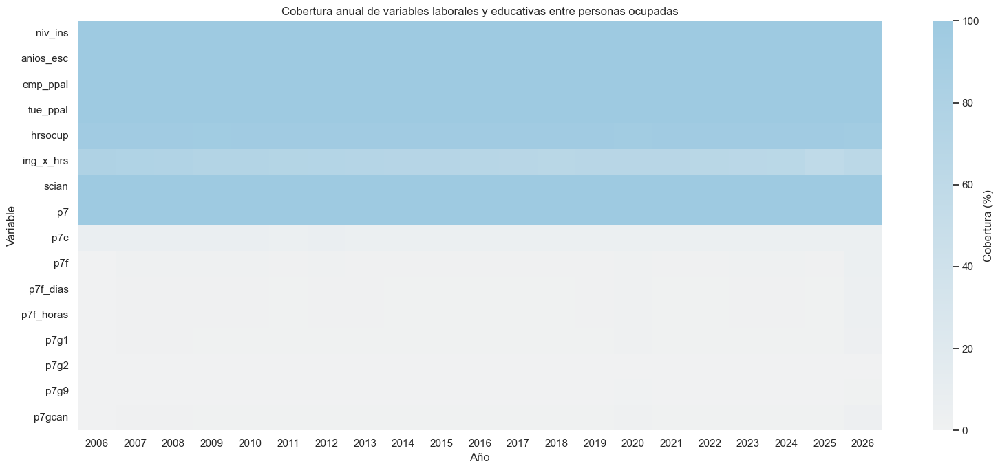

,anio,niv_ins,anios_esc,emp_ppal,tue_ppal,hrsocup,ing_x_hrs,scian,p7,p7c,p7f,p7f_dias,p7f_horas,p7g1,p7g2,p7g9,p7gcan
0,2006,100.00,99.80,100.00,100.00,96.20,78.90,100.00,99.60,6.60,0.00,0.00,0.00,0.00,0.00,0.00,0.00
1,2007,100.00,99.90,100.00,100.00,96.20,77.70,100.00,99.70,6.40,1.70,1.40,1.40,1.20,0.00,0.20,1.20
2,2008,100.00,99.90,100.00,100.00,96.30,76.00,100.00,99.70,6.50,1.80,1.50,1.50,1.30,0.00,0.20,1.30
3,2009,100.00,99.80,100.00,100.00,95.90,73.90,100.00,99.70,6.30,1.60,1.30,1.30,1.10,0.00,0.20,1.10
4,2010,100.00,99.90,100.00,100.00,96.50,74.40,100.00,99.70,6.30,1.70,1.30,1.30,1.20,0.00,0.20,1.20
5,2011,100.00,99.90,100.00,100.00,96.50,72.70,100.00,99.70,6.10,1.50,1.20,1.20,1.00,0.00,0.20,1.00
6,2012,100.00,99.80,100.00,100.00,96.60,72.50,100.00,99.70,6.40,1.60,1.30,1.30,1.10,0.00,0.20,1.10
7,2013,100.00,99.90,100.00,100.00,96.50,71.30,100.00,99.80,6.10,1.50,1.20,1.20,1.00,0.00,0.20,1.00
8,2014,100.00,99.90,100.00,100.00,96.70,70.90,100.00,99.80,5.70,1.50,1.10,1.10,1.00,0.00,0.20,1.00
9,2015,100.00,99.80,100.00,100.00,96.70,70.50,100.00,99.80,5.90,1.50,1.20,1.20,1.00,0.00,0.20,1.00


In [5]:
expresiones_cobertura = {
    "niv_ins": "niv_ins BETWEEN 0 AND 5", "anios_esc": "anios_esc BETWEEN 0 AND 30",
    "emp_ppal": "emp_ppal IS NOT NULL", "tue_ppal": "tue_ppal IS NOT NULL",
    "hrsocup": "hrsocup BETWEEN 1 AND 168", "ing_x_hrs": "ing_x_hrs > 0",
    "scian": "scian BETWEEN 1 AND 21", "p7": "p7 BETWEEN 1 AND 9",
    "p7c": "NULLIF(TRIM(CAST(p7c AS VARCHAR)), '') IS NOT NULL",
    "p7f": "p7f IS NOT NULL", "p7f_dias": "p7f_dias IS NOT NULL",
    "p7f_horas": "p7f_horas IS NOT NULL", "p7g1": "p7g1 IS NOT NULL",
    "p7g2": "p7g2 IS NOT NULL", "p7g9": "p7g9 IS NOT NULL", "p7gcan": "p7gcan IS NOT NULL"
}
columnas_cobertura = ", ".join(
    f"100.0 * COUNT_IF({expr}) / COUNT(*) AS {variable}"
    for variable, expr in expresiones_cobertura.items()
)
df_cobertura = con.sql(f"""
    SELECT anio, {columnas_cobertura}
    FROM {TABLA_ANALISIS}
    WHERE es_ocupado AND factor_valido AND fac_tri > 0 AND periodo <> '2020T2'
    GROUP BY anio ORDER BY anio
""").df()
df_cobertura_larga = df_cobertura.melt("anio", var_name="variable", value_name="cobertura_pct")

fig, ax = plt.subplots(figsize=(16, 7))
sns.heatmap(df_cobertura.set_index("anio").T, cmap=sns.light_palette(PALETA_PASTEL[0], as_cmap=True),
            vmin=0, vmax=100, cbar_kws={"label": "Cobertura (%)"}, ax=ax)
ax.set(title="Cobertura anual de variables laborales y educativas entre personas ocupadas", xlabel="Año", ylabel="Variable")
plt.tight_layout(); plt.show()
display(df_cobertura.round(1))


## Qué significa «la persona del medio»

Para cada grupo, se ordenan los valores y se acumula <code>fac_tri</code>; P50 es el primer valor que alcanza la mitad del peso total. P25 y P75 se obtienen del mismo modo. Para contar población se expande cada trimestre y después se promedian sus niveles.

**Lectura.** Estas funciones no producen todavía una cifra nacional. Fijan una distinción decisiva: la mediana anual se calcula con la distribución combinada, **no** promediando medianas trimestrales. La desviación estándar describe dispersión; no es el error estándar de la encuesta.

In [6]:
def _identificador(nombre):
    if not re.fullmatch(r"[A-Za-z_][A-Za-z0-9_]*", nombre):
        raise ValueError(f"Identificador SQL no válido: {nombre}")
    return nombre


def resumen_ponderado(valor, grupos, filtro="TRUE", tabla=TABLA_ANALISIS, peso="fac_tri"):
    valor, tabla, peso = map(_identificador, [valor, tabla, peso])
    grupos = [_identificador(g) for g in grupos]
    claves = ", ".join(grupos); prefijo = f"{claves}, " if claves else ""
    particion = f"PARTITION BY {claves} " if claves else ""
    agrupacion = f"GROUP BY {claves}, valor" if claves else "GROUP BY valor"
    agrupacion_final = f"GROUP BY {claves}" if claves else ""
    orden = f"ORDER BY {claves}" if claves else ""
    return con.sql(f"""
        WITH valores AS (
            SELECT {prefijo}TRY_CAST({valor} AS DOUBLE) AS valor,
                   SUM(TRY_CAST({peso} AS DOUBLE)) AS peso, COUNT(*) AS n_muestral
            FROM {tabla} WHERE ({filtro}) AND {valor} IS NOT NULL AND {peso} > 0 {agrupacion}
        ), ordenados AS (
            SELECT *, SUM(peso) OVER ({particion}) AS peso_total,
                   SUM(peso) OVER ({particion}ORDER BY valor ROWS BETWEEN UNBOUNDED PRECEDING AND CURRENT ROW) AS peso_acumulado
            FROM valores
        )
        SELECT {prefijo}SUM(n_muestral) AS n_muestral, MAX(peso_total) AS peso_total,
               SUM(valor * peso) / SUM(peso) AS media,
               SQRT(GREATEST(0, SUM(peso * valor * valor) / SUM(peso) - POWER(SUM(peso * valor) / SUM(peso), 2))) AS desviacion_estandar,
               MIN(CASE WHEN peso_acumulado >= peso_total * 0.25 THEN valor END) AS p25,
               MIN(CASE WHEN peso_acumulado >= peso_total * 0.50 THEN valor END) AS mediana,
               MIN(CASE WHEN peso_acumulado >= peso_total * 0.75 THEN valor END) AS p75
        FROM ordenados {agrupacion_final} {orden}
    """).df()


def cuantiles_extremos(valor, grupos, filtro="TRUE", tabla=TABLA_ANALISIS):
    valor, tabla = _identificador(valor), _identificador(tabla)
    grupos = [_identificador(g) for g in grupos]
    claves = ", ".join(grupos); prefijo = f"{claves}, " if claves else ""
    particion = f"PARTITION BY {claves} " if claves else ""
    agrupacion = f"GROUP BY {claves}, valor" if claves else "GROUP BY valor"
    agrupacion_final = f"GROUP BY {claves}" if claves else ""
    return con.sql(f"""
        WITH valores AS (
            SELECT {prefijo}TRY_CAST({valor} AS DOUBLE) AS valor, SUM(fac_tri) AS peso
            FROM {tabla} WHERE ({filtro}) AND {valor} > 0 AND factor_valido AND fac_tri > 0 {agrupacion}
        ), ordenados AS (
            SELECT *, SUM(peso) OVER ({particion}) AS peso_total,
                   SUM(peso) OVER ({particion}ORDER BY valor ROWS BETWEEN UNBOUNDED PRECEDING AND CURRENT ROW) AS peso_acumulado
            FROM valores
        )
        SELECT {prefijo}MIN(CASE WHEN peso_acumulado >= peso_total * 0.01 THEN valor END) AS p01,
               MIN(CASE WHEN peso_acumulado >= peso_total * 0.10 THEN valor END) AS p10,
               MIN(CASE WHEN peso_acumulado >= peso_total * 0.20 THEN valor END) AS p20,
               MIN(CASE WHEN peso_acumulado >= peso_total * 0.50 THEN valor END) AS p50,
               MIN(CASE WHEN peso_acumulado >= peso_total * 0.90 THEN valor END) AS p90,
               MIN(CASE WHEN peso_acumulado >= peso_total * 0.99 THEN valor END) AS p99
        FROM ordenados {agrupacion_final}
    """).df()


def promedio_trimestral_expandido(dimensiones, filtro, tabla=TABLA_ANALISIS):
    tabla = _identificador(tabla); dimensiones = [_identificador(d) for d in dimensiones]
    dims = ", ".join(dimensiones); prefijo = f"{dims}, " if dims else ""
    grupo_tri = f"anio, trimestre, periodo, {dims}" if dims else "anio, trimestre, periodo"
    grupo_anual = f"anio, {dims}" if dims else "anio"; orden = f"anio, {dims}" if dims else "anio"
    return con.sql(f"""
        WITH trimestral AS (
            SELECT anio, trimestre, periodo, {prefijo}SUM(fac_tri) AS poblacion
            FROM {tabla} WHERE ({filtro}) AND factor_valido AND fac_tri > 0 AND periodo <> '2020T2'
            GROUP BY {grupo_tri}
        )
        SELECT anio, {prefijo}AVG(poblacion) AS poblacion_promedio,
               COUNT(DISTINCT periodo) AS trimestres_disponibles
        FROM trimestral GROUP BY {grupo_anual} ORDER BY {orden}
    """).df()


def formato_millones(valor, _): return f"{abs(valor) / 1_000_000:.1f} M"
def formato_pesos(valor, _): return f"${valor:,.0f}"
def formato_miles(valor, _): return f"{valor / 1_000:g}"


def estilo_linea(ax, anios):
    ax.set_xticks(anios); ax.tick_params(axis="x", rotation=45)
    ax.grid(axis="x", alpha=0.28); ax.grid(axis="y", visible=False); sns.despine(ax=ax)


def estilo_eje_log_ingreso(ax, limites):
    ticks = np.array([250, 500, 1_000, 2_000, 3_000, 4_000, 5_000, 6_000, 8_000, 10_000,
                      15_000, 20_000, 30_000, 40_000, 50_000, 60_000, 80_000, 100_000])
    ticks = ticks[(ticks >= limites[0]) & (ticks <= limites[1])]
    ax.set_yticks(ticks); ax.yaxis.set_major_formatter(FuncFormatter(formato_miles))


def graficar_linea_ingreso_hora(datos, titulo):
    fig, ax = plt.subplots(figsize=(17, 7))
    sns.lineplot(data=datos, x="anio", y="mediana", hue="sexo", hue_order=["Hombre", "Mujer"],
                 palette=COLOR_SEXO, marker="o", linewidth=2.4, ax=ax)
    ax.set(title=titulo, xlabel="Año (2026 corresponde a T1)", ylabel="Mediana ponderada: pesos de 2026T1 por hora")
    ax.yaxis.set_major_formatter(FuncFormatter(formato_pesos)); estilo_linea(ax, sorted(datos["anio"].unique()))
    ax.legend(title="Sexo"); plt.tight_layout(); plt.show()


# 2. ¿Quiénes integran la población y quiénes trabajan?

Las pirámides parten de la población analítica de 15 años y más, trabaje o no. Se suma el factor de expansión por edad y sexo dentro de cada trimestre y se promedian esos totales por periodo.

**Lectura.** El total pasa de **76.81 millones** en el promedio 2006–2010 a **104.09 millones** en 2026T1. Por eso un aumento en el número de ocupados no basta para demostrar que aumentó la proporción que trabaja. El último panel es un trimestre, no otro lustro.

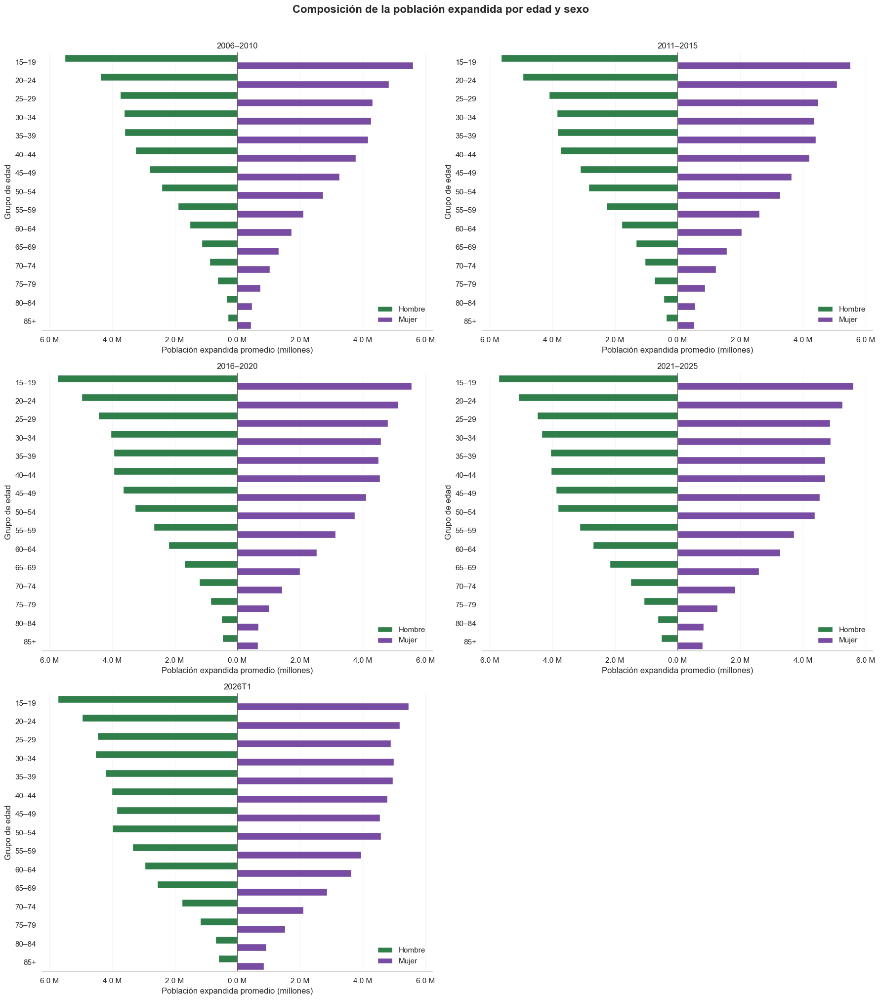

sexo,Hombre,Mujer,total
periodo_analisis,,,
2006–2010,"36,082,830.60","40,727,995.00","76,810,825.60"
2011–2015,"40,049,516.65","44,337,748.75","84,387,265.40"
2016–2020,"43,636,716.26","48,340,271.53","91,976,987.79"
2021–2025,"47,152,433.25","53,176,967.90","100,329,401.15"
2026T1,"48,875,829.00","55,210,478.00","104,086,307.00"


In [7]:
df_piramides = con.sql(f"""
    WITH trimestral AS (
        SELECT periodo_analisis, periodo, grupo_edad, sexo, SUM(fac_tri) AS poblacion
        FROM {TABLA_ANALISIS}
        WHERE factor_valido AND fac_tri > 0 AND eda >= 15 AND sexo IN ('Hombre', 'Mujer')
          AND grupo_edad IS NOT NULL AND periodo <> '2020T2'
        GROUP BY ALL
    )
    SELECT periodo_analisis, grupo_edad, sexo, AVG(poblacion) AS poblacion_promedio FROM trimestral GROUP BY ALL
""").df()
df_piramides["periodo_analisis"] = pd.Categorical(df_piramides["periodo_analisis"], ORDEN_PERIODOS, ordered=True)
df_piramides["grupo_edad"] = pd.Categorical(df_piramides["grupo_edad"], ORDEN_EDAD, ordered=True)
escala = 1.08 * df_piramides["poblacion_promedio"].max()

fig, axes = plt.subplots(3, 2, figsize=(18, 20), sharex=False)
for ax, periodo in zip(axes.flat, ORDEN_PERIODOS):
    datos = df_piramides[df_piramides["periodo_analisis"] == periodo].copy()
    datos["poblacion_grafica"] = np.where(datos["sexo"].eq("Hombre"), -datos["poblacion_promedio"], datos["poblacion_promedio"])
    sns.barplot(data=datos, y="grupo_edad", x="poblacion_grafica", hue="sexo", hue_order=["Hombre", "Mujer"],
                palette=COLOR_SEXO, errorbar=None, ax=ax)
    ax.axvline(0, color="#555555", linewidth=0.8)
    ax.set(title=periodo, xlabel="Población expandida promedio (millones)", ylabel="Grupo de edad", xlim=(-escala, escala))
    ax.xaxis.set_major_formatter(FuncFormatter(formato_millones)); ax.tick_params(axis="x", labelbottom=True)
    ax.grid(axis="x", alpha=0.20); ax.grid(axis="y", visible=False); ax.legend(title=None, frameon=False, loc="lower right")
    sns.despine(ax=ax, left=True)
axes.flat[-1].axis("off")
fig.suptitle("Composición de la población expandida por edad y sexo", y=1.01, fontsize=16, fontweight="bold")
plt.tight_layout(); plt.show()

tabla_piramides = (df_piramides.groupby(["periodo_analisis", "sexo"], observed=True)["poblacion_promedio"].sum()
                   .unstack().assign(total=lambda d: d.sum(axis=1)))
display(tabla_piramides)


## La edad cambia la comparación salarial

Entre ocupados con ingreso positivo, se calcula la mediana por grupo de edad, sexo y periodo. Las líneas comparan grupos contemporáneos; no siguen a una generación a través del tiempo.

**Lectura.** En 2006–2010 la mediana de 15–19 años fue de $5,679 para hombres y $4,917 para mujeres. En 2026T1 el grupo 85+ tiene solo 140 y 65 registros respectivamente; una igualdad puntual de medianas allí no demuestra que haya desaparecido una brecha.

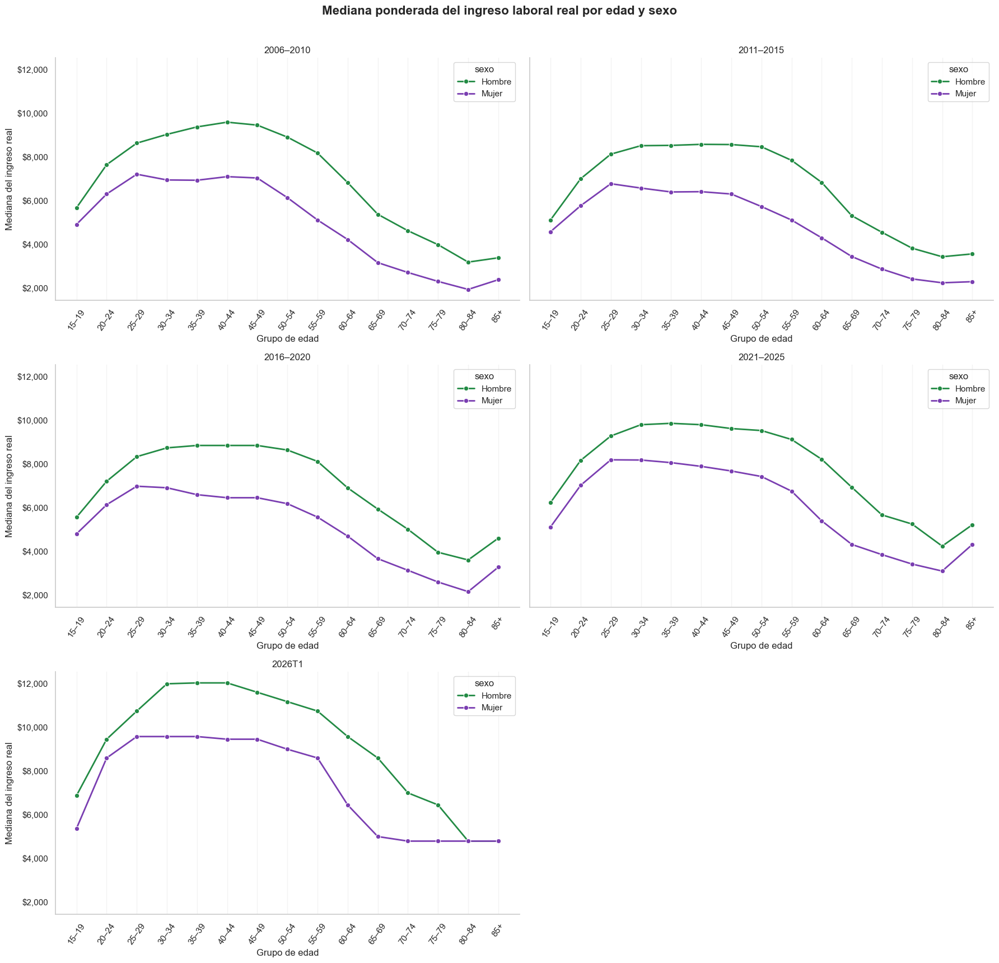

,periodo_analisis,grupo_edad,sexo,n_muestral,peso_total,media,desviacion_estandar,p25,mediana,p75
0,2006–2010,15–19,Hombre,"132,330.00","34,914,592.00","6,009.95","4,581.86","3,616.20","5,678.95","7,665.68"
1,2006–2010,15–19,Mujer,"68,400.00","17,889,901.00","5,122.40","3,563.09","3,044.32","4,916.67","6,625.44"
2,2006–2010,20–24,Hombre,"215,207.00","54,800,762.00","8,529.40","6,107.11","5,357.78","7,651.48","10,072.95"
3,2006–2010,20–24,Mujer,"136,680.00","33,543,491.00","7,283.81","6,446.69","4,520.25","6,307.32","8,699.95"
4,2006–2010,25–29,Hombre,"222,615.00","58,138,162.00","10,590.80","10,787.28","6,127.15","8,639.42","12,499.61"
...,...,...,...,...,...,...,...,...,...,...
145,2026T1,75–79,Mujer,377.00,"135,160.00","5,234.14","5,021.88","1,720.00","4,791.00","6,450.00"
146,2026T1,80–84,Hombre,252.00,"90,364.00","8,805.10","11,994.85","2,580.00","4,791.00","9,582.00"
147,2026T1,80–84,Mujer,130.00,"49,342.00","5,073.17","4,190.81","2,150.00","4,791.00","6,020.00"
148,2026T1,85+,Hombre,140.00,"46,811.00","6,713.67","8,038.14","3,440.00","4,791.00","7,525.00"


In [8]:
df_ingreso_edad = resumen_ponderado(
    "ingreso_laboral_ind_real", ["periodo_analisis", "grupo_edad", "sexo"],
    "es_ocupado AND ingreso_laboral_ind_real > 0 AND factor_valido AND sexo IN ('Hombre', 'Mujer') "
    "AND grupo_edad IS NOT NULL AND periodo <> '2020T2'"
)
df_ingreso_edad["periodo_analisis"] = pd.Categorical(df_ingreso_edad["periodo_analisis"], ORDEN_PERIODOS, ordered=True)
df_ingreso_edad["grupo_edad"] = pd.Categorical(df_ingreso_edad["grupo_edad"], ORDEN_EDAD, ordered=True)

fig, axes = plt.subplots(3, 2, figsize=(18, 17), sharey=True)
for ax, periodo in zip(axes.flat, ORDEN_PERIODOS):
    datos = df_ingreso_edad[df_ingreso_edad["periodo_analisis"] == periodo]
    sns.lineplot(data=datos, x="grupo_edad", y="mediana", hue="sexo", hue_order=["Hombre", "Mujer"],
                 palette=COLOR_SEXO, marker="o", linewidth=2, ax=ax)
    ax.set(title=periodo, xlabel="Grupo de edad", ylabel="Mediana del ingreso real")
    ax.tick_params(axis="x", rotation=55); ax.yaxis.set_major_formatter(FuncFormatter(formato_pesos))
    ax.grid(axis="x", alpha=0.22); ax.grid(axis="y", visible=False); sns.despine(ax=ax)
axes.flat[-1].axis("off")
fig.suptitle("Mediana ponderada del ingreso laboral real por edad y sexo", y=1.01, fontsize=16, fontweight="bold")
plt.tight_layout(); plt.show()
display(df_ingreso_edad.sort_values(["periodo_analisis", "grupo_edad", "sexo"]).round(2))


## Del tamaño poblacional a la proporción ocupada

Para cada sexo se divide el peso de los ocupados entre el peso de **toda** la población analítica de 15 años y más del mismo sexo. Se promedian después los porcentajes trimestrales.

**Lectura.** Entre 2006 y 2026T1 la proporción masculina pasa de 78.02% a 72.16%, y la femenina de 40.38% a 43.99%. La diferencia se reduce de 37.64 a 28.17 puntos porcentuales. El denominador no es la población económicamente activa: esto no es una tasa de desempleo.

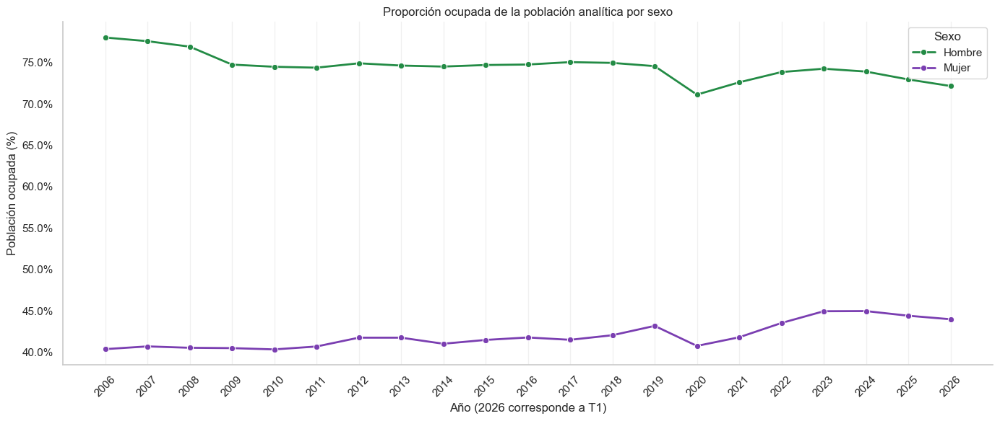

,anio,sexo,ocupados_pct,trimestres_disponibles
0,2006,Hombre,78.02,4
1,2006,Mujer,40.38,4
2,2007,Hombre,77.57,4
3,2007,Mujer,40.71,4
4,2008,Hombre,76.91,4
5,2008,Mujer,40.54,4
6,2009,Hombre,74.75,4
7,2009,Mujer,40.50,4
8,2010,Hombre,74.48,4
9,2010,Mujer,40.34,4


In [9]:
df_ocupacion_sexo = con.sql(f"""
    WITH trimestral AS (
        SELECT anio, periodo, sexo,
               100.0 * SUM(CASE WHEN es_ocupado THEN fac_tri ELSE 0 END) / SUM(fac_tri) AS ocupados_pct
        FROM {TABLA_ANALISIS}
        WHERE factor_valido AND fac_tri > 0 AND eda >= 15
          AND sexo IN ('Hombre', 'Mujer') AND periodo <> '2020T2'
        GROUP BY anio, periodo, sexo
    )
    SELECT anio, sexo, AVG(ocupados_pct) AS ocupados_pct, COUNT(*) AS trimestres_disponibles
    FROM trimestral GROUP BY anio, sexo ORDER BY anio, sexo
""").df()

fig, ax = plt.subplots(figsize=(14, 6))
sns.lineplot(data=df_ocupacion_sexo, x="anio", y="ocupados_pct", hue="sexo",
             hue_order=["Hombre", "Mujer"], palette=COLOR_SEXO, marker="o", linewidth=2, ax=ax)
ax.set(title="Proporción ocupada de la población analítica por sexo", xlabel="Año (2026 corresponde a T1)",
       ylabel="Población ocupada (%)")
ax.yaxis.set_major_formatter(PercentFormatter()); estilo_linea(ax, sorted(df_ocupacion_sexo["anio"].unique()))
ax.legend(title="Sexo"); plt.tight_layout(); plt.show()
display(df_ocupacion_sexo.round(2))


## Crece el empleo formal, pero el informal sigue siendo mayoritario

Se clasifica el **empleo principal**, no la unidad económica ni el segundo trabajo. El primer gráfico muestra niveles trimestrales promedio; el segundo, la proporción formal dentro del empleo clasificado.

**Lectura.** En 2006 había 17.67 millones en empleo formal y 25.61 en informal; en 2026T1 son 26.93 y 32.96 millones. La participación formal sube de 40.82% a 44.96%: creció en número y en participación, pero **55.04%** de los ocupados clasificados seguía en empleo informal al cierre.

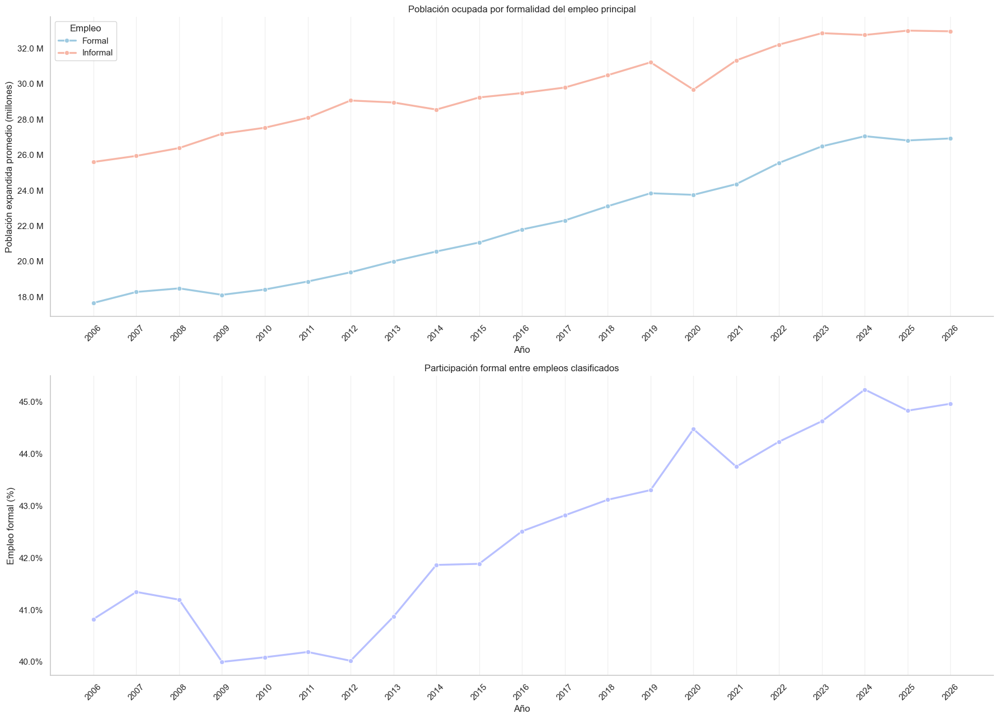

,anio,tipo_empleo,poblacion_promedio,trimestres_disponibles
0,2006,Formal,"17,667,113.25",4
1,2006,Informal,"25,606,149.75",4
2,2007,Formal,"18,284,887.75",4
3,2007,Informal,"25,947,081.50",4
4,2008,Formal,"18,486,590.25",4
5,2008,Informal,"26,389,675.50",4
6,2009,Formal,"18,122,513.25",4
7,2009,Informal,"27,194,710.50",4
8,2010,Formal,"18,422,956.00",4
9,2010,Informal,"27,534,404.75",4


,anio,formal_pct
0,2006,40.82
1,2007,41.34
2,2008,41.20
3,2009,40.00
4,2010,40.09
5,2011,40.19
6,2012,40.02
7,2013,40.87
8,2014,41.86
9,2015,41.89


In [10]:
df_empleo_formalidad = promedio_trimestral_expandido(["tipo_empleo"], "es_ocupado AND tipo_empleo IN ('Formal', 'Informal')")
df_participacion_formal = con.sql(f"""
    WITH trimestral AS (
        SELECT anio, periodo, 100.0 * SUM(CASE WHEN tipo_empleo = 'Formal' THEN fac_tri ELSE 0 END) / SUM(fac_tri) AS formal_pct
        FROM {TABLA_ANALISIS}
        WHERE es_ocupado AND factor_valido AND fac_tri > 0 AND tipo_empleo IN ('Formal', 'Informal') AND periodo <> '2020T2'
        GROUP BY anio, periodo
    ) SELECT anio, AVG(formal_pct) AS formal_pct FROM trimestral GROUP BY anio ORDER BY anio
""").df()

fig, axes = plt.subplots(2, 1, figsize=(18, 13))
sns.lineplot(data=df_empleo_formalidad, x="anio", y="poblacion_promedio", hue="tipo_empleo", hue_order=["Formal", "Informal"],
             palette=COLOR_EMPLEO, marker="o", linewidth=2.4, ax=axes[0])
axes[0].set(title="Población ocupada por formalidad del empleo principal", xlabel="Año", ylabel="Población expandida promedio (millones)")
axes[0].yaxis.set_major_formatter(FuncFormatter(formato_millones)); estilo_linea(axes[0], sorted(df_empleo_formalidad["anio"].unique())); axes[0].legend(title="Empleo")
sns.lineplot(data=df_participacion_formal, x="anio", y="formal_pct", color=PALETA_PASTEL[5], marker="o", linewidth=2.4, ax=axes[1])
axes[1].set(title="Participación formal entre empleos clasificados", xlabel="Año", ylabel="Empleo formal (%)")
axes[1].yaxis.set_major_formatter(PercentFormatter()); estilo_linea(axes[1], sorted(df_participacion_formal["anio"].unique()))
plt.tight_layout(); plt.show()
display(df_empleo_formalidad, df_participacion_formal.round(2))


# 3. El tiempo de trabajo: detrás del ingreso mensual

Se distribuyen las horas semanales positivas (1–168) de los ocupados en 14 intervalos; se estima el porcentaje ponderado de cada intervalo por trimestre y se promedia en el tiempo.

**Lectura.** El intervalo más frecuente es **37–48 horas**, con 40.53%. Es el grupo más numeroso, no una mayoría absoluta. Quienes no trabajaron horas esa semana quedan fuera de este histograma.

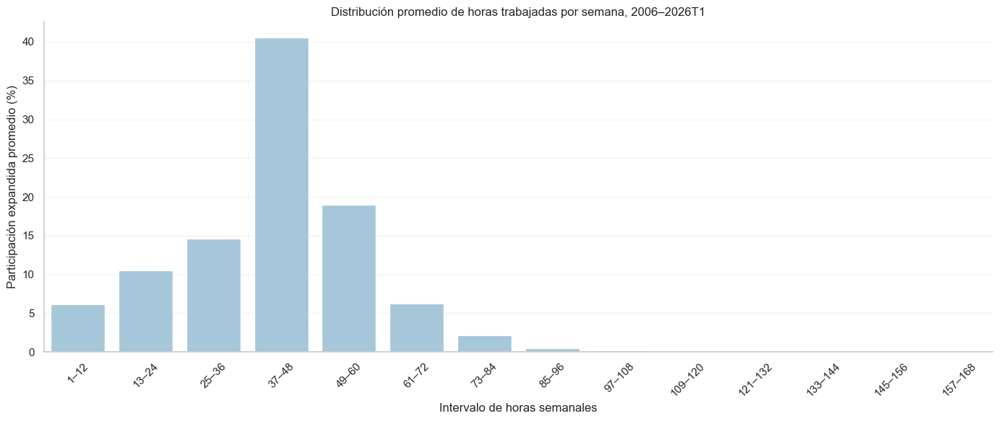

,bin,porcentaje_promedio,intervalo_horas
0,0,6.16,1–12
1,1,10.51,13–24
2,2,14.63,25–36
3,3,40.53,37–48
4,4,19.03,49–60
5,5,6.22,61–72
6,6,2.15,73–84
7,7,0.48,85–96
8,8,0.24,97–108
9,9,0.05,109–120


In [11]:
LIMITE_HORAS, N_BINS_HORAS = 168, 14
ANCHO_BIN_HORAS = LIMITE_HORAS // N_BINS_HORAS

def distribucion_horas(dimensiones):
    dimensiones = [_identificador(d) for d in dimensiones]
    dims = ", ".join(dimensiones)
    prefijo = f"{dims}, " if dims else ""
    particion = f"periodo, {dims}" if dims else "periodo"
    grupo = f"periodo, {dims}, bin" if dims else "periodo, bin"
    grupo_final = f"{dims}, bin" if dims else "bin"
    return con.sql(f"""
        WITH base AS (
            SELECT periodo, {prefijo}LEAST(CAST(FLOOR((hrsocup - 1) / {ANCHO_BIN_HORAS}) AS INTEGER),
                                           {N_BINS_HORAS - 1}) AS bin, fac_tri
            FROM {TABLA_ANALISIS}
            WHERE es_ocupado AND factor_valido AND fac_tri > 0
              AND hrsocup BETWEEN 1 AND {LIMITE_HORAS} AND periodo <> '2020T2'
        ), trimestral AS (
            SELECT periodo, {prefijo}bin, SUM(fac_tri) AS peso
            FROM base GROUP BY {grupo}
        ), porcentajes AS (
            SELECT *, 100.0 * peso / SUM(peso) OVER (PARTITION BY {particion}) AS porcentaje
            FROM trimestral
        )
        SELECT {prefijo}bin, AVG(porcentaje) AS porcentaje_promedio
        FROM porcentajes GROUP BY {grupo_final} ORDER BY {grupo_final}
    """).df()


def etiquetar_bins_horas(df):
    df = df.copy()
    inferior = df["bin"] * ANCHO_BIN_HORAS + 1
    superior = np.minimum((df["bin"] + 1) * ANCHO_BIN_HORAS, LIMITE_HORAS)
    df["intervalo_horas"] = inferior.astype(int).astype(str) + "–" + superior.astype(int).astype(str)
    return df


df_horas_general = etiquetar_bins_horas(distribucion_horas([]))
fig, ax = plt.subplots(figsize=(14, 6))
sns.barplot(data=df_horas_general, x="intervalo_horas", y="porcentaje_promedio",
            color=PALETA_PASTEL[0], errorbar=None, ax=ax)
ax.set(title="Distribución promedio de horas trabajadas por semana, 2006–2026T1",
       xlabel="Intervalo de horas semanales", ylabel="Participación expandida promedio (%)")
ax.tick_params(axis="x", rotation=45); ax.grid(axis="y", alpha=0.22); ax.grid(axis="x", visible=False)
sns.despine(ax=ax); plt.tight_layout(); plt.show()
display(df_horas_general.round(2))


## ¿Se distribuye igual la jornada de hombres y mujeres?

Se repite el histograma con un denominador por sexo. Así, una barra compara la frecuencia de una jornada dentro de cada grupo y no el tamaño relativo de ambos grupos.

**Lectura.** De 1 a 12 horas se concentra 9.91% de las mujeres y 3.82% de los hombres. En el intervalo central de 37–48 horas ocurre lo contrario: 38.31% frente a 41.92%. Una sola jornada «típica» ocultaría esa diferencia.

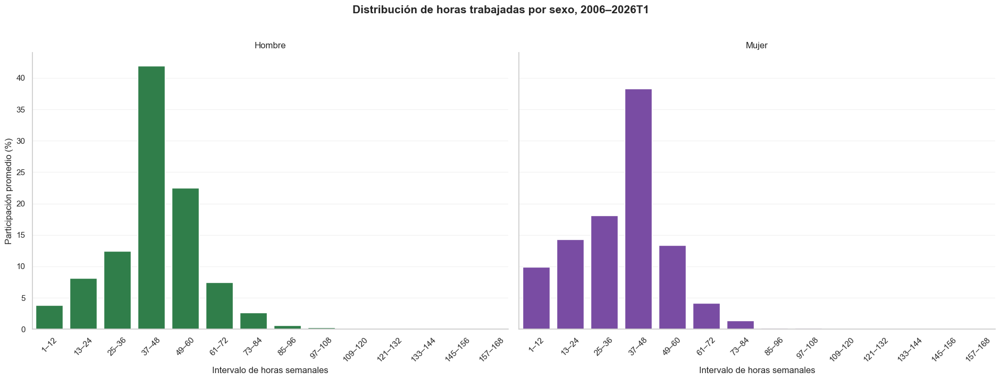

,sexo,bin,porcentaje_promedio,intervalo_horas
0,Hombre,0,3.82,1–12
1,Hombre,1,8.16,13–24
2,Hombre,2,12.45,25–36
3,Hombre,3,41.92,37–48
4,Hombre,4,22.52,49–60
5,Hombre,5,7.49,61–72
6,Hombre,6,2.63,73–84
7,Hombre,7,0.63,85–96
8,Hombre,8,0.29,97–108
9,Hombre,9,0.07,109–120


In [12]:
df_horas_sexo = etiquetar_bins_horas(distribucion_horas(["sexo"]))
fig, axes = plt.subplots(1, 2, figsize=(19, 7), sharey=True)
for ax, sexo in zip(axes, ["Hombre", "Mujer"]):
    datos = df_horas_sexo[df_horas_sexo["sexo"] == sexo]
    sns.barplot(data=datos, x="intervalo_horas", y="porcentaje_promedio",
                color=COLOR_SEXO[sexo], errorbar=None, ax=ax)
    ax.set(title=sexo, xlabel="Intervalo de horas semanales", ylabel="Participación promedio (%)")
    ax.tick_params(axis="x", rotation=45); ax.grid(axis="y", alpha=0.22); ax.grid(axis="x", visible=False)
    sns.despine(ax=ax)
fig.suptitle("Distribución de horas trabajadas por sexo, 2006–2026T1", y=1.02, fontsize=15, fontweight="bold")
plt.tight_layout(); plt.show()
display(df_horas_sexo.round(2))


## La formalidad concentra las jornadas en un intervalo más estrecho

Cada panel calcula participaciones dentro de una combinación de sexo y formalidad; no se suman porcentajes entre paneles.

**Lectura.** Entre las mujeres, 58.28% del empleo formal se ubica en 37–48 horas frente a 24.17% del informal. Entre los hombres son 53.08% y 33.61%. La diferencia no se limita a cuántas horas marca la mediana: también cambia la forma de la distribución.

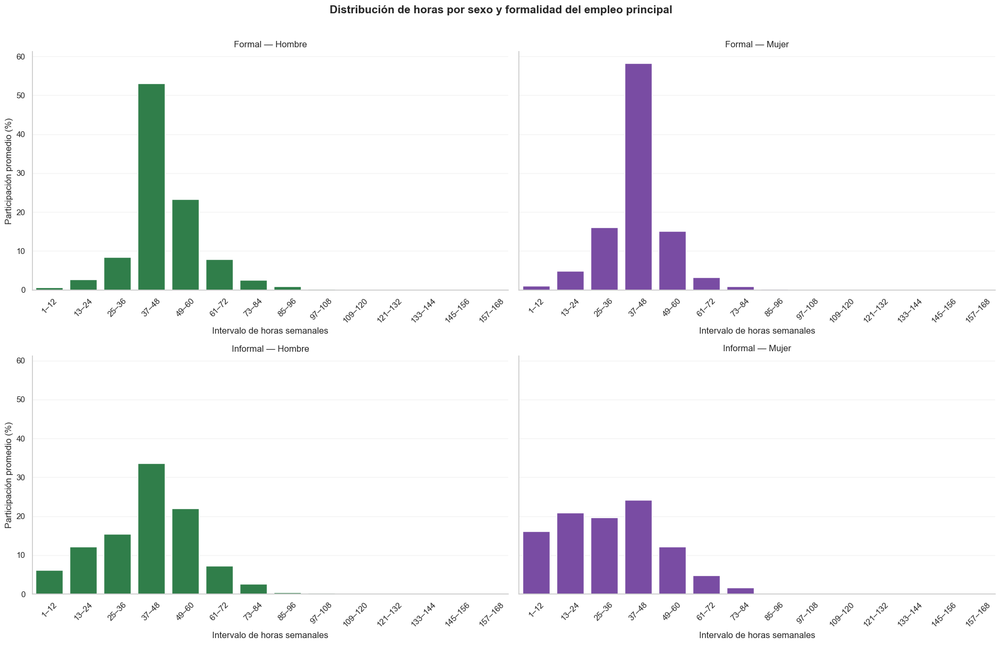

,tipo_empleo,sexo,bin,porcentaje_promedio,intervalo_horas
0,Formal,Hombre,0,0.66,1–12
1,Formal,Hombre,1,2.71,13–24
2,Formal,Hombre,2,8.45,25–36
3,Formal,Hombre,3,53.08,37–48
4,Formal,Hombre,4,23.31,49–60
5,Formal,Hombre,5,7.88,61–72
6,Formal,Hombre,6,2.60,73–84
7,Formal,Hombre,7,0.92,85–96
8,Formal,Hombre,8,0.27,97–108
9,Formal,Hombre,9,0.09,109–120


In [13]:
df_horas_sexo_empleo = etiquetar_bins_horas(distribucion_horas(["tipo_empleo", "sexo"]))
fig, axes = plt.subplots(2, 2, figsize=(19, 12), sharex=False, sharey=True)
for fila, empleo in enumerate(["Formal", "Informal"]):
    for columna, sexo in enumerate(["Hombre", "Mujer"]):
        ax = axes[fila, columna]; datos = df_horas_sexo_empleo.query("tipo_empleo == @empleo and sexo == @sexo")
        sns.barplot(data=datos, x="intervalo_horas", y="porcentaje_promedio", color=COLOR_SEXO[sexo], errorbar=None, ax=ax)
        ax.set(title=f"{empleo} — {sexo}", xlabel="Intervalo de horas semanales", ylabel="Participación promedio (%)")
        ax.tick_params(axis="x", rotation=45, labelbottom=True); ax.grid(axis="y", alpha=0.22); ax.grid(axis="x", visible=False); sns.despine(ax=ax)
fig.suptitle("Distribución de horas por sexo y formalidad del empleo principal", y=1.01, fontsize=15, fontweight="bold")
plt.tight_layout(); plt.show(); display(df_horas_sexo_empleo.round(2))


## ¿Cuánto cambió el centro de la jornada?

Se agrupan las horas válidas de cada año por sexo y se localiza la mediana ponderada. Los estadísticos de la tabla complementan las dos líneas.

**Lectura.** En 2006 se obtienen 48 horas para hombres y 40 para mujeres; en 2026T1, 46 y 40. La estabilidad de la mediana femenina no implica que todas las jornadas se mantuvieran constantes.

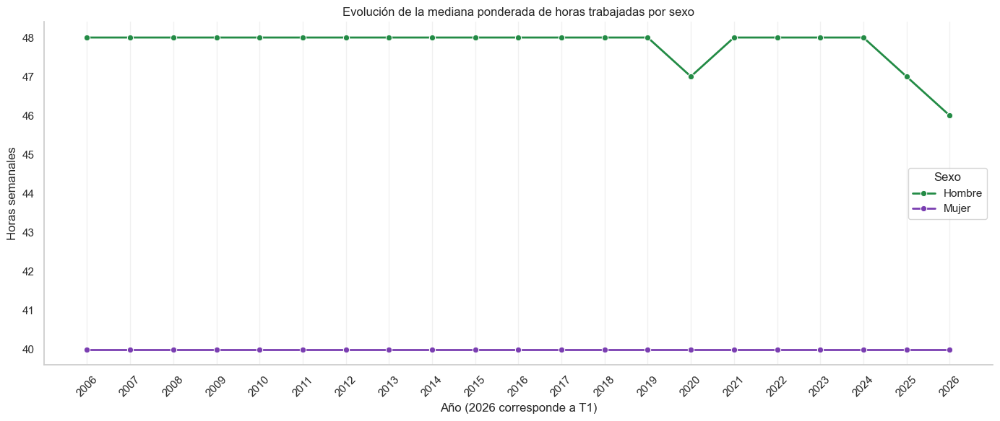

,anio,sexo,n_muestral,peso_total,media,desviacion_estandar,p25,mediana,p75
0,2006,Hombre,"412,346.00","105,385,676.00",45.89,16.35,40.00,48.00,54.00
1,2006,Mujer,"253,683.00","61,580,319.00",37.69,17.20,25.00,40.00,48.00
2,2007,Hombre,"409,701.00","106,936,903.00",45.41,16.48,36.00,48.00,54.00
3,2007,Mujer,"257,230.00","63,548,034.00",37.38,17.36,24.00,40.00,48.00
4,2008,Hombre,"405,874.00","108,841,651.00",45.59,16.50,38.00,48.00,54.00
5,2008,Mujer,"255,263.00","64,385,704.00",37.69,17.24,25.00,40.00,48.00
6,2009,Hombre,"391,428.00","109,022,151.00",45.25,16.76,36.00,48.00,54.00
7,2009,Mujer,"246,874.00","65,216,441.00",37.53,17.29,24.00,40.00,48.00
8,2010,Hombre,"395,228.00","111,375,170.00",45.26,16.72,36.00,48.00,54.00
9,2010,Mujer,"249,297.00","66,419,405.00",37.55,17.32,24.00,40.00,48.00


In [14]:
df_mediana_horas_sexo = resumen_ponderado(
    "hrsocup", ["anio", "sexo"],
    "es_ocupado AND factor_valido AND hrsocup BETWEEN 1 AND 168 "
    "AND sexo IN ('Hombre', 'Mujer') AND periodo <> '2020T2'"
)
fig, ax = plt.subplots(figsize=(14, 6))
sns.lineplot(data=df_mediana_horas_sexo, x="anio", y="mediana", hue="sexo",
             hue_order=["Hombre", "Mujer"], palette=COLOR_SEXO, marker="o", linewidth=2, ax=ax)
ax.set(title="Evolución de la mediana ponderada de horas trabajadas por sexo",
       xlabel="Año (2026 corresponde a T1)", ylabel="Horas semanales")
estilo_linea(ax, sorted(df_mediana_horas_sexo["anio"].unique())); ax.legend(title="Sexo")
plt.tight_layout(); plt.show()
display(df_mediana_horas_sexo.round(2))


## Más de 48 horas: una pregunta sobre la cola, no sobre la mediana

Para cada trimestre se calcula qué fracción de los ocupados con horas válidas de cada grupo **supera** 48 horas; después se promedian las fracciones por año.

**Lectura.** En hombres formales esa proporción baja de 37.05% en 2006 a 28.70% en 2026T1; en informales, de 34.60% a 29.52%. En el último corte, las mujeres registran 16.65% y 16.86%, respectivamente. Son porcentajes dentro de cada grupo, no del total de hombres y mujeres juntos.

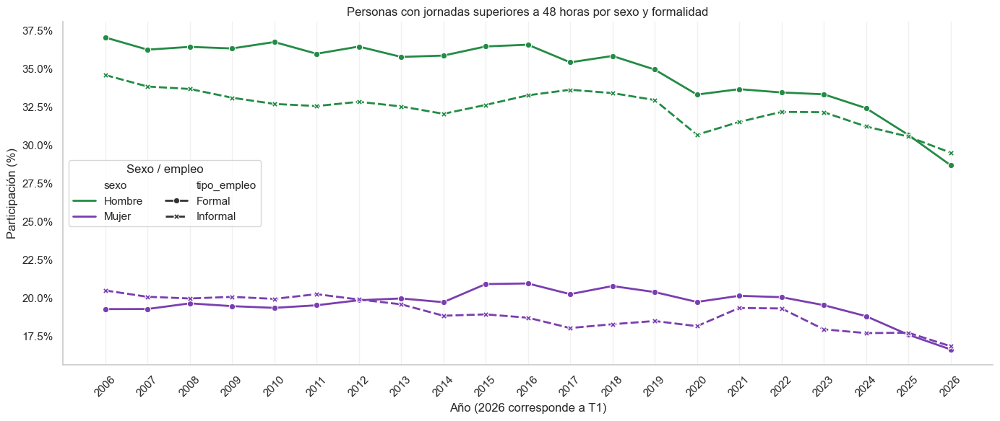

,anio,sexo,tipo_empleo,mas_48_pct
0,2006,Hombre,Formal,37.05
1,2006,Hombre,Informal,34.60
2,2006,Mujer,Formal,19.29
3,2006,Mujer,Informal,20.51
4,2007,Hombre,Formal,36.26
...,...,...,...,...
79,2025,Mujer,Informal,17.74
80,2026,Hombre,Formal,28.70
81,2026,Hombre,Informal,29.52
82,2026,Mujer,Formal,16.65


In [15]:
df_jornada_extensa = con.sql(f"""
    WITH trimestral AS (
        SELECT anio, periodo, sexo, tipo_empleo,
               100.0 * SUM(CASE WHEN hrsocup > 48 THEN fac_tri ELSE 0 END) / SUM(fac_tri) AS mas_48_pct
        FROM {TABLA_ANALISIS}
        WHERE es_ocupado AND factor_valido AND fac_tri > 0 AND hrsocup BETWEEN 1 AND 168
          AND sexo IN ('Hombre', 'Mujer') AND tipo_empleo IN ('Formal', 'Informal') AND periodo <> '2020T2'
        GROUP BY ALL
    )
    SELECT anio, sexo, tipo_empleo, AVG(mas_48_pct) AS mas_48_pct
    FROM trimestral GROUP BY ALL ORDER BY anio, sexo, tipo_empleo
""").df()
fig, ax = plt.subplots(figsize=(14, 6))
sns.lineplot(data=df_jornada_extensa, x="anio", y="mas_48_pct", hue="sexo", style="tipo_empleo",
             hue_order=["Hombre", "Mujer"], style_order=["Formal", "Informal"], palette=COLOR_SEXO,
             markers=True, dashes=True, linewidth=2, ax=ax)
ax.set(title="Personas con jornadas superiores a 48 horas por sexo y formalidad",
       xlabel="Año (2026 corresponde a T1)", ylabel="Participación (%)")
ax.yaxis.set_major_formatter(PercentFormatter()); estilo_linea(ax, sorted(df_jornada_extensa["anio"].unique()))
ax.legend(title="Sexo / empleo", ncol=2); plt.tight_layout(); plt.show()
display(df_jornada_extensa.round(2))


## Cómo pasar de pesos al mes a pesos por hora

Para cada observación se divide el ingreso mensual real positivo entre las horas semanales válidas multiplicadas por 4.3. Se contrasta el cociente en pesos nominales con el valor precalculado <code>ing_x_hrs</code> cuando están disponibles ambos.

**Lectura.** En 9,747,546 coincidencias evaluadas, la proporción ponderada dentro de la tolerancia de un centavo aparece como 100.00% al redondear. La comprobación respalda la fórmula en esa intersección; no resuelve la falta de datos del resto.

In [16]:
df_validacion_ingreso_hora = con.sql(f"""
    SELECT COUNT(*) AS coincidencias_evaluadas,
           SUM(fac_tri * ABS(ingreso_hora_real / factor_deflactor - ing_x_hrs)) / SUM(fac_tri) AS error_absoluto_ponderado,
           100.0 * SUM(CASE WHEN ABS(ingreso_hora_real / factor_deflactor - ing_x_hrs) <= 0.01 THEN fac_tri ELSE 0 END)
                   / SUM(fac_tri) AS coincide_tolerancia_pct
    FROM {TABLA_ANALISIS}
    WHERE ingreso_hora_real > 0 AND ing_x_hrs > 0 AND factor_valido AND fac_tri > 0
      AND periodo <> '2020T2'
""").df()

filtro_hora = ("es_ocupado AND factor_valido AND ingreso_hora_real > 0 AND hrsocup BETWEEN 1 AND 168 "
               "AND sexo IN ('Hombre', 'Mujer') AND periodo <> '2020T2'")
df_ingreso_hora_sexo = resumen_ponderado("ingreso_hora_real", ["anio", "sexo"], filtro_hora)
df_ingreso_hora_empleo = resumen_ponderado(
    "ingreso_hora_real", ["anio", "tipo_empleo", "sexo"],
    filtro_hora + " AND tipo_empleo IN ('Formal', 'Informal')"
)
display(df_validacion_ingreso_hora.round(4), df_ingreso_hora_sexo.round(2), df_ingreso_hora_empleo.round(2))


,coincidencias_evaluadas,error_absoluto_ponderado,coincide_tolerancia_pct
0,9747546,0.00,100.00


,anio,sexo,n_muestral,peso_total,media,desviacion_estandar,p25,mediana,p75
0,2006,Hombre,"361,707.00","90,520,731.00",62.18,89.21,27.77,42.01,68.01
1,2006,Mujer,"217,137.00","51,621,009.00",60.00,79.30,25.49,39.67,69.19
2,2007,Hombre,"356,943.00","91,069,372.00",63.54,99.71,28.59,42.92,68.68
3,2007,Mujer,"218,194.00","52,905,518.00",60.78,87.71,26.39,40.06,68.60
4,2008,Hombre,"347,695.00","91,819,497.00",61.39,83.71,27.89,42.29,66.90
5,2008,Mujer,"214,120.00","53,291,988.00",59.16,87.13,25.82,39.42,66.71
6,2009,Hombre,"329,497.00","90,724,082.00",58.83,86.27,26.84,40.73,64.17
7,2009,Mujer,"204,891.00","53,655,820.00",56.96,97.51,25.28,38.57,64.79
8,2010,Hombre,"332,524.00","92,604,037.00",57.14,95.76,26.80,39.58,61.85
9,2010,Mujer,"207,503.00","54,745,935.00",55.89,70.09,24.74,38.26,64.49


,anio,tipo_empleo,sexo,n_muestral,peso_total,media,desviacion_estandar,p25,mediana,p75
0,2006,Formal,Hombre,"179,310.00","40,001,435.00",80.56,105.88,36.59,53.69,89.93
1,2006,Formal,Mujer,"106,690.00","23,044,054.00",76.74,84.47,34.71,52.90,92.27
2,2006,Informal,Hombre,"182,397.00","50,519,296.00",47.62,70.04,23.14,34.76,52.90
3,2006,Informal,Mujer,"110,447.00","28,576,955.00",46.50,72.09,19.84,31.50,49.66
4,2007,Formal,Hombre,"178,961.00","40,939,574.00",80.75,106.23,37.21,54.29,89.30
...,...,...,...,...,...,...,...,...,...,...
79,2025,Informal,Mujer,"130,339.00","42,154,053.00",61.30,86.70,27.77,41.65,65.08
80,2026,Formal,Hombre,"44,777.00","13,611,828.00",86.80,110.95,47.92,66.67,93.56
81,2026,Formal,Mujer,"30,600.00","9,120,598.00",84.44,78.33,46.51,65.22,95.50
82,2026,Informal,Hombre,"46,425.00","16,140,655.00",62.41,84.75,33.33,46.42,68.63


## Al comparar por hora, cambia la magnitud de la brecha

Se trazan las medianas de los cocientes individuales, primero para toda la población elegible y luego dentro del empleo formal e informal. No se divide una mediana mensual entre una mediana de horas.

**Lectura.** En 2026T1 son  55.56 MXN por hora para hombres y 53.03 MXN para mujeres. Dentro del empleo formal son 66.67 MXN y 65.22 MXN; en el informal, 46.42 MXN y 43.75 MXN. Compárese con las medianas mensuales del capítulo siguiente: una menor diferencia por hora no significa igualdad de ingresos mensuales.

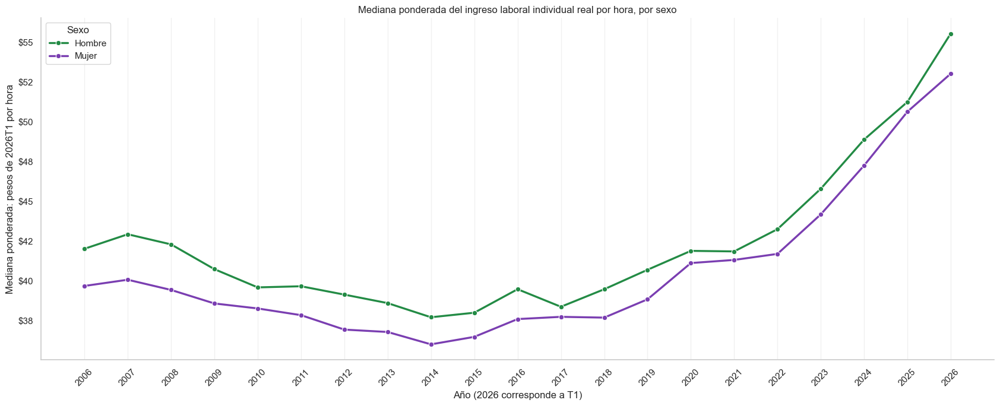

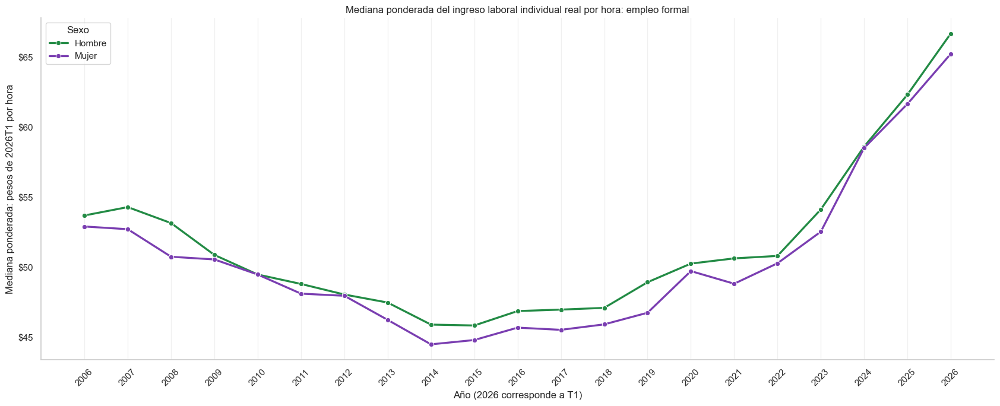

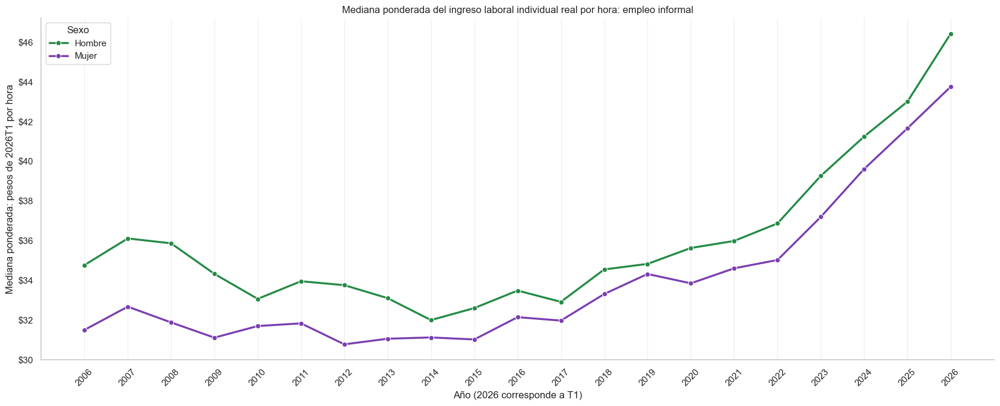

In [17]:
graficar_linea_ingreso_hora(df_ingreso_hora_sexo, "Mediana ponderada del ingreso laboral individual real por hora, por sexo")
graficar_linea_ingreso_hora(
    df_ingreso_hora_empleo.query("tipo_empleo == 'Formal'"),
    "Mediana ponderada del ingreso laboral individual real por hora: empleo formal"
)
graficar_linea_ingreso_hora(
    df_ingreso_hora_empleo.query("tipo_empleo == 'Informal'"),
    "Mediana ponderada del ingreso laboral individual real por hora: empleo informal"
)


# 4. Lo que el ingreso típico muestra y lo que oculta

Para dibujar la distribución mensual de ingresos positivos se restringe el histograma a P1–P99, se forman 50 intervalos y se promedian sus frecuencias expandidas trimestrales.

**Lectura.** El intervalo de 4,880 MXN a 5,743 MXN reúne aproximadamente **3.45 millones** por trimestre en la serie combinada. La cola alta tiene barras mucho menores. Ni los extremos omitidos ni las personas sin ingreso están representados en esta figura.

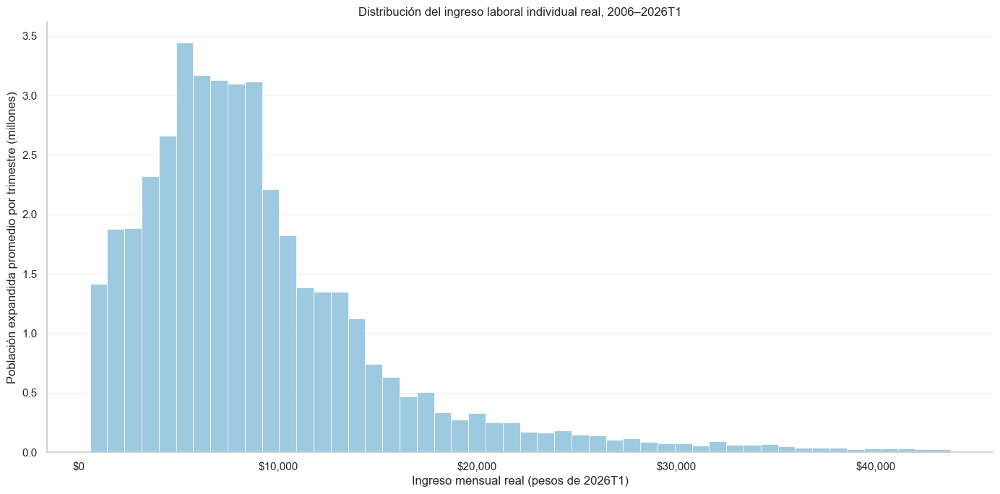

,bin,frecuencia_expandida_promedio,trimestres_disponibles,limite_inferior,limite_superior
0,0,"1,417,745.90",80,563.40,"1,426.70"
1,1,"1,878,084.98",80,"1,426.70","2,290.00"
2,2,"1,882,704.99",80,"2,290.00","3,153.31"
3,3,"2,321,774.48",80,"3,153.31","4,016.61"
4,4,"2,658,611.21",80,"4,016.61","4,879.91"
5,5,"3,445,597.74",80,"4,879.91","5,743.21"
6,6,"3,168,803.48",80,"5,743.21","6,606.51"
7,7,"3,129,875.48",80,"6,606.51","7,469.81"
8,8,"3,097,040.89",80,"7,469.81","8,333.11"
9,9,"3,114,712.34",80,"8,333.11","9,196.41"


In [18]:
N_BINS_INGRESO = 50
limites_ingreso = cuantiles_extremos(
    "ingreso_laboral_ind_real", [], "es_ocupado AND ingreso_laboral_ind_real > 0 AND periodo <> '2020T2'"
).iloc[0]
p01, p99 = limites_ingreso["p01"], limites_ingreso["p99"]
df_hist_ingreso = con.sql(f"""
    WITH binned AS (
        SELECT anio, trimestre, periodo,
               LEAST({N_BINS_INGRESO - 1}, GREATEST(0, CAST(FLOOR(
                   (ingreso_laboral_ind_real - {p01}) / ({p99} - {p01}) * {N_BINS_INGRESO}
               ) AS INTEGER))) AS bin, fac_tri
        FROM {TABLA_ANALISIS}
        WHERE es_ocupado AND factor_valido AND fac_tri > 0 AND ingreso_laboral_ind_real BETWEEN {p01} AND {p99}
          AND periodo <> '2020T2'
    ), trimestral AS (
        SELECT anio, trimestre, periodo, bin, SUM(fac_tri) AS frecuencia_expandida FROM binned GROUP BY ALL
    ) SELECT bin, AVG(frecuencia_expandida) AS frecuencia_expandida_promedio,
             COUNT(DISTINCT periodo) AS trimestres_disponibles
      FROM trimestral GROUP BY bin ORDER BY bin
""").df()
rejilla = pd.DataFrame({"bin": np.arange(N_BINS_INGRESO)})
df_hist_ingreso = rejilla.merge(df_hist_ingreso, how="left").fillna({"frecuencia_expandida_promedio": 0})
edges = np.linspace(p01, p99, N_BINS_INGRESO + 1)
df_hist_ingreso["limite_inferior"], df_hist_ingreso["limite_superior"] = edges[:-1], edges[1:]

fig, ax = plt.subplots(figsize=(14, 7))
ax.bar(df_hist_ingreso["limite_inferior"], df_hist_ingreso["frecuencia_expandida_promedio"] / 1_000_000,
       width=df_hist_ingreso["limite_superior"] - df_hist_ingreso["limite_inferior"], align="edge",
       color=PALETA_PASTEL[0], edgecolor="white", linewidth=0.5)
ax.set(title="Distribución del ingreso laboral individual real, 2006–2026T1", xlabel="Ingreso mensual real (pesos de 2026T1)",
       ylabel="Población expandida promedio por trimestre (millones)")
ax.xaxis.set_major_formatter(FuncFormatter(formato_pesos)); ax.yaxis.set_major_formatter(FuncFormatter(lambda x, _: f"{x:.1f}"))
ax.grid(axis="y", alpha=0.25); ax.grid(axis="x", visible=False); sns.despine(ax=ax); plt.tight_layout(); plt.show()
display(df_hist_ingreso.round(2))


## El centro se recupera; los extremos no avanzan al mismo ritmo

Se calculan P10, P20, P50, P90 y P99 con ponderadores. Los cocientes comparan **umbrales**, no promedios de grupos. La variación graficada es 100 × (valor actual − anterior) / **valor actual**; no es la tasa convencional con base en el año anterior.

**Lectura.** La mediana baja de 7,972 MXN en 2006 a 6,924 MXN en 2014; en 2025 llega a 8,815 MXN y en 2026T1 a 9,582 MXN. Entre los extremos de la serie, P50/P10 pasa de 3.35 a 2.48 y P99/P50 de 6.98 a 4.71. El rótulo «D10/D5» de la V3 se refiere a **P99/P50**, no al ingreso típico del décimo decil. El último cambio compara un trimestre con todo 2025.

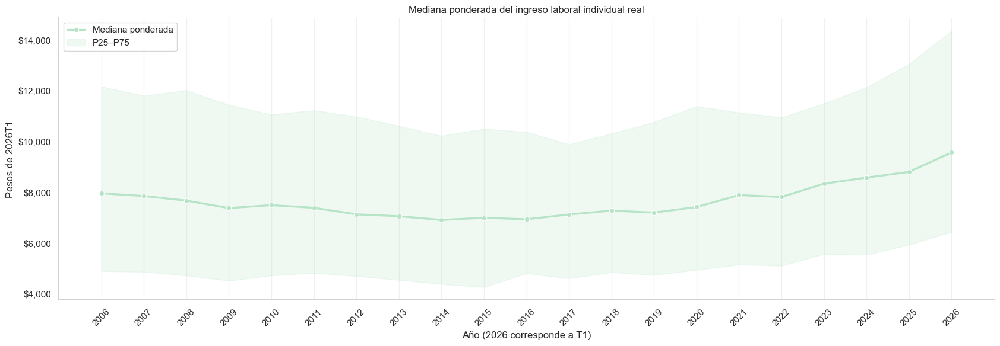

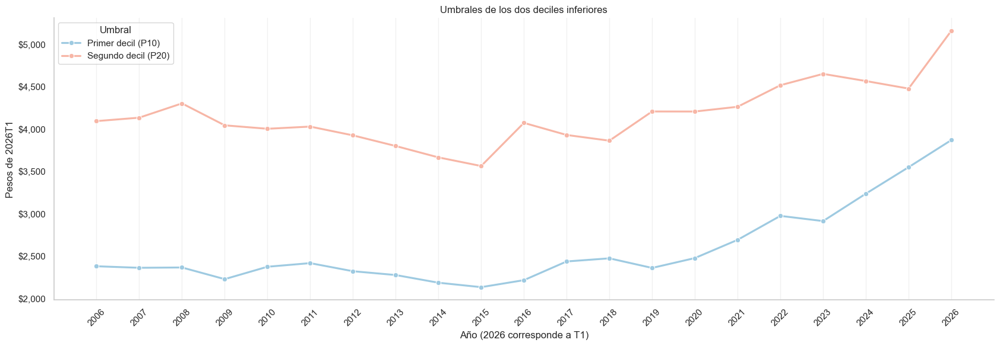

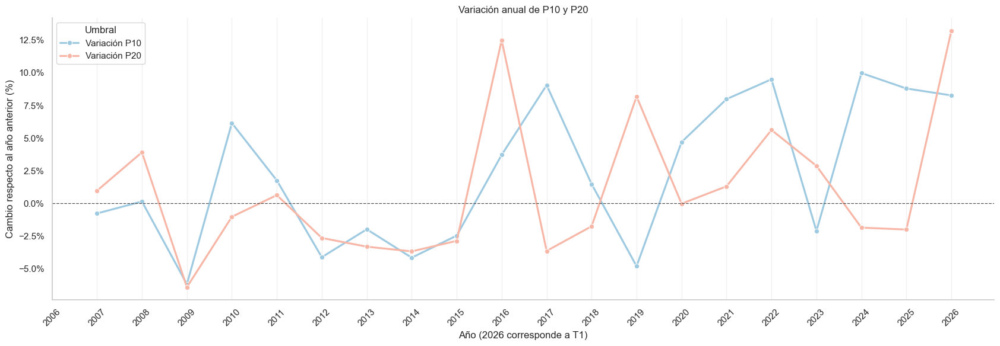

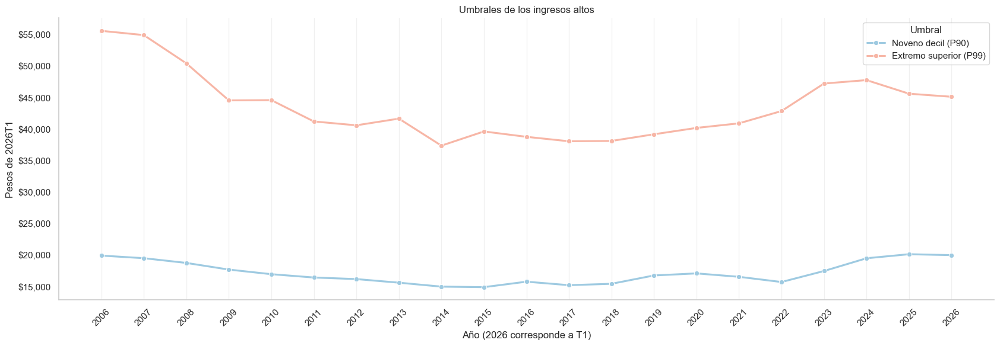

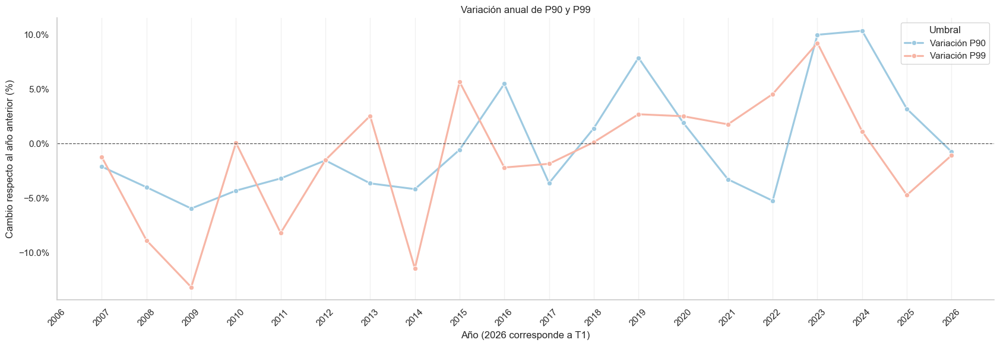

,anio,n_muestral,peso_total,media,desviacion_estandar,p25,mediana,p75
0,2006,"600,379.00","146,912,044.00","10,384.57","12,212.89","4,906.39","7,972.11","12,177.27"
1,2007,"596,869.00","148,989,371.00","10,411.54","12,724.98","4,879.34","7,866.67","11,812.82"
2,2008,"582,832.00","149,930,355.00","10,116.70","11,815.88","4,732.46","7,684.42","12,027.15"
3,2009,"556,688.00","149,885,011.00","9,537.90","10,643.42","4,530.33","7,390.63","11,460.03"
4,2010,"558,918.00","151,880,978.00","9,293.20","10,068.05","4,737.55","7,506.48","11,072.64"
5,2011,"549,412.00","153,186,410.00","9,157.87","9,611.04","4,835.07","7,402.58","11,244.36"
6,2012,"553,524.00","157,822,941.00","9,053.13","9,544.03","4,710.83","7,144.95","10,991.93"
7,2013,"544,206.00","158,428,114.00","8,925.61","11,554.67","4,560.10","7,069.93","10,626.41"
8,2014,"550,876.00","158,486,825.00","8,574.65","8,143.02","4,398.88","6,923.67","10,237.73"
9,2015,"554,307.00","162,287,789.00","8,655.26","8,653.39","4,276.63","7,008.40","10,512.60"


,anio,p01,p10,p20,p50,p90,p99,variacion_p10_pct,variacion_p20_pct,variacion_p90_pct,variacion_p99_pct
0,2006,471.99,"2,380.58","4,094.09","7,972.11","19,930.28","55,619.37",NaN,NaN,NaN,NaN
1,2007,476.18,"2,362.56","4,134.49","7,866.67","19,517.36","54,943.36",-0.76,0.98,-2.12,-1.23
2,2008,469.13,"2,366.23","4,303.10","7,684.42","18,765.39","50,458.56",0.15,3.92,-4.01,-8.89
3,2009,505.52,"2,228.61","4,044.12","7,390.63","17,709.48","44,578.32",-6.18,-6.40,-5.96,-13.19
4,2010,493.50,"2,374.86","4,003.46","7,506.48","16,976.24","44,612.15",6.16,-1.02,-4.32,0.08
5,2011,493.51,"2,417.54","4,029.23","7,402.58","16,450.18","41,229.32",1.77,0.64,-3.20,-8.20
6,2012,525.61,"2,322.06","3,925.69","7,144.95","16,200.45","40,617.29",-4.11,-2.64,-1.54,-1.51
7,2013,530.24,"2,277.09","3,800.09","7,069.93","15,629.73","41,679.28",-1.98,-3.31,-3.65,2.55
8,2014,513.59,"2,186.42","3,665.73","6,923.67","15,002.37","37,390.49",-4.15,-3.67,-4.18,-11.47
9,2015,542.74,"2,133.98","3,563.86","7,008.40","14,918.49","39,641.07",-2.46,-2.86,-0.56,5.68


,Indicador,2006,2007,2008,2009,2010,2011,2012,2013,2014,2015,2016,2017,2018,2019,2020,2021,2022,2023,2024,2025,2026
0,Ratio D10/D5 (P99/P50),6.98,6.98,6.57,6.03,5.94,5.57,5.68,5.90,5.40,5.66,5.58,5.34,5.23,5.43,5.41,5.18,5.48,5.66,5.56,5.18,4.71
1,Ratio D9/D5 (P90/P50),2.50,2.48,2.44,2.40,2.26,2.22,2.27,2.21,2.17,2.13,2.27,2.13,2.12,2.33,2.30,2.10,2.01,2.09,2.27,2.29,2.09
2,D5 o mediana (P50),"7,972.11","7,866.67","7,684.42","7,390.63","7,506.48","7,402.58","7,144.95","7,069.93","6,923.67","7,008.40","6,949.90","7,138.21","7,290.79","7,213.20","7,431.82","7,902.22","7,827.93","8,351.70","8,590.95","8,815.49","9,582.00"
3,Ratio D5/D2 (P50/P20),1.95,1.90,1.79,1.83,1.88,1.84,1.82,1.86,1.89,1.97,1.71,1.82,1.89,1.71,1.77,1.85,1.73,1.80,1.88,1.97,1.86
4,Ratio D5/D1 (P50/P10),3.35,3.33,3.25,3.32,3.16,3.06,3.08,3.10,3.17,3.28,3.14,2.93,2.95,3.06,3.00,2.94,2.63,2.87,2.65,2.48,2.48


In [19]:
filtro_ingreso = ("es_ocupado AND ingreso_laboral_ind_real > 0 AND factor_valido AND periodo <> '2020T2'")
df_ingreso_anual = resumen_ponderado("ingreso_laboral_ind_real", ["anio"], filtro_ingreso)
df_deciles = cuantiles_extremos("ingreso_laboral_ind_real", ["anio"], filtro_ingreso)
df_deciles["variacion_p10_pct"] = 100 * (df_deciles["p10"] - df_deciles["p10"].shift(1)) / df_deciles["p10"]
df_deciles["variacion_p20_pct"] = 100 * (df_deciles["p20"] - df_deciles["p20"].shift(1)) / df_deciles["p20"]
df_deciles["variacion_p90_pct"] = 100 * (df_deciles["p90"] - df_deciles["p90"].shift(1)) / df_deciles["p90"]
df_deciles["variacion_p99_pct"] = 100 * (df_deciles["p99"] - df_deciles["p99"].shift(1)) / df_deciles["p99"]

def grafica_cuantiles(datos, columnas, etiquetas, titulo, ylabel="Pesos de 2026T1", porcentaje=False):
    fig, ax = plt.subplots(figsize=(17, 6))
    for columna, etiqueta, color in zip(columnas, etiquetas, PALETA_PASTEL):
        sns.lineplot(data=datos, x="anio", y=columna, marker="o", linewidth=2.3, label=etiqueta, color=color, ax=ax)
    ax.set(title=titulo, xlabel="Año (2026 corresponde a T1)", ylabel=ylabel)
    ax.yaxis.set_major_formatter(PercentFormatter(xmax=100) if porcentaje else FuncFormatter(formato_pesos))
    if porcentaje: ax.axhline(0, color="#555555", linewidth=0.9, linestyle="--")
    estilo_linea(ax, sorted(datos["anio"].unique())); ax.legend(title="Umbral")
    plt.tight_layout(); plt.show()

fig, ax = plt.subplots(figsize=(17, 6))
sns.lineplot(data=df_ingreso_anual, x="anio", y="mediana", color=PALETA_PASTEL[2], marker="o", linewidth=2.4, ax=ax, label="Mediana ponderada")
ax.fill_between(df_ingreso_anual["anio"], df_ingreso_anual["p25"], df_ingreso_anual["p75"], color=PALETA_PASTEL[2], alpha=0.22, label="P25–P75")
ax.set(title="Mediana ponderada del ingreso laboral individual real", xlabel="Año (2026 corresponde a T1)", ylabel="Pesos de 2026T1")
ax.yaxis.set_major_formatter(FuncFormatter(formato_pesos)) 
estilo_linea(ax, sorted(df_ingreso_anual["anio"].unique())); ax.legend(); plt.tight_layout(); plt.show()

grafica_cuantiles(df_deciles, ["p10", "p20"], ["Primer decil (P10)", "Segundo decil (P20)"], "Umbrales de los dos deciles inferiores")
grafica_cuantiles(df_deciles, ["variacion_p10_pct", "variacion_p20_pct"], ["Variación P10", "Variación P20"],
                  "Variación anual de P10 y P20", ylabel="Cambio respecto al año anterior (%)", porcentaje=True)

grafica_cuantiles(df_deciles, ["p90", "p99"], ["Noveno decil (P90)", "Extremo superior (P99)"],
                  "Umbrales de los ingresos altos")
grafica_cuantiles(df_deciles, ["variacion_p90_pct", "variacion_p99_pct"], ["Variación P90", "Variación P99"],
                  "Variación anual de P90 y P99", ylabel="Cambio respecto al año anterior (%)", porcentaje=True)

tabla_desigualdad = pd.DataFrame({
    "Indicador": ["Ratio D10/D5 (P99/P50)", "Ratio D9/D5 (P90/P50)", "D5 o mediana (P50)", "Ratio D5/D2 (P50/P20)", "Ratio D5/D1 (P50/P10)"],
    **{str(int(a)): [
        r.p99 / r.p50, r.p90 / r.p50, r.p50, r.p50 / r.p20, r.p50 / r.p10
    ] for r, a in zip(df_deciles.itertuples(index=False), df_deciles["anio"])}
})
display(df_ingreso_anual.round(2), df_deciles.round(2), tabla_desigualdad.round(2))


## ¿En qué tramos monetarios se concentra la población ocupada?

Las barras agrupan pesos mensuales de 2026T1 y promedian participaciones trimestrales; las pirámides usan un denominador independiente para cada sexo. A diferencia del bloque anterior, aquí entran también los registros sin ingreso positivo recuperado.

**Lectura.** En 2026T1, 33.21% de las ocupadas cae entre más de 5,000 MXN y 10,000 MXN, y 25.09% entre más de 10,000 MXN y 20,000 MXN. **«Sin ingreso» reúne ceros y faltantes** por el CASE de esta celda. No se debe presentar como porcentaje de trabajo no remunerado.

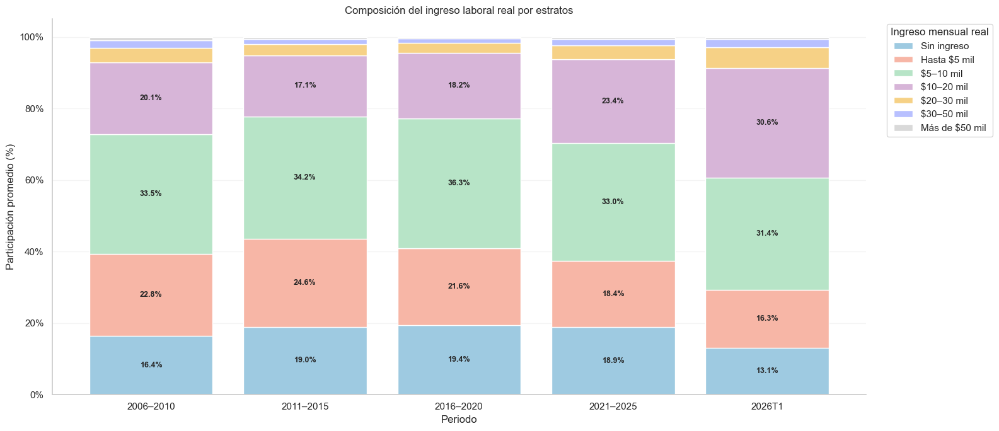

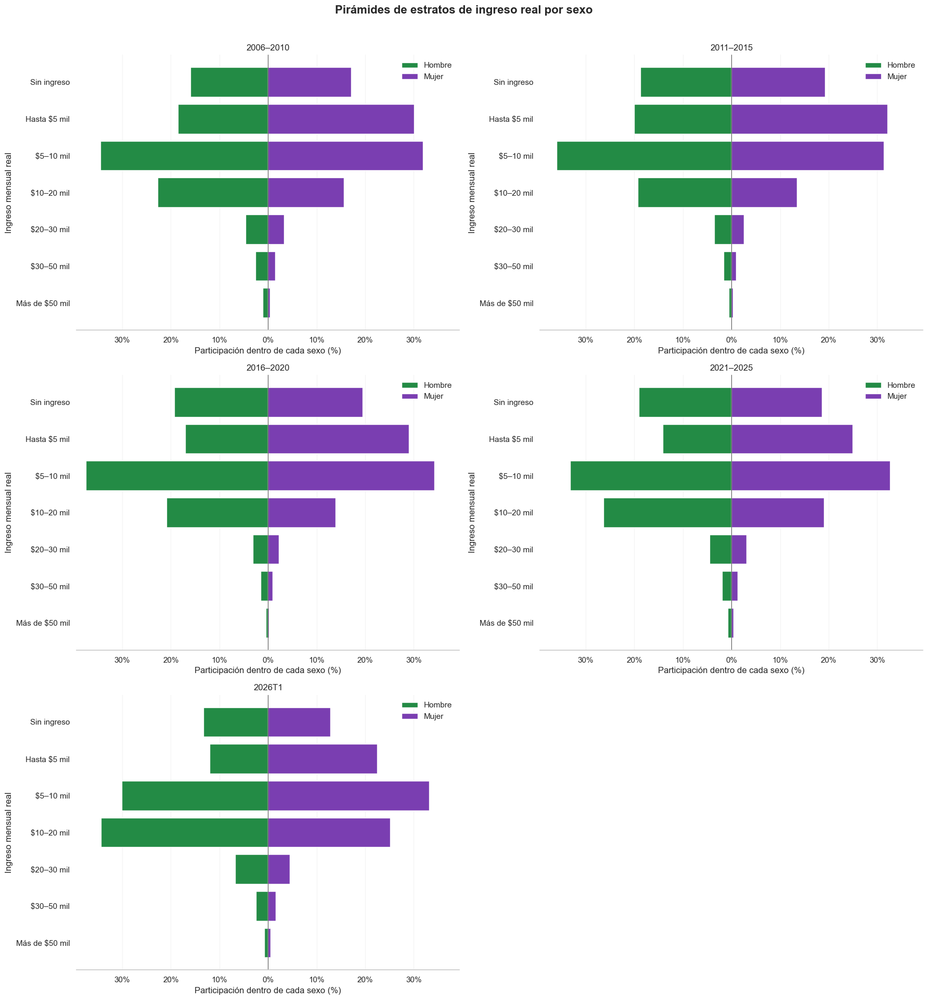

,periodo_analisis,sexo,estrato,porcentaje_promedio
36,2006–2010,Hombre,Sin ingreso,15.97
23,2006–2010,Hombre,Hasta $5 mil,18.52
55,2006–2010,Hombre,$5–10 mil,34.46
54,2006–2010,Hombre,$10–20 mil,22.77
64,2006–2010,Hombre,$20–30 mil,4.66
...,...,...,...,...
67,2026T1,Mujer,$5–10 mil,33.21
68,2026T1,Mujer,$10–20 mil,25.09
58,2026T1,Mujer,$20–30 mil,4.43
12,2026T1,Mujer,$30–50 mil,1.59


In [20]:
ORDEN_INGRESO = ["Sin ingreso", "Hasta $5 mil", "$5–10 mil", "$10–20 mil", "$20–30 mil", "$30–50 mil", "Más de $50 mil"]
case_ingreso = """
    CASE WHEN ingreso_laboral_ind_real IS NULL OR ingreso_laboral_ind_real <= 0 THEN 'Sin ingreso'
         WHEN ingreso_laboral_ind_real <= 5000 THEN 'Hasta $5 mil'
         WHEN ingreso_laboral_ind_real <= 10000 THEN '$5–10 mil'
         WHEN ingreso_laboral_ind_real <= 20000 THEN '$10–20 mil'
         WHEN ingreso_laboral_ind_real <= 30000 THEN '$20–30 mil'
         WHEN ingreso_laboral_ind_real <= 50000 THEN '$30–50 mil'
         ELSE 'Más de $50 mil' END
"""
df_estratos = con.sql(f"""
    WITH trimestral AS (
        SELECT periodo_analisis, periodo, sexo, {case_ingreso} AS estrato, SUM(fac_tri) AS peso
        FROM {TABLA_ANALISIS}
        WHERE es_ocupado AND factor_valido AND fac_tri > 0 AND sexo IN ('Hombre', 'Mujer') AND periodo <> '2020T2'
        GROUP BY ALL
    ), porcentajes AS (
        SELECT *, 100.0 * peso / SUM(peso) OVER (PARTITION BY periodo, sexo) AS porcentaje FROM trimestral
    ) SELECT periodo_analisis, sexo, estrato, AVG(porcentaje) AS porcentaje_promedio FROM porcentajes GROUP BY ALL
""").df()
df_estratos_general = con.sql(f"""
    WITH trimestral AS (
        SELECT periodo_analisis, periodo, {case_ingreso} AS estrato, SUM(fac_tri) AS peso
        FROM {TABLA_ANALISIS} WHERE es_ocupado AND factor_valido AND fac_tri > 0 AND periodo <> '2020T2' GROUP BY ALL
    ), porcentajes AS (
        SELECT *, 100.0 * peso / SUM(peso) OVER (PARTITION BY periodo) AS porcentaje FROM trimestral
    ) SELECT periodo_analisis, estrato, AVG(porcentaje) AS porcentaje_promedio FROM porcentajes GROUP BY ALL
""").df()
for datos in (df_estratos, df_estratos_general):
    datos["periodo_analisis"] = pd.Categorical(datos["periodo_analisis"], ORDEN_PERIODOS, ordered=True)
    datos["estrato"] = pd.Categorical(datos["estrato"], ORDEN_INGRESO, ordered=True)

pivote = df_estratos_general.pivot(index="periodo_analisis", columns="estrato", values="porcentaje_promedio").fillna(0)
pivote = pivote.reindex(index=ORDEN_PERIODOS, columns=ORDEN_INGRESO, fill_value=0)
fig, ax = plt.subplots(figsize=(16, 7)); base_acum = np.zeros(len(pivote))
colores_estratos = PALETA_PASTEL[:6] + ["#D9D9D9"]
for color, estrato in zip(colores_estratos, ORDEN_INGRESO):
    valores = pivote[estrato].to_numpy(); ax.bar(pivote.index, valores, bottom=base_acum, label=estrato, color=color)
    base_acum += valores
for j, periodo in enumerate(pivote.index):
    mayores = pivote.loc[periodo].nlargest(4)
    acumulado = 0
    for estrato in ORDEN_INGRESO:
        valor = pivote.loc[periodo, estrato]
        if estrato in mayores.index and valor >= 4:
            ax.text(j, acumulado + valor / 2, f"{valor:.1f}%", ha="center", va="center", fontsize=9, fontweight="bold")
        acumulado += valor
ax.set(title="Composición del ingreso laboral real por estratos", xlabel="Periodo", ylabel="Participación promedio (%)")
ax.yaxis.set_major_formatter(PercentFormatter()); ax.legend(title="Ingreso mensual real", bbox_to_anchor=(1.02, 1), loc="upper left")
ax.grid(axis="y", alpha=0.20); ax.grid(axis="x", visible=False); sns.despine(ax=ax); plt.tight_layout(); plt.show()

fig, axes = plt.subplots(3, 2, figsize=(18, 19), sharex=False)
y = np.arange(len(ORDEN_INGRESO)); escala = 1.05 * df_estratos["porcentaje_promedio"].max()
for ax, periodo in zip(axes.flat, ORDEN_PERIODOS):
    panel = df_estratos[df_estratos["periodo_analisis"] == periodo].pivot(index="estrato", columns="sexo", values="porcentaje_promedio").reindex(ORDEN_INGRESO).fillna(0)
    ax.barh(y, -panel["Hombre"], color=COLOR_SEXO["Hombre"], label="Hombre")
    ax.barh(y, panel["Mujer"], color=COLOR_SEXO["Mujer"], label="Mujer")
    ax.axvline(0, color="#555555", linewidth=0.8); ax.set_yticks(y, ORDEN_INGRESO); ax.invert_yaxis()
    ax.set(title=periodo, xlabel="Participación dentro de cada sexo (%)", ylabel="Ingreso mensual real", xlim=(-escala, escala))
    ax.xaxis.set_major_formatter(FuncFormatter(lambda x, _: f"{abs(x):.0f}%")); ax.tick_params(axis="x", labelbottom=True)
    ax.grid(axis="x", alpha=0.20); ax.grid(axis="y", visible=False); ax.legend(title=None, frameon=False); sns.despine(ax=ax, left=True)
axes.flat[-1].axis("off")
fig.suptitle("Pirámides de estratos de ingreso real por sexo", y=1.01, fontsize=16, fontweight="bold")
plt.tight_layout(); plt.show(); display(df_estratos.sort_values(["periodo_analisis", "sexo", "estrato"]).round(2))


## Cómo leer los violines antes de comparar grupos

Se forman 180 intervalos logarítmicos, se suma el peso de cada intervalo y se suaviza el perfil entre P1 y P99. Las marcas resumen la distribución de ingreso positivo: media, mediana y tramo P25–P75.

**Lectura.** Este bloque prepara la figura. El ancho indica concentración relativa de ingresos, no cuántas personas hay en ese grupo; la altura se lee en una escala logarítmica. La misma distancia vertical representa una razón, no una diferencia fija de pesos.

In [22]:
N_BINS_VIOLIN, SUAVIZADO = 180, 2.0

def preparar_violin(categoria, filtro, categorias):
    categoria = _identificador(categoria)
    con.execute(f"""
        CREATE OR REPLACE TEMP VIEW base_violin_actual AS
        SELECT anio, {categoria} AS categoria, ingreso_laboral_ind_real AS ingreso, fac_tri, factor_valido
        FROM {TABLA_ANALISIS}
        WHERE es_ocupado AND factor_valido AND fac_tri > 0 AND ingreso_laboral_ind_real > 0
          AND periodo <> '2020T2' AND ({filtro})
    """)
    limites = cuantiles_extremos("ingreso", ["anio", "categoria"], "TRUE", "base_violin_actual")
    minimo, maximo = limites["p01"].min(), limites["p99"].max(); bordes = np.geomspace(minimo, maximo, N_BINS_VIOLIN + 1)
    con.register("limites_violin_actual", limites)
    densidad = con.sql(f"""
        WITH base AS (
            SELECT b.*, l.p01, l.p99, LEAST({N_BINS_VIOLIN - 1}, GREATEST(0, CAST(FLOOR(
                (LN(b.ingreso) - LN({minimo})) / (LN({maximo}) - LN({minimo})) * {N_BINS_VIOLIN}
            ) AS INTEGER))) AS bin
            FROM base_violin_actual AS b JOIN limites_violin_actual AS l USING (anio, categoria)
            WHERE b.ingreso BETWEEN l.p01 AND l.p99
        ) SELECT anio, categoria, bin, SUM(fac_tri) AS peso_bin FROM base GROUP BY ALL ORDER BY anio, categoria, bin
    """).df()
    grilla = pd.MultiIndex.from_product([sorted(limites["anio"].unique()), categorias, range(N_BINS_VIOLIN)], names=["anio", "categoria", "bin"]).to_frame(index=False)
    densidad = grilla.merge(densidad, how="left").fillna({"peso_bin": 0})
    densidad["limite_inferior"] = bordes[densidad["bin"]]; densidad["limite_superior"] = bordes[densidad["bin"] + 1]
    densidad["ingreso"] = np.sqrt(densidad["limite_inferior"] * densidad["limite_superior"]); densidad["ancho_bin"] = densidad["limite_superior"] - densidad["limite_inferior"]
    densidad["peso_total"] = densidad.groupby(["anio", "categoria"])["peso_bin"].transform("sum")
    densidad["densidad"] = np.divide(densidad["peso_bin"], densidad["peso_total"] * densidad["ancho_bin"], out=np.zeros(len(densidad)), where=(densidad["peso_total"] * densidad["ancho_bin"]).to_numpy() > 0)
    densidad["densidad_suavizada"] = densidad.groupby(["anio", "categoria"])["densidad"].transform(lambda s: gaussian_filter1d(s.to_numpy(), SUAVIZADO))
    return densidad, resumen_ponderado("ingreso", ["anio", "categoria"], "TRUE", "base_violin_actual"), (minimo, maximo)


def graficar_violin(densidad, estadisticos, limites, categorias, colores, titulo, inicio, fin):
    anios = sorted(a for a in densidad["anio"].unique() if inicio <= a <= fin); offsets = dict(zip(categorias, np.linspace(-0.18, 0.18, len(categorias))))
    fig, ax = plt.subplots(figsize=(16, 8))
    for i, anio in enumerate(anios):
        for categoria in categorias:
            grupo = densidad.query("anio == @anio and categoria == @categoria"); maximo = grupo["densidad_suavizada"].max()
            if grupo.empty or not np.isfinite(maximo) or maximo <= 0: continue
            ancho = grupo["densidad_suavizada"].to_numpy() / maximo * 0.31; centro, y = i + offsets[categoria], grupo["ingreso"].to_numpy()
            ax.fill_betweenx(y, centro - ancho, centro + ancho, color=colores[categoria], alpha=0.72, linewidth=0)
            ax.plot(centro - ancho, y, color=colores[categoria], linewidth=0.55); ax.plot(centro + ancho, y, color=colores[categoria], linewidth=0.55)
    for fila in estadisticos.query("anio in @anios").itertuples(index=False):
        if fila.categoria not in offsets: continue
        x = anios.index(fila.anio) + offsets[fila.categoria]
        ax.vlines(x, fila.p25, fila.p75, color="white", linewidth=3, zorder=10)
        ax.scatter(x, fila.mediana, s=46, facecolor="white", edgecolor="black", zorder=11)
        ax.scatter(x, fila.media, s=46, facecolor="#F4C542", edgecolor="black", zorder=12)
    leyenda = [Patch(facecolor=colores[c], alpha=0.72, label=c) for c in categorias] + [
        Line2D([0], [0], marker="o", color="none", markerfacecolor="white", markeredgecolor="black", label="Mediana"),
        Line2D([0], [0], marker="o", color="none", markerfacecolor="#F4C542", markeredgecolor="black", label="Media ponderada"),
        Line2D([0], [0], color="white", linewidth=3, label="P25–P75")]
    cierre = "2026T1" if fin == 2026 else str(fin)
    ax.set_yscale("log", base=10); ax.set_ylim(*limites); estilo_eje_log_ingreso(ax, limites)
    ax.set_xticks(range(len(anios)), [str(a) for a in anios], rotation=45); ax.set_xlim(-0.6, len(anios) - 0.4)
    ax.set(title=f"{titulo}, {inicio}–{cierre}", xlabel="Año", ylabel="Ingreso mensual real (miles de pesos de 2026T1; log10)")
    ax.grid(axis="y", which="major", alpha=0.32); ax.grid(axis="y", which="minor", alpha=0.12); ax.grid(axis="x", visible=False)
    ax.legend(handles=leyenda, title="Indicadores", loc="upper left"); sns.despine(ax=ax); plt.tight_layout(); plt.show()


## Sexo y formalidad: dos cortes distintos de la distribución

Primero se comparan hombres y mujeres; después formal e informal sin separar por sexo. La mediana describe el centro incluso cuando unos pocos ingresos altos elevan la media.

**Lectura.** En 2026T1 la mediana mensual es 10,535 MXN para hombres y 8,600 MXN para mujeres. Por formalidad, los centros son 12,900 MXN y 7,740 MXN. En ambos casos hay solapamiento.

,anio,categoria,n_muestral,peso_total,media,desviacion_estandar,p25,mediana,p75
0,2006,Hombre,"373,567.00","93,227,001.00","11,369.54","13,590.32","5,212.83","8,189.21","12,954.68"
1,2006,Mujer,"226,812.00","53,685,043.00","8,674.13","9,100.74","3,889.39","6,488.93","10,236.51"
2,2007,Hombre,"368,917.00","93,938,015.00","11,423.53","13,949.94","5,759.61","8,639.42","13,394.44"
3,2007,Mujer,"227,952.00","55,051,356.00","8,684.69","10,071.67","3,903.47","6,719.55","10,212.57"
4,2008,Hombre,"359,423.00","94,637,964.00","11,085.70","12,386.84","5,424.30","8,444.43","12,961.21"
5,2008,Mujer,"223,409.00","55,292,391.00","8,458.17","10,564.34","3,785.97","6,476.16","10,176.82"
6,2009,Hombre,"341,878.00","93,896,595.00","10,393.86","11,664.22","5,216.92","8,025.90","12,355.45"
7,2009,Mujer,"214,810.00","55,988,416.00","8,102.40","8,473.69","3,565.77","6,159.77","10,110.30"
8,2010,Hombre,"343,060.00","95,241,264.00","10,115.97","11,094.72","5,104.72","7,923.51","11,874.31"
9,2010,Mujer,"215,858.00","56,639,714.00","7,909.70","7,859.93","3,574.17","5,956.95","9,869.91"


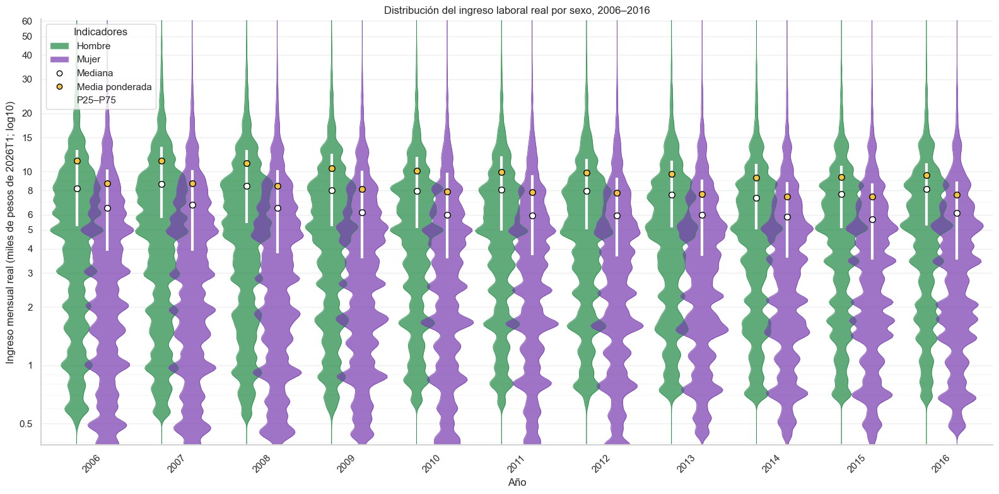

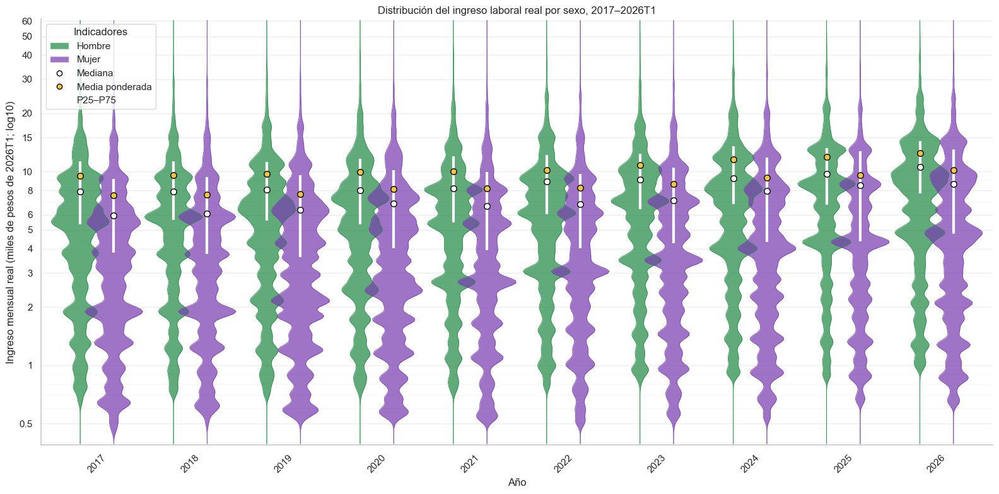

,anio,categoria,n_muestral,peso_total,media,desviacion_estandar,p25,mediana,p75
0,2006,Formal,"299,289.00","65,719,094.00","14,452.23","15,441.19","7,165.56","10,236.51","15,944.22"
1,2006,Informal,"301,090.00","81,192,950.00","7,092.14","7,256.76","3,070.95","5,979.08","8,968.62"
2,2007,Formal,"300,019.00","67,368,825.00","14,428.88","15,999.37","7,670.00","10,519.38","15,886.22"
3,2007,Informal,"296,850.00","81,620,546.00","7,095.66","7,744.49","3,240.79","5,855.21","8,859.62"
4,2008,Formal,"288,678.00","67,032,832.00","13,940.62","14,615.34","7,401.33","10,512.20","15,408.01"
5,2008,Informal,"294,154.00","82,897,523.00","7,024.59","7,641.82","3,273.03","5,629.62","8,991.68"
6,2009,Formal,"263,470.00","64,446,722.00","13,270.52","13,011.94","7,083.79","10,232.17","14,511.85"
7,2009,Informal,"293,218.00","85,438,289.00","6,722.36","7,251.44","3,167.88","5,312.85","8,694.86"
8,2010,Formal,"263,196.00","65,164,238.00","12,941.17","12,714.71","7,045.43","9,895.26","14,314.68"
9,2010,Informal,"295,722.00","86,716,740.00","6,551.90","6,207.98","3,233.77","5,110.45","8,488.12"


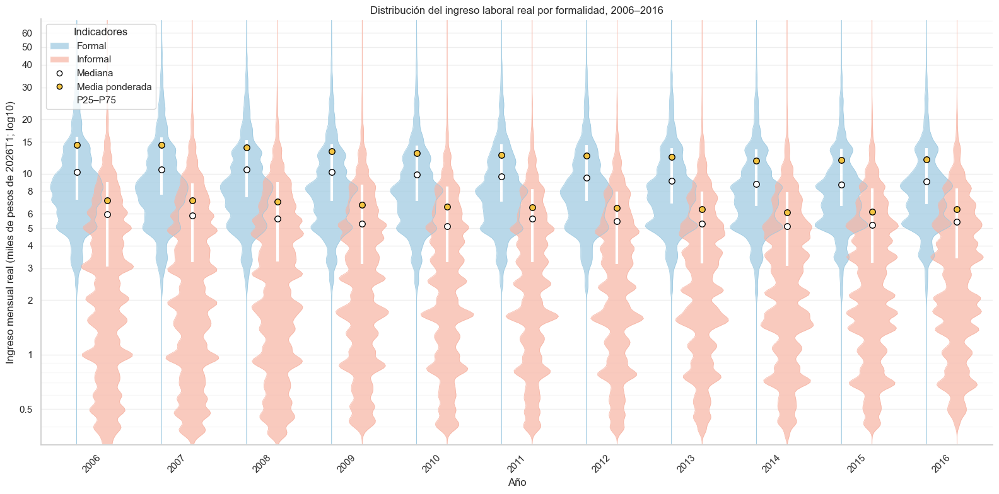

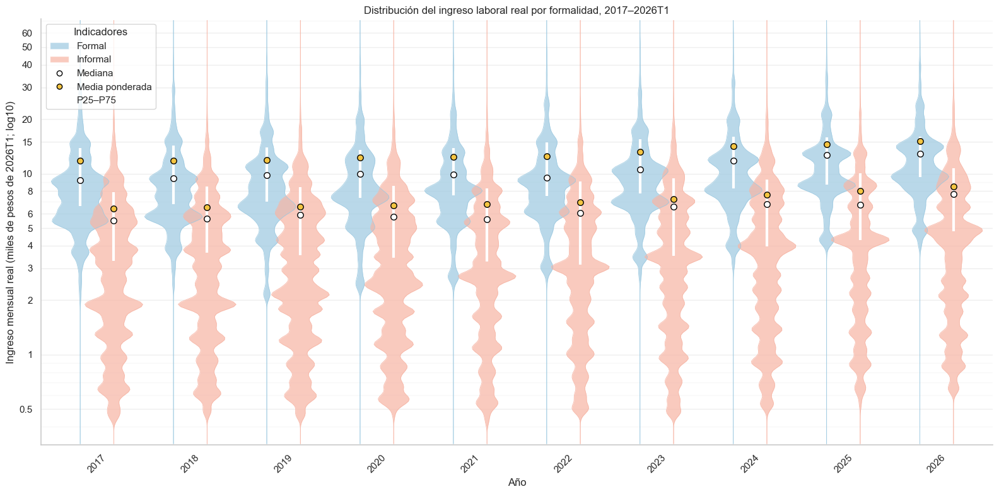

In [23]:
comparaciones_violin = [
    ("sexo", "sexo IN ('Hombre', 'Mujer')", ["Hombre", "Mujer"], COLOR_SEXO, "Distribución del ingreso laboral real por sexo"),
    ("tipo_empleo", "tipo_empleo IN ('Formal', 'Informal')", ["Formal", "Informal"], COLOR_EMPLEO, "Distribución del ingreso laboral real por formalidad")]
estadisticos_violines = {}
for categoria, filtro, categorias, colores, titulo in comparaciones_violin:
    densidad, estadisticos, limites = preparar_violin(categoria, filtro, categorias)
    estadisticos_violines[titulo] = estadisticos; display(estadisticos.round(2))
    graficar_violin(densidad, estadisticos, limites, categorias, colores, titulo, 2006, 2016)
    graficar_violin(densidad, estadisticos, limites, categorias, colores, titulo, 2017, 2026)


## La diferencia por sexo dentro de cada tipo de empleo

Los siguientes violines mantienen fija la formalidad antes de comparar por sexo. Las medianas provienen de cada submuestra y no son promedios de los resultados anteriores.

**Lectura.** En 2026T1 el contraste mensual es $13,545 frente a $12,000 en el empleo formal y $8,600 frente a $5,590 en el informal (hombres y mujeres, respectivamente). La distancia observada es mayor en el informal; no es una estimación de discriminación ni compara trabajos idénticos.

,anio,categoria,n_muestral,peso_total,media,desviacion_estandar,p25,mediana,p75
0,2006,Hombre,"185,910.00","41,340,596.00","15,567.11","17,510.77","7,972.11","10,961.65","16,991.54"
1,2006,Mujer,"113,379.00","24,378,498.00","12,561.63","10,821.34","6,960.83","9,521.15","14,281.72"
2,2007,Hombre,"185,704.00","42,372,057.00","15,532.52","18,011.47","7,875.21","11,347.30","17,565.62"
3,2007,Mujer,"114,315.00","24,996,768.00","12,558.10","11,593.72","6,860.47","9,351.82","13,931.32"
4,2008,Hombre,"177,883.00","42,194,387.00","14,976.69","15,716.53","7,805.31","10,932.69","16,888.85"
5,2008,Mujer,"110,795.00","24,838,445.00","12,180.58","12,326.67","6,603.43","9,251.66","13,877.48"
6,2009,Hombre,"161,907.00","40,306,292.00","14,097.31","14,505.87","7,655.71","10,433.83","15,938.54"
7,2009,Mujer,"101,563.00","24,140,430.00","11,890.07","9,880.51","6,507.21","8,914.42","13,750.01"
8,2010,Hombre,"162,146.00","40,970,293.00","13,738.88","14,227.39","7,639.31","10,185.74","15,331.35"
9,2010,Mujer,"101,050.00","24,193,945.00","11,590.31","9,473.46","6,420.27","8,922.43","13,580.99"


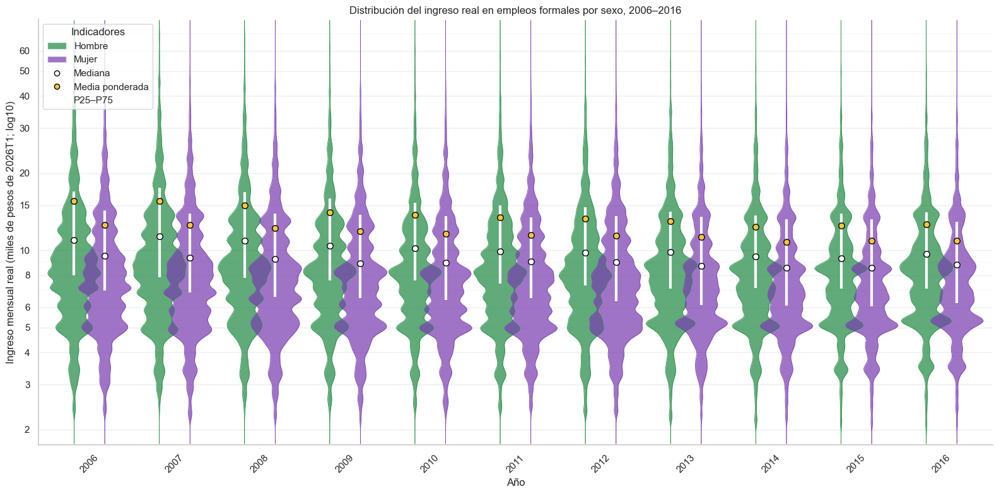

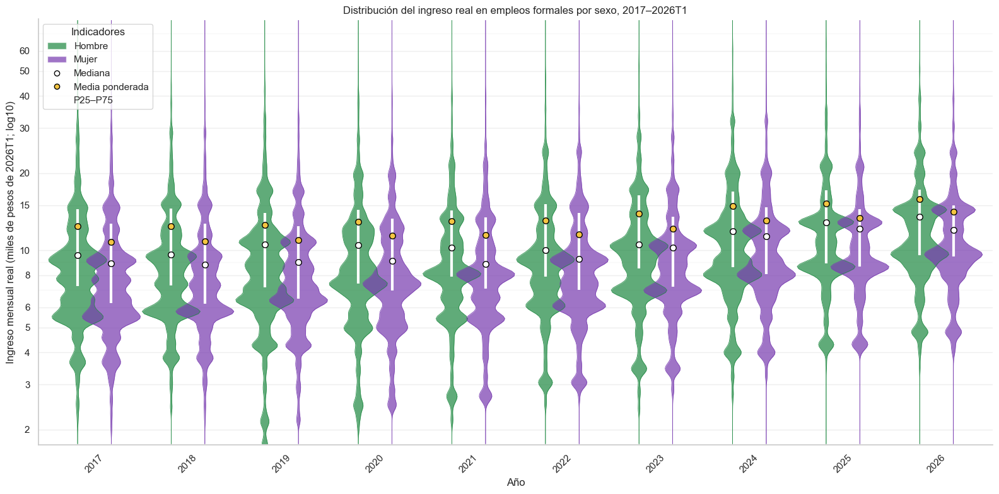

,anio,categoria,n_muestral,peso_total,media,desviacion_estandar,p25,mediana,p75
0,2006,Hombre,"187,657.00","51,886,405.00","8,025.11","7,894.60","4,059.09","6,676.64","9,965.14"
1,2006,Mujer,"113,433.00","29,306,545.00","5,440.34","5,592.94","2,380.58","4,566.48","6,975.60"
2,2007,Hombre,"183,213.00","51,565,958.00","8,047.16","7,915.80","3,937.61","6,831.08","9,833.34"
3,2007,Mujer,"113,637.00","30,054,588.00","5,463.14","7,152.31","2,399.84","4,636.71","6,860.47"
4,2008,Hombre,"181,540.00","52,443,577.00","7,955.14","7,494.29","4,222.21","6,625.44","9,464.92"
5,2008,Mujer,"112,614.00","30,453,946.00","5,422.15","7,627.82","2,366.23","4,622.40","6,603.43"
6,2009,Hombre,"179,971.00","53,590,303.00","7,608.43","7,877.02","4,092.87","6,240.09","8,914.42"
7,2009,Mujer,"113,247.00","31,847,986.00","5,231.39","5,754.49","2,487.75","4,399.83","6,375.41"
8,2010,Hombre,"180,914.00","54,270,971.00","7,380.96","6,768.97","4,005.40","6,366.09","8,728.46"
9,2010,Mujer,"114,808.00","32,445,769.00","5,165.16","4,825.92","2,502.16","4,254.96","6,672.43"


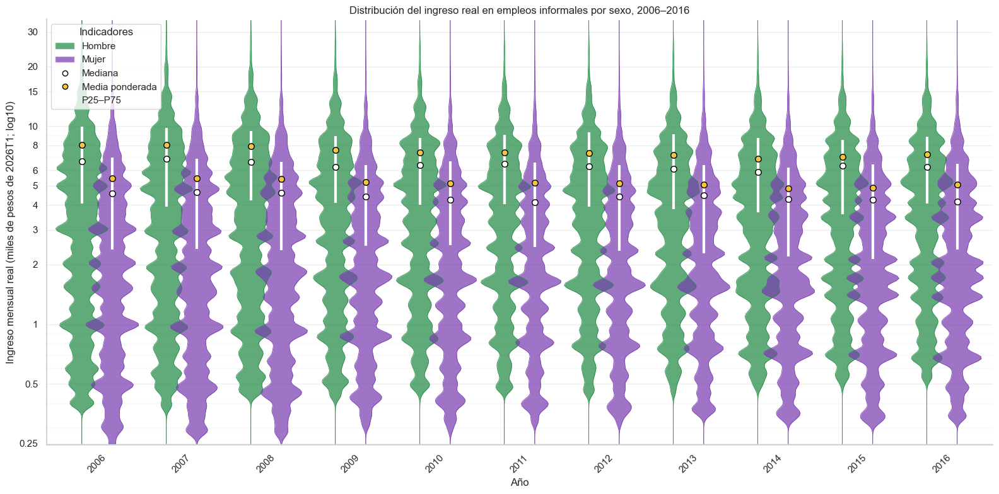

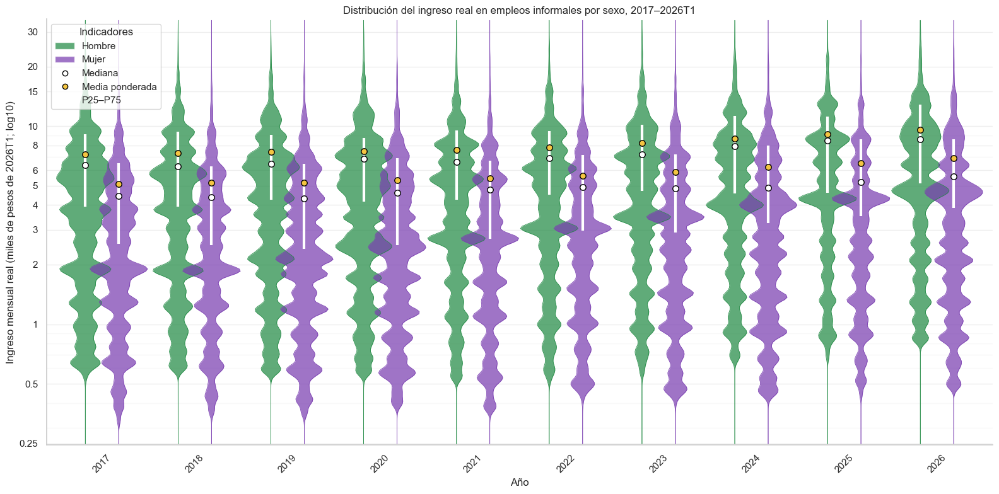

In [24]:
comparaciones_violin_empleo = [
    ("sexo", "tipo_empleo = 'Formal' AND sexo IN ('Hombre', 'Mujer')", ["Hombre", "Mujer"], COLOR_SEXO,
     "Distribución del ingreso real en empleos formales por sexo"),
    ("sexo", "tipo_empleo = 'Informal' AND sexo IN ('Hombre', 'Mujer')", ["Hombre", "Mujer"], COLOR_SEXO,
     "Distribución del ingreso real en empleos informales por sexo")]
for categoria, filtro, categorias, colores, titulo in comparaciones_violin_empleo:
    densidad, estadisticos, limites = preparar_violin(categoria, filtro, categorias)
    estadisticos_violines[titulo] = estadisticos; display(estadisticos.round(2))
    graficar_violin(densidad, estadisticos, limites, categorias, colores, titulo, 2006, 2016)
    graficar_violin(densidad, estadisticos, limites, categorias, colores, titulo, 2017, 2026)


# 5. El mismo ingreso no se distribuye igual en todo el territorio

Se compara la mediana de ingreso mensual positivo por ámbito y sexo, con el mismo deflactor nacional en todos los casos. No se ajusta por diferencias estatales o locales de costo de vida.

**Lectura.** En 2026T1 las mujeres registran 9,460 MXN en el ámbito urbano y 5,375 MXN en el rural; entre los hombres, 11,000 MXN y 7,740 MXN. La distinción urbano–rural aporta información que se pierde en el promedio nacional.

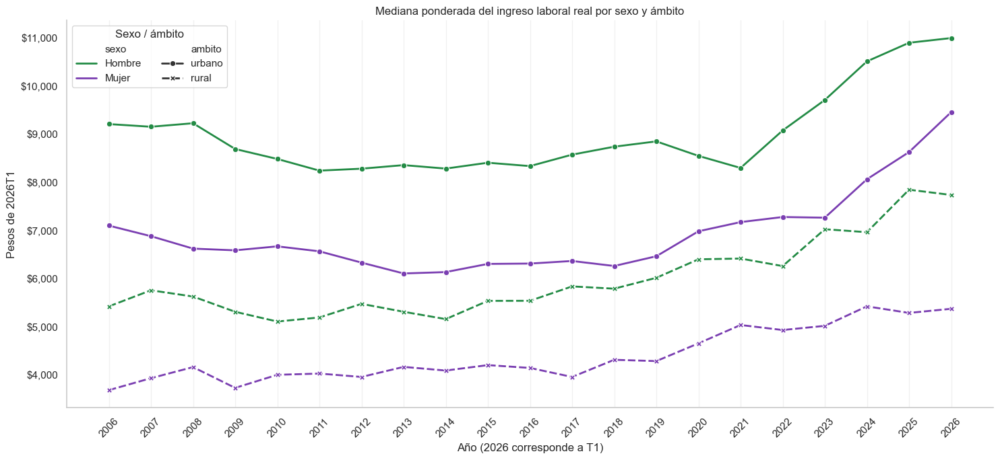

,anio,ambito,sexo,n_muestral,peso_total,media,desviacion_estandar,p25,mediana,p75
0,2006,rural,Hombre,"57,398.00","19,146,659.00","6,529.32","7,046.26","2,989.54","5,424.67","8,188.19"
1,2006,rural,Mujer,"22,501.00","7,352,862.00","4,846.26","5,534.72","1,745.06","3,684.68","6,141.91"
2,2006,urbano,Hombre,"316,169.00","74,080,342.00","12,620.53","14,559.55","6,141.14","9,212.86","14,206.82"
3,2006,urbano,Mujer,"204,311.00","46,332,181.00","9,281.61","9,402.75","4,484.31","7,103.41","11,258.76"
4,2007,rural,Hombre,"56,373.00","18,922,386.00","6,667.02","7,279.97","2,927.60","5,759.61","8,639.42"
...,...,...,...,...,...,...,...,...,...,...
79,2025,urbano,Mujer,"222,564.00","66,083,649.00","10,119.29","8,118.27","4,848.52","8,630.87","12,860.36"
80,2026,rural,Hombre,"15,716.00","6,236,443.00","8,811.77","7,219.03","4,791.00","7,740.00","10,750.00"
81,2026,rural,Mujer,"8,503.00","3,177,963.00","6,668.39","5,272.06","3,225.00","5,375.00","9,000.00"
82,2026,urbano,Hombre,"79,030.00","24,553,217.00","13,407.82","10,049.73","8,600.00","11,000.00","15,000.00"


In [25]:
df_ingreso_ambito = resumen_ponderado(
    "ingreso_laboral_ind_real", ["anio", "ambito", "sexo"],
    "es_ocupado AND factor_valido AND ingreso_laboral_ind_real > 0 "
    "AND sexo IN ('Hombre', 'Mujer') AND ambito IN ('urbano', 'rural') AND periodo <> '2020T2'"
)
fig, ax = plt.subplots(figsize=(15, 7))
sns.lineplot(data=df_ingreso_ambito, x="anio", y="mediana", hue="sexo", style="ambito",
             hue_order=["Hombre", "Mujer"], style_order=["urbano", "rural"], palette=COLOR_SEXO,
             markers=True, dashes=True, linewidth=2, ax=ax)
ax.set(title="Mediana ponderada del ingreso laboral real por sexo y ámbito",
       xlabel="Año (2026 corresponde a T1)", ylabel="Pesos de 2026T1")
ax.yaxis.set_major_formatter(FuncFormatter(formato_pesos)); estilo_linea(ax, sorted(df_ingreso_ambito["anio"].unique()))
ax.legend(title="Sexo / ámbito", ncol=2); plt.tight_layout(); plt.show()
display(df_ingreso_ambito.round(2))


## De la comparación rural–urbana al mapa estatal

Se enlazan las claves estatales con sus nombres y se calculan por separado las medianas mensuales y por hora de cada combinación de sexo y empleo. La tabla conserva el número de registros para valorar la base de cada comparación.

**Lectura.** En Aguascalientes, durante 2006–2010, los hombres en empleo formal registran 10,009 MXN al mes y 47.92 MXN por hora; en informal, 7,166 MXN y 35.27 MXN. Es una comparación dentro de la misma entidad y periodo, no un ranking nacional.

In [26]:
ENTIDADES = {
    "01": "Aguascalientes", "02": "Baja California", "03": "Baja California Sur", "04": "Campeche",
    "05": "Coahuila", "06": "Colima", "07": "Chiapas", "08": "Chihuahua", "09": "Ciudad de México",
    "10": "Durango", "11": "Guanajuato", "12": "Guerrero", "13": "Hidalgo", "14": "Jalisco",
    "15": "México", "16": "Michoacán", "17": "Morelos", "18": "Nayarit", "19": "Nuevo León",
    "20": "Oaxaca", "21": "Puebla", "22": "Querétaro", "23": "Quintana Roo", "24": "San Luis Potosí",
    "25": "Sinaloa", "26": "Sonora", "27": "Tabasco", "28": "Tamaulipas", "29": "Tlaxcala",
    "30": "Veracruz", "31": "Yucatán", "32": "Zacatecas"
}
filtro_estado = ("es_ocupado AND factor_valido AND ingreso_laboral_ind_real > 0 "
                 "AND sexo IN ('Hombre', 'Mujer') AND tipo_empleo IN ('Formal', 'Informal') "
                 "AND cve_ent BETWEEN '01' AND '32' AND periodo <> '2020T2'")
df_estado_ingreso = resumen_ponderado(
    "ingreso_laboral_ind_real", ["periodo_analisis", "cve_ent", "sexo", "tipo_empleo"], filtro_estado
)
df_estado_hora = resumen_ponderado(
    "ingreso_hora_real", ["periodo_analisis", "cve_ent", "sexo", "tipo_empleo"],
    filtro_estado + " AND ingreso_hora_real > 0"
)
for df in [df_estado_ingreso, df_estado_hora]:
    df["entidad"] = df["cve_ent"].map(ENTIDADES)
display(df_estado_ingreso.round(2), df_estado_hora.round(2))


,periodo_analisis,cve_ent,sexo,tipo_empleo,n_muestral,peso_total,media,desviacion_estandar,p25,mediana,p75,entidad
0,2006–2010,01,Hombre,Formal,"24,679.00","2,231,189.00","13,609.19","12,909.09","7,658.93","10,008.64","14,638.02",Aguascalientes
1,2006–2010,01,Hombre,Informal,"22,089.00","1,872,475.00","8,147.13","6,615.89","5,004.32","7,165.56","9,599.35",Aguascalientes
2,2006–2010,01,Mujer,Formal,"14,796.00","1,340,474.00","11,355.14","8,980.97","6,255.40","8,570.10","13,179.15",Aguascalientes
3,2006–2010,01,Mujer,Informal,"13,197.00","1,161,203.00","5,460.21","4,636.73","2,879.81","4,850.66","6,790.50",Aguascalientes
4,2006–2010,02,Hombre,Formal,"36,905.00","8,793,019.00","16,713.92","13,565.58","9,212.86","12,783.34","19,517.36",Baja California
...,...,...,...,...,...,...,...,...,...,...,...,...
635,2026T1,31,Mujer,Informal,"1,291.00","293,274.00","5,799.42","5,309.83","2,150.00","4,791.00","8,000.00",Yucatán
636,2026T1,32,Hombre,Formal,"1,177.00","131,570.00","13,498.48","8,361.50","9,400.00","10,800.00","15,000.00",Zacatecas
637,2026T1,32,Hombre,Informal,"1,277.00","220,953.00","8,930.09","5,459.93","4,791.00","8,600.00","10,750.00",Zacatecas
638,2026T1,32,Mujer,Formal,935.00,"101,240.00","11,588.35","5,653.62","8,600.00","9,890.00","14,373.00",Zacatecas


,periodo_analisis,cve_ent,sexo,tipo_empleo,n_muestral,peso_total,media,desviacion_estandar,p25,mediana,p75,entidad
0,2006–2010,01,Hombre,Formal,"23,870.00","2,160,003.00",69.50,76.31,34.76,47.92,75.71,Aguascalientes
1,2006–2010,01,Hombre,Informal,"21,807.00","1,848,346.00",45.70,53.09,25.97,35.27,49.87,Aguascalientes
2,2006–2010,01,Mujer,Formal,"13,971.00","1,267,195.00",70.79,71.03,32.33,47.89,85.56,Aguascalientes
3,2006–2010,01,Mujer,Informal,"12,997.00","1,143,375.00",46.27,46.17,23.91,34.63,52.37,Aguascalientes
4,2006–2010,02,Hombre,Formal,"36,109.00","8,602,798.00",85.24,77.83,44.65,62.00,99.04,Baja California
...,...,...,...,...,...,...,...,...,...,...,...,...
635,2026T1,31,Mujer,Informal,"1,242.00","282,210.00",61.81,80.54,25.84,41.67,66.67,Yucatán
636,2026T1,32,Hombre,Formal,"1,113.00","125,745.00",68.62,48.41,40.70,55.71,83.33,Zacatecas
637,2026T1,32,Hombre,Informal,"1,253.00","216,526.00",57.86,51.79,35.37,45.48,62.50,Zacatecas
638,2026T1,32,Mujer,Formal,859.00,"92,785.00",66.90,40.25,42.22,54.05,81.40,Zacatecas


## Mapa mensual: dónde cambia el nivel de ingreso

Cada entidad recibe la mediana ponderada de todos sus ocupados con ingreso positivo en ese periodo. Los cuatro lustros comparten escala con 2026T1. Los tonos se saturan en P2/P98 de las medianas estatales de la figura: para los extremos se consulta la tabla.

**Lectura.** En 2006–2010, Baja California registra 10,429 MXN y Aguascalientes 7,970 MXN. En 2026T1, Yucatán y Zacatecas coinciden en 9,030 MXN. Un mismo color implica un nivel parecido en esta figura, no igualdad de toda la distribución.

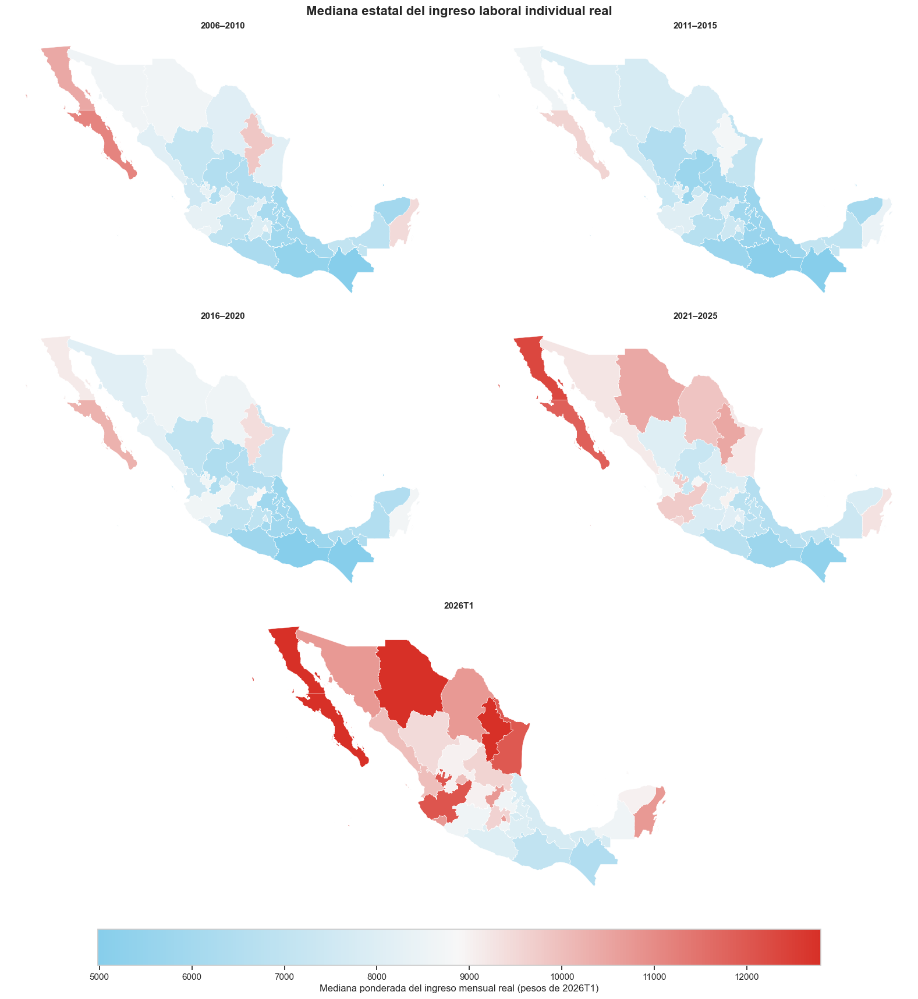

,periodo_analisis,cve_ent,n_muestral,peso_total,media,desviacion_estandar,p25,mediana,p75
0,2006–2010,01,"74,761.00","6,605,341.00","10,170.81","9,908.88","5,502.86","7,969.69","11,843.89"
1,2006–2010,02,"98,815.00","22,837,757.00","13,557.02","11,524.61","7,875.21","10,428.63","15,650.75"
2,2006–2010,03,"75,881.00","4,956,423.00","14,589.88","19,088.07","7,130.86","11,123.87","17,212.38"
3,2006–2010,04,"89,779.00","6,068,968.00","9,889.32","11,951.07","3,829.47","6,813.93","11,800.00"
4,2006–2010,05,"97,131.00","19,797,365.00","11,006.13","12,223.63","5,550.99","8,088.24","12,379.04"
...,...,...,...,...,...,...,...,...,...
155,2026T1,28,"6,159.00","1,509,412.00","12,670.28","9,969.01","7,740.00","12,000.00","14,373.00"
156,2026T1,29,"4,331.00","523,407.00","8,696.69","6,278.38","4,791.00","7,740.00","10,750.00"
157,2026T1,30,"6,631.00","2,938,079.00","8,826.75","7,235.67","4,791.00","7,740.00","10,750.00"
158,2026T1,31,"5,011.00","1,125,933.00","10,486.18","8,717.83","5,160.00","9,030.00","12,900.00"


In [27]:
from matplotlib.colors import LinearSegmentedColormap, Normalize

# Escala común: menor mediana = azul cielo; mayor mediana = rojo.
CMAP_INGRESO = LinearSegmentedColormap.from_list(
    "azul_cielo_a_rojo",
    ["#87CEEB", "#F7F7F7", "#D73027"]
)

def preparar_geometria_entidades():
    if gpd is None:
        raise ImportError("Instala geopandas para habilitar los mapas: pip install geopandas")
    if not RUTA_ENTIDADES.exists():
        raise FileNotFoundError(f"No se encontró el GeoJSON: {RUTA_ENTIDADES}")

    geo = gpd.read_file(RUTA_ENTIDADES)
    clave = next(
        (c for c in ["CVE_ENT", "CVEGEO", "cve_ent", "cvegeo"] if c in geo.columns),
        None
    )
    if clave is None:
        raise ValueError("El GeoJSON debe contener CVE_ENT, CVEGEO, cve_ent o cvegeo.")

    geo["cve_ent"] = geo[clave].astype(str).str.zfill(2).str[:2]
    return geo

def limites_color(datos, columna):
    valores = datos[columna].dropna()
    vmin, vmax = valores.quantile([0.02, 0.98])

    # Evita problemas si la distribución fuera prácticamente constante.
    if vmin == vmax:
        vmin, vmax = valores.min(), valores.max()

    return float(vmin), float(vmax)

def dibujar_mapa(ax, geo, datos, valor, vmin, vmax, titulo):
    panel = geo.merge(datos[["cve_ent", valor]], on="cve_ent", how="left")

    panel.plot(
        column=valor,
        cmap=CMAP_INGRESO,
        vmin=vmin,
        vmax=vmax,
        linewidth=0.35,
        edgecolor="white",
        missing_kwds={"color": "#EFEFEF", "label": "Sin datos"},
        ax=ax,
    )
    ax.set_title(titulo, fontsize=11, fontweight="bold")
    ax.axis("off")

geo_entidades = preparar_geometria_entidades()

# La mediana se recalcula sobre microdatos y factores de expansión;
# no se obtiene promediando las medianas de sexo o formalidad.
df_mapa_ingreso_total = resumen_ponderado(
    "ingreso_laboral_ind_real",
    ["periodo_analisis", "cve_ent"],
    """
        es_ocupado
        AND factor_valido
        AND fac_tri > 0
        AND ingreso_laboral_ind_real > 0
        AND periodo <> '2020T2'
    """
)

df_mapa_ingreso_total["periodo_analisis"] = pd.Categorical(
    df_mapa_ingreso_total["periodo_analisis"],
    ORDEN_PERIODOS,
    ordered=True
)

vmin, vmax = limites_color(df_mapa_ingreso_total, "mediana")

# Cuadrícula: cuatro lustros en 2 × 2 y 2026T1 a todo lo ancho.
fig = plt.figure(figsize=(16, 17), layout="constrained")
grid = fig.add_gridspec(
    nrows=3,
    ncols=2,
    height_ratios=[1, 1, 1.05]
)

axes_periodos = {
    "2006–2010": fig.add_subplot(grid[0, 0]),
    "2011–2015": fig.add_subplot(grid[0, 1]),
    "2016–2020": fig.add_subplot(grid[1, 0]),
    "2021–2025": fig.add_subplot(grid[1, 1]),
    "2026T1": fig.add_subplot(grid[2, :]),  # ocupa ambas columnas
}

for periodo, ax in axes_periodos.items():
    datos = df_mapa_ingreso_total.query("periodo_analisis == @periodo")

    dibujar_mapa(
        ax,
        geo_entidades,
        datos,
        "mediana",
        vmin,
        vmax,
        periodo
    )

sm = plt.cm.ScalarMappable(
    cmap=CMAP_INGRESO,
    norm=Normalize(vmin=vmin, vmax=vmax)
)
sm.set_array([])

fig.colorbar(
    sm,
    ax=list(axes_periodos.values()),
    orientation="horizontal",
    shrink=0.78,
    pad=0.03,
    label="Mediana ponderada del ingreso mensual real (pesos de 2026T1)"
)

fig.suptitle(
    "Mediana estatal del ingreso laboral individual real",
    fontsize=16,
    fontweight="bold"
)

plt.show()

display(
    df_mapa_ingreso_total.sort_values(["periodo_analisis", "cve_ent"]).round(2)
)


## Mapa mensual por sexo: cambia el denominador

Se calcula la mediana dentro de cada entidad, periodo y sexo. La escala es común a los paneles de esta figura, pero se recalcula respecto de la figura anterior.

**Lectura.** En 2026T1 la mediana femenina es 7,740 MXN en Yucatán y 8,300 MXN en Zacatecas. El empate del mapa total no se conserva en este subconjunto: el centro del total no se obtiene promediando las dos medianas por sexo.

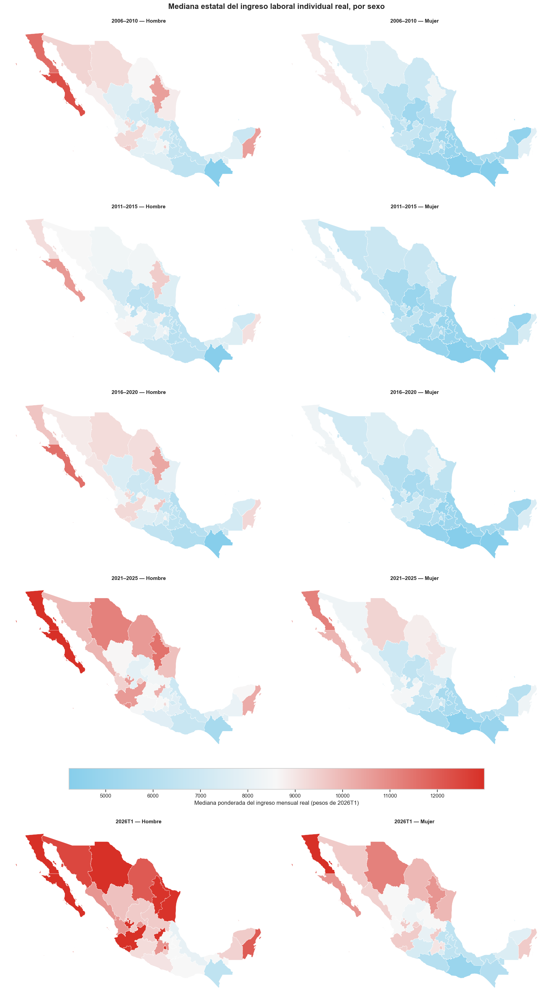

,periodo_analisis,cve_ent,sexo,n_muestral,peso_total,media,desviacion_estandar,p25,mediana,p75
0,2006–2010,01,Hombre,"46,768.00","4,103,664.00","11,116.89","10,861.83","6,240.09","8,509.92","12,488.49"
2,2006–2010,02,Hombre,"61,512.00","14,083,211.00","14,728.50","12,051.64","8,488.12","11,588.75","17,251.14"
4,2006–2010,03,Hombre,"48,603.00","3,202,880.00","15,933.88","18,818.98","8,232.56","12,283.82","18,658.09"
6,2006–2010,04,Hombre,"56,599.00","3,981,750.00","10,875.45","13,055.93","4,303.10","7,616.92","12,438.73"
8,2006–2010,05,Hombre,"63,424.00","12,911,217.00","12,012.90","13,577.15","6,141.14","8,639.42","12,952.32"
...,...,...,...,...,...,...,...,...,...,...
311,2026T1,28,Mujer,"2,501.00","612,964.00","11,039.95","7,955.01","6,450.00","10,000.00","13,410.00"
313,2026T1,29,Mujer,"1,745.00","210,386.00","7,313.09","5,365.00","4,000.00","6,020.00","9,582.00"
315,2026T1,30,Mujer,"2,709.00","1,113,484.00","7,656.64","6,086.23","3,870.00","6,450.00","9,582.00"
317,2026T1,31,Mujer,"2,100.00","468,310.00","8,799.30","8,326.54","3,870.00","7,740.00","10,750.00"


In [28]:
# Mediana ponderada estatal del ingreso laboral individual real,
# desagregada por sexo y por lustro.
df_mapa_ingreso_sexo = resumen_ponderado(
    "ingreso_laboral_ind_real",
    ["periodo_analisis", "cve_ent", "sexo"],
    """
        es_ocupado
        AND factor_valido
        AND fac_tri > 0
        AND ingreso_laboral_ind_real > 0
        AND sexo IN ('Hombre', 'Mujer')
        AND periodo <> '2020T2'
    """
)

df_mapa_ingreso_sexo["periodo_analisis"] = pd.Categorical(
    df_mapa_ingreso_sexo["periodo_analisis"],
    categories=ORDEN_PERIODOS,
    ordered=True
)

vmin, vmax = limites_color(df_mapa_ingreso_sexo, "mediana")

# Cuatro lustros: 2 columnas × 2 filas.
# 2026T1: renglón inferior de ancho completo, dividido en Hombre/Mujer.
fig = plt.figure(figsize=(16, 29), layout="constrained")
grid = fig.add_gridspec(
    nrows=5,
    ncols=2,
    height_ratios=[1, 1, 1, 1, 1.05]
)

axes_periodos = {
    "2006–2010": [
        fig.add_subplot(grid[0, 0]),
        fig.add_subplot(grid[0, 1]),
    ],
    "2011–2015": [
        fig.add_subplot(grid[1, 0]),
        fig.add_subplot(grid[1, 1]),
    ],
    "2016–2020": [
        fig.add_subplot(grid[2, 0]),
        fig.add_subplot(grid[2, 1]),
    ],
    "2021–2025": [
        fig.add_subplot(grid[3, 0]),
        fig.add_subplot(grid[3, 1]),
    ],
}

grid_2026 = grid[4, :].subgridspec(1, 2)
axes_periodos["2026T1"] = [
    fig.add_subplot(grid_2026[0, 0]),
    fig.add_subplot(grid_2026[0, 1]),
]

for periodo, axes_sexo in axes_periodos.items():
    for ax, sexo in zip(axes_sexo, ["Hombre", "Mujer"]):
        datos = df_mapa_ingreso_sexo.query(
            "periodo_analisis == @periodo and sexo == @sexo"
        )

        dibujar_mapa(
            ax=ax,
            geo=geo_entidades,
            datos=datos,
            valor="mediana",
            vmin=vmin,
            vmax=vmax,
            titulo=f"{periodo} — {sexo}"
        )

sm = plt.cm.ScalarMappable(
    cmap=CMAP_INGRESO,
    norm=Normalize(vmin=vmin, vmax=vmax)
)
sm.set_array([])

fig.colorbar(
    sm,
    ax=[ax for lista in axes_periodos.values() for ax in lista],
    orientation="horizontal",
    shrink=0.76,
    pad=0.02,
    label="Mediana ponderada del ingreso mensual real (pesos de 2026T1)"
)

fig.suptitle(
    "Mediana estatal del ingreso laboral individual real, por sexo",
    fontsize=16,
    fontweight="bold"
)

plt.show()

display(
    df_mapa_ingreso_sexo.sort_values(
        ["periodo_analisis", "sexo", "cve_ent"]
    ).round(2)
)

## Mapa mensual por sexo y formalidad: cuatro mercados en un estado

Se estima cada grupo directamente a partir de sus observaciones. Una fila corresponde a un periodo y se deben comparar las cuatro columnas usando su barra de color común.

**Lectura.** En Zacatecas, las medianas femeninas de 2026T1 son 9,890 MXN en empleo formal y 5,000 MXN en informal. La diferencia dentro del estado es relevante aun cuando el mapa nacional solo muestre una cifra para Zacatecas.

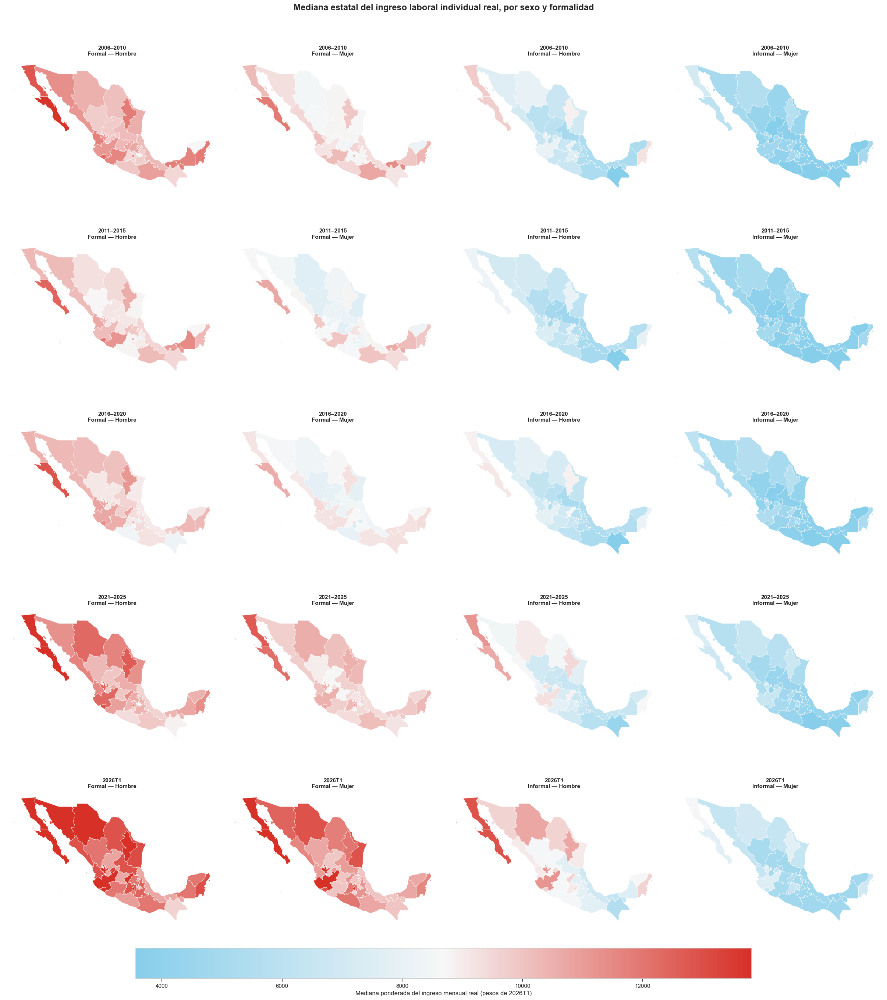

,periodo_analisis,cve_ent,sexo,tipo_empleo,n_muestral,peso_total,media,desviacion_estandar,p25,mediana,p75
0,2006–2010,01,Hombre,Formal,"24,679.00","2,231,189.00","13,609.19","12,909.09","7,658.93","10,008.64","14,638.02"
4,2006–2010,02,Hombre,Formal,"36,905.00","8,793,019.00","16,713.92","13,565.58","9,212.86","12,783.34","19,517.36"
8,2006–2010,03,Hombre,Formal,"29,697.00","1,969,222.00","18,236.94","19,645.17","9,310.36","13,720.93","21,118.57"
12,2006–2010,04,Hombre,Formal,"26,422.00","1,733,485.00","16,709.52","16,761.72","7,775.20","11,637.95","18,950.22"
16,2006–2010,05,Hombre,Formal,"39,569.00","8,032,969.00","14,584.54","15,774.58","7,506.16","10,091.71","15,278.61"
...,...,...,...,...,...,...,...,...,...,...,...
623,2026T1,28,Mujer,Informal,"1,113.00","282,566.00","7,531.85","7,674.03","4,000.00","6,450.00","8,600.00"
627,2026T1,29,Mujer,Informal,"1,262.00","150,664.00","5,642.71","4,154.19","3,010.00","4,791.00","7,000.00"
631,2026T1,30,Mujer,Informal,"1,713.00","793,734.00","5,839.60","4,770.53","2,580.00","4,791.00","7,740.00"
635,2026T1,31,Mujer,Informal,"1,291.00","293,274.00","5,799.42","5,309.83","2,150.00","4,791.00","8,000.00"


In [29]:
# Mediana ponderada estatal del ingreso laboral individual real,
# desagregada por sexo, formalidad y lustro.
df_mapa_ingreso_sexo_empleo = resumen_ponderado(
    "ingreso_laboral_ind_real",
    ["periodo_analisis", "cve_ent", "sexo", "tipo_empleo"],
    """
        es_ocupado
        AND factor_valido
        AND fac_tri > 0
        AND ingreso_laboral_ind_real > 0
        AND sexo IN ('Hombre', 'Mujer')
        AND tipo_empleo IN ('Formal', 'Informal')
        AND periodo <> '2020T2'
    """
)

df_mapa_ingreso_sexo_empleo["periodo_analisis"] = pd.Categorical(
    df_mapa_ingreso_sexo_empleo["periodo_analisis"],
    categories=ORDEN_PERIODOS,
    ordered=True
)

vmin, vmax = limites_color(df_mapa_ingreso_sexo_empleo, "mediana")

combinaciones = [
    ("Formal", "Hombre"),
    ("Formal", "Mujer"),
    ("Informal", "Hombre"),
    ("Informal", "Mujer"),
]

# Cada fila corresponde a un período y cada columna a una combinación
# de formalidad y sexo.
fig, axes = plt.subplots(
    nrows=len(ORDEN_PERIODOS),
    ncols=len(combinaciones),
    figsize=(24, 27),
    layout="constrained"
)

for fila, periodo in enumerate(ORDEN_PERIODOS):
    for columna, (empleo, sexo) in enumerate(combinaciones):
        ax = axes[fila, columna]

        datos = df_mapa_ingreso_sexo_empleo.loc[
        (df_mapa_ingreso_sexo_empleo["periodo_analisis"] == periodo)
        & (df_mapa_ingreso_sexo_empleo["tipo_empleo"] == empleo)
        & (df_mapa_ingreso_sexo_empleo["sexo"] == sexo)
        ].copy()

        dibujar_mapa(
            ax=ax,
            geo=geo_entidades,
            datos=datos,
            valor="mediana",
            vmin=vmin,
            vmax=vmax,
            titulo=f"{periodo}\n{empleo} — {sexo}"
        )

sm = plt.cm.ScalarMappable(
    cmap=CMAP_INGRESO,
    norm=Normalize(vmin=vmin, vmax=vmax)
)
sm.set_array([])

fig.colorbar(
    sm,
    ax=axes.ravel().tolist(),
    orientation="horizontal",
    shrink=0.70,
    pad=0.02,
    label="Mediana ponderada del ingreso mensual real (pesos de 2026T1)"
)

fig.suptitle(
    "Mediana estatal del ingreso laboral individual real, por sexo y formalidad",
    fontsize=17,
    fontweight="bold"
)

plt.show()

display(
    df_mapa_ingreso_sexo_empleo.sort_values(
        ["periodo_analisis", "tipo_empleo", "sexo", "cve_ent"]
    ).round(2)
)

## Mapa por hora: ¿se mantiene el patrón al descontar jornada?

Se vuelve a agrupar por entidad y periodo, esta vez con el ingreso individual real **por hora**. Cambian tanto las unidades como el universo: se requieren horas válidas.

**Lectura.** En 2006–2010, Baja California registra 55.42 MXN por hora y Aguascalientes 41.18 MXN. En 2026T1, Yucatán y Zacatecas, empatados en ingreso mensual, registran 50.64 MXN y 48.78 MXN por hora. Las dos medidas responden a preguntas distintas.

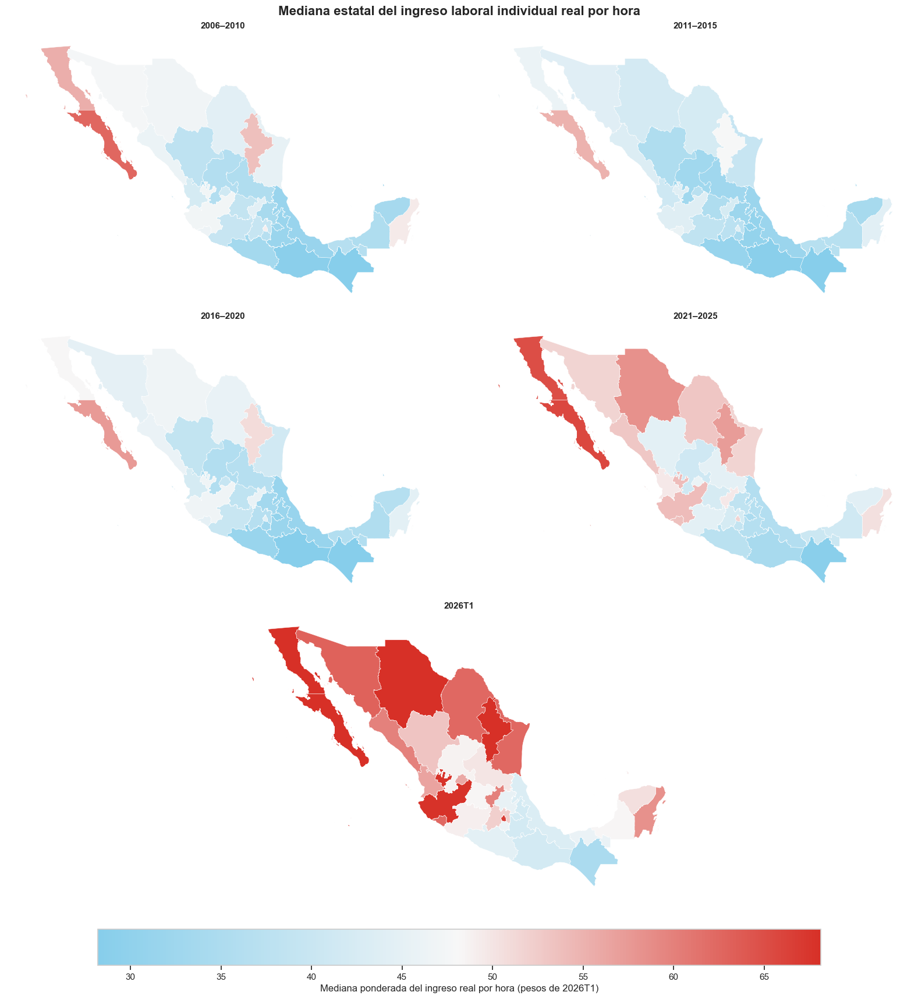

,periodo_analisis,cve_ent,n_muestral,peso_total,media,desviacion_estandar,p25,mediana,p75
0,2006–2010,01,"72,645.00","6,418,919.00",58.76,65.51,29.32,41.18,64.60
1,2006–2010,02,"96,365.00","22,251,501.00",77.07,80.39,40.95,55.42,87.47
2,2006–2010,03,"72,368.00","4,734,851.00",91.80,144.63,40.06,62.60,101.64
3,2006–2010,04,"85,892.00","5,817,420.00",55.46,70.95,22.47,35.45,61.47
4,2006–2010,05,"93,100.00","19,030,201.00",67.45,88.72,31.21,44.53,71.48
...,...,...,...,...,...,...,...,...,...
155,2026T1,28,"5,906.00","1,452,312.00",76.39,64.60,44.64,62.50,85.71
156,2026T1,29,"4,244.00","511,821.00",52.80,47.59,28.57,41.67,60.00
157,2026T1,30,"6,358.00","2,832,386.00",61.21,89.86,31.25,43.26,65.54
158,2026T1,31,"4,813.00","1,081,551.00",71.11,77.43,35.71,50.64,80.00


In [30]:
df_mapa_hora_total = resumen_ponderado(
    "ingreso_hora_real",
    ["periodo_analisis", "cve_ent"],
    """
        es_ocupado
        AND factor_valido
        AND fac_tri > 0
        AND ingreso_hora_real > 0
        AND periodo <> '2020T2'
    """
)

df_mapa_hora_total["periodo_analisis"] = pd.Categorical(
    df_mapa_hora_total["periodo_analisis"],
    categories=ORDEN_PERIODOS,
    ordered=True
)

vmin, vmax = limites_color(df_mapa_hora_total, "mediana")

# Cuatro lustros en 2 × 2; 2026T1 ocupa el ancho de ambas columnas.
fig = plt.figure(figsize=(16, 17), layout="constrained")
grid = fig.add_gridspec(3, 2, height_ratios=[1, 1, 1.05])

axes_periodos = {
    "2006–2010": fig.add_subplot(grid[0, 0]),
    "2011–2015": fig.add_subplot(grid[0, 1]),
    "2016–2020": fig.add_subplot(grid[1, 0]),
    "2021–2025": fig.add_subplot(grid[1, 1]),
    "2026T1": fig.add_subplot(grid[2, :]),
}

for periodo, ax in axes_periodos.items():
    datos = df_mapa_hora_total.loc[
        df_mapa_hora_total["periodo_analisis"] == periodo
    ].copy()

    dibujar_mapa(
        ax=ax,
        geo=geo_entidades,
        datos=datos,
        valor="mediana",
        vmin=vmin,
        vmax=vmax,
        titulo=periodo
    )

sm = plt.cm.ScalarMappable(
    cmap=CMAP_INGRESO,
    norm=Normalize(vmin=vmin, vmax=vmax)
)
sm.set_array([])

fig.colorbar(
    sm,
    ax=list(axes_periodos.values()),
    orientation="horizontal",
    shrink=0.78,
    pad=0.03,
    label="Mediana ponderada del ingreso real por hora (pesos de 2026T1)"
)

fig.suptitle(
    "Mediana estatal del ingreso laboral individual real por hora",
    fontsize=16,
    fontweight="bold"
)

plt.show()

display(
    df_mapa_hora_total.sort_values(
        ["periodo_analisis", "cve_ent"]
    ).round(2)
)

## Mapa por hora y sexo: comparar personas con horas observadas

Se calculan medianas por entidad, periodo y sexo y se usa una sola escala para los diez paneles. No se comparan tonos directamente con los mapas en pesos mensuales.

**Lectura.** En 2026T1 las mujeres registran 49.52 MXN por hora en Yucatán y 48.44 MXN en Zacatecas: el orden se invierte frente a su comparación mensual. La inversión describe jornadas y composiciones distintas; no identifica por sí sola el mecanismo.

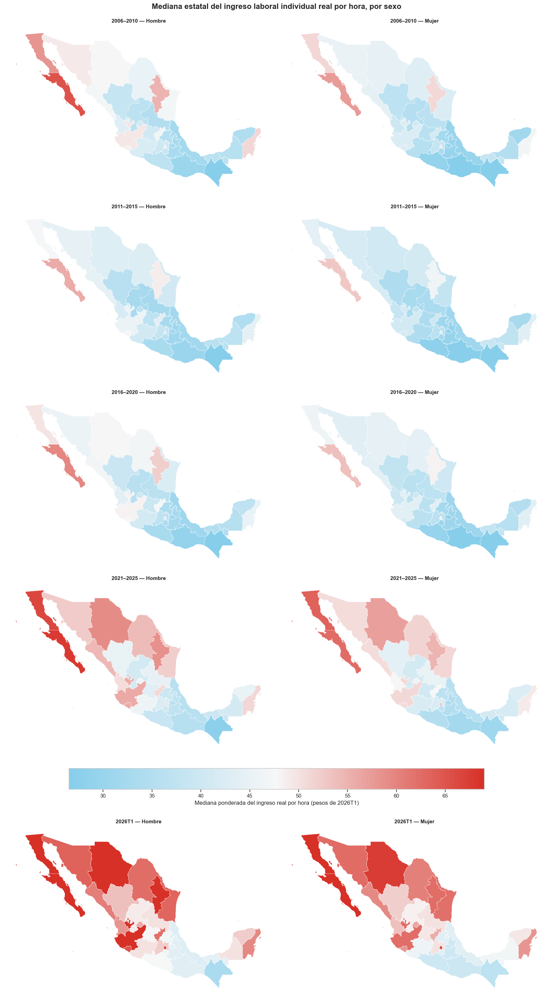

,periodo_analisis,cve_ent,sexo,n_muestral,peso_total,media,desviacion_estandar,p25,mediana,p75
0,2006–2010,01,Hombre,"45,677.00","4,008,349.00",58.52,67.67,30.02,41.27,62.76
2,2006–2010,02,Hombre,"60,231.00","13,787,154.00",79.10,80.69,42.45,58.19,89.65
4,2006–2010,03,Hombre,"46,539.00","3,075,664.00",93.95,136.60,41.71,65.19,104.82
6,2006–2010,04,Hombre,"54,353.00","3,825,109.00",54.95,70.11,22.63,35.65,59.78
8,2006–2010,05,Hombre,"61,075.00","12,463,207.00",68.17,93.51,31.98,45.20,70.51
...,...,...,...,...,...,...,...,...,...,...
311,2026T1,28,Mujer,"2,388.00","587,060.00",74.47,58.38,43.31,62.02,83.56
313,2026T1,29,Mujer,"1,696.00","203,680.00",49.70,39.98,25.45,39.22,57.78
315,2026T1,30,Mujer,"2,596.00","1,064,915.00",63.12,87.74,30.00,43.75,69.44
317,2026T1,31,Mujer,"2,006.00","447,198.00",71.83,87.17,32.76,49.52,81.40


In [31]:
df_mapa_hora_sexo = resumen_ponderado(
    "ingreso_hora_real",
    ["periodo_analisis", "cve_ent", "sexo"],
    """
        es_ocupado
        AND factor_valido
        AND fac_tri > 0
        AND ingreso_hora_real > 0
        AND sexo IN ('Hombre', 'Mujer')
        AND periodo <> '2020T2'
    """
)

df_mapa_hora_sexo["periodo_analisis"] = pd.Categorical(
    df_mapa_hora_sexo["periodo_analisis"],
    categories=ORDEN_PERIODOS,
    ordered=True
)

vmin, vmax = limites_color(df_mapa_hora_sexo, "mediana")

# Cada lustro muestra Hombre y Mujer; 2026T1 ocupa el renglón final.
fig = plt.figure(figsize=(16, 29), layout="constrained")
grid = fig.add_gridspec(
    nrows=5,
    ncols=2,
    height_ratios=[1, 1, 1, 1, 1.05]
)

axes_periodos = {
    "2006–2010": [
        fig.add_subplot(grid[0, 0]),
        fig.add_subplot(grid[0, 1]),
    ],
    "2011–2015": [
        fig.add_subplot(grid[1, 0]),
        fig.add_subplot(grid[1, 1]),
    ],
    "2016–2020": [
        fig.add_subplot(grid[2, 0]),
        fig.add_subplot(grid[2, 1]),
    ],
    "2021–2025": [
        fig.add_subplot(grid[3, 0]),
        fig.add_subplot(grid[3, 1]),
    ],
}

grid_2026 = grid[4, :].subgridspec(1, 2)
axes_periodos["2026T1"] = [
    fig.add_subplot(grid_2026[0, 0]),
    fig.add_subplot(grid_2026[0, 1]),
]

for periodo, axes_sexo in axes_periodos.items():
    for ax, sexo_actual in zip(axes_sexo, ["Hombre", "Mujer"]):
        datos = df_mapa_hora_sexo.loc[
            (df_mapa_hora_sexo["periodo_analisis"] == periodo)
            & (df_mapa_hora_sexo["sexo"] == sexo_actual)
        ].copy()

        dibujar_mapa(
            ax=ax,
            geo=geo_entidades,
            datos=datos,
            valor="mediana",
            vmin=vmin,
            vmax=vmax,
            titulo=f"{periodo} — {sexo_actual}"
        )

sm = plt.cm.ScalarMappable(
    cmap=CMAP_INGRESO,
    norm=Normalize(vmin=vmin, vmax=vmax)
)
sm.set_array([])

fig.colorbar(
    sm,
    ax=[ax for lista in axes_periodos.values() for ax in lista],
    orientation="horizontal",
    shrink=0.76,
    pad=0.02,
    label="Mediana ponderada del ingreso real por hora (pesos de 2026T1)"
)

fig.suptitle(
    "Mediana estatal del ingreso laboral individual real por hora, por sexo",
    fontsize=16,
    fontweight="bold"
)

plt.show()

display(
    df_mapa_hora_sexo.sort_values(
        ["periodo_analisis", "sexo", "cve_ent"]
    ).round(2)
)

## Mapa por hora, sexo y formalidad: una prueba de contraste

Cada panel estima la mediana de cocientes individuales para una combinación definida; los faltantes no se convierten en ceros. Conviene leer junto a cada valor su tamaño muestral.

**Lectura.** En Zacatecas en 2026T1 las mujeres reciben una mediana de $54.05 por hora en empleo formal y $41.67 en informal. La diferencia persiste al expresar el ingreso por hora, pero no es un contraste ajustado por ocupación o escolaridad.

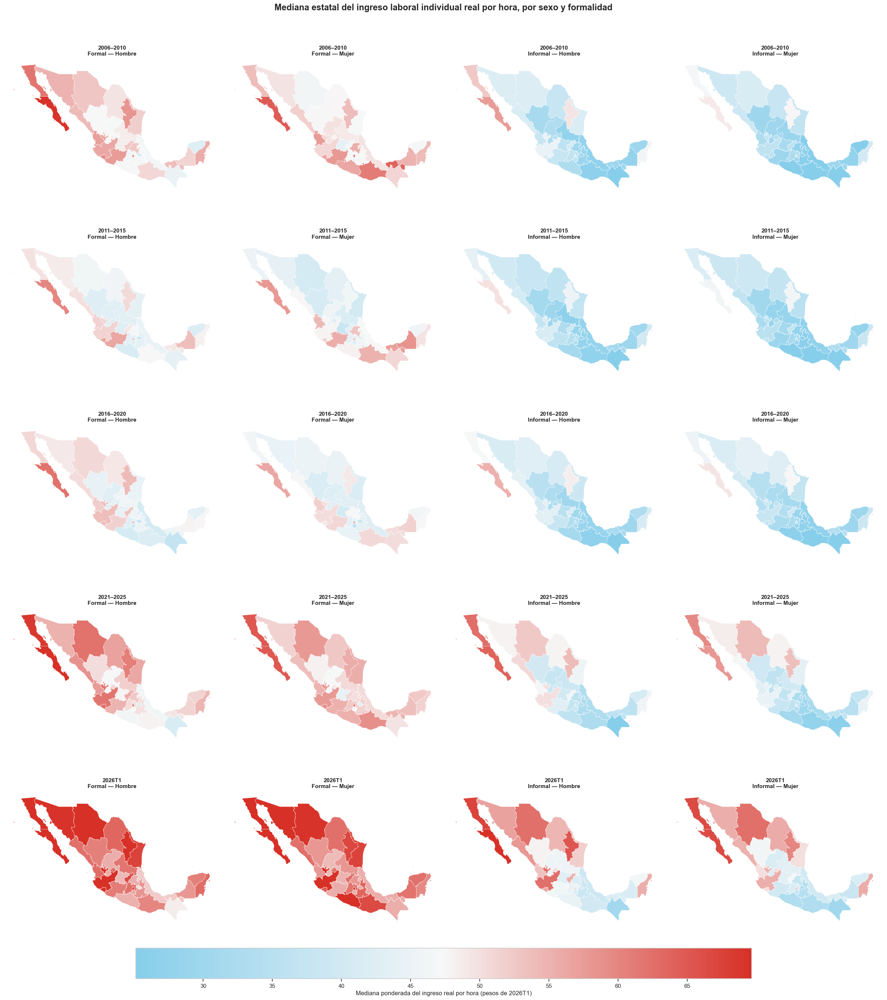

,periodo_analisis,cve_ent,sexo,tipo_empleo,n_muestral,peso_total,media,desviacion_estandar,p25,mediana,p75
0,2006–2010,01,Hombre,Formal,"23,870.00","2,160,003.00",69.50,76.31,34.76,47.92,75.71
4,2006–2010,02,Hombre,Formal,"36,109.00","8,602,798.00",85.24,77.83,44.65,62.00,99.04
8,2006–2010,03,Hombre,Formal,"28,414.00","1,890,632.00",99.72,131.68,44.88,69.22,111.90
12,2006–2010,04,Hombre,Formal,"25,120.00","1,639,964.00",79.71,85.12,32.90,51.33,95.78
16,2006–2010,05,Hombre,Formal,"38,052.00","7,753,258.00",76.73,99.22,35.86,49.61,80.06
...,...,...,...,...,...,...,...,...,...,...,...
623,2026T1,28,Mujer,Informal,"1,067.00","270,574.00",67.68,67.94,33.33,50.00,75.00
627,2026T1,29,Mujer,Informal,"1,240.00","147,695.00",42.86,36.63,23.26,33.33,50.00
631,2026T1,30,Mujer,Informal,"1,641.00","758,127.00",58.01,71.36,26.04,39.79,59.69
635,2026T1,31,Mujer,Informal,"1,242.00","282,210.00",61.81,80.54,25.84,41.67,66.67


In [32]:
df_mapa_hora_sexo_empleo = resumen_ponderado(
    "ingreso_hora_real",
    ["periodo_analisis", "cve_ent", "sexo", "tipo_empleo"],
    """
        es_ocupado
        AND factor_valido
        AND fac_tri > 0
        AND ingreso_hora_real > 0
        AND sexo IN ('Hombre', 'Mujer')
        AND tipo_empleo IN ('Formal', 'Informal')
        AND periodo <> '2020T2'
    """
)

df_mapa_hora_sexo_empleo["periodo_analisis"] = pd.Categorical(
    df_mapa_hora_sexo_empleo["periodo_analisis"],
    categories=ORDEN_PERIODOS,
    ordered=True
)

vmin, vmax = limites_color(df_mapa_hora_sexo_empleo, "mediana")

combinaciones = [
    ("Formal", "Hombre"),
    ("Formal", "Mujer"),
    ("Informal", "Hombre"),
    ("Informal", "Mujer"),
]

# Cada fila es un período; las cuatro columnas permiten comparar
# simultáneamente sexo y formalidad.
fig, axes = plt.subplots(
    nrows=len(ORDEN_PERIODOS),
    ncols=len(combinaciones),
    figsize=(24, 27),
    layout="constrained"
)

for fila, periodo in enumerate(ORDEN_PERIODOS):
    for columna, (empleo_actual, sexo_actual) in enumerate(combinaciones):
        ax = axes[fila, columna]

        datos = df_mapa_hora_sexo_empleo.loc[
            (df_mapa_hora_sexo_empleo["periodo_analisis"] == periodo)
            & (df_mapa_hora_sexo_empleo["tipo_empleo"] == empleo_actual)
            & (df_mapa_hora_sexo_empleo["sexo"] == sexo_actual)
        ].copy()

        dibujar_mapa(
            ax=ax,
            geo=geo_entidades,
            datos=datos,
            valor="mediana",
            vmin=vmin,
            vmax=vmax,
            titulo=f"{periodo}\n{empleo_actual} — {sexo_actual}"
        )

sm = plt.cm.ScalarMappable(
    cmap=CMAP_INGRESO,
    norm=Normalize(vmin=vmin, vmax=vmax)
)
sm.set_array([])

fig.colorbar(
    sm,
    ax=axes.ravel().tolist(),
    orientation="horizontal",
    shrink=0.70,
    pad=0.02,
    label="Mediana ponderada del ingreso real por hora (pesos de 2026T1)"
)

fig.suptitle(
    "Mediana estatal del ingreso laboral individual real por hora, por sexo y formalidad",
    fontsize=17,
    fontweight="bold"
)

plt.show()

display(
    df_mapa_hora_sexo_empleo.sort_values(
        ["periodo_analisis", "tipo_empleo", "sexo", "cve_ent"]
    ).round(2)
)

# 6. ¿Dónde se trabaja y cuándo aparece un segundo empleo?

El gráfico de posiciones ordena los cinco sectores líderes por participación en el empleo clasificado (SCIAN 1–20). Se promedian los porcentajes trimestrales: participación aquí significa empleo, **no** valor de la producción.

**Lectura.** El comercio al por menor ocupa el primer puesto tanto en 2006 (17.09%) como en 2026T1 (17.08%); las manufacturas, el segundo (16.77% y 16.22%). El sector agropecuario baja de 14.89% a 10.47% aunque conserva el tercer lugar en ambos extremos. Una posición estable puede ocultar cambios importantes de peso.

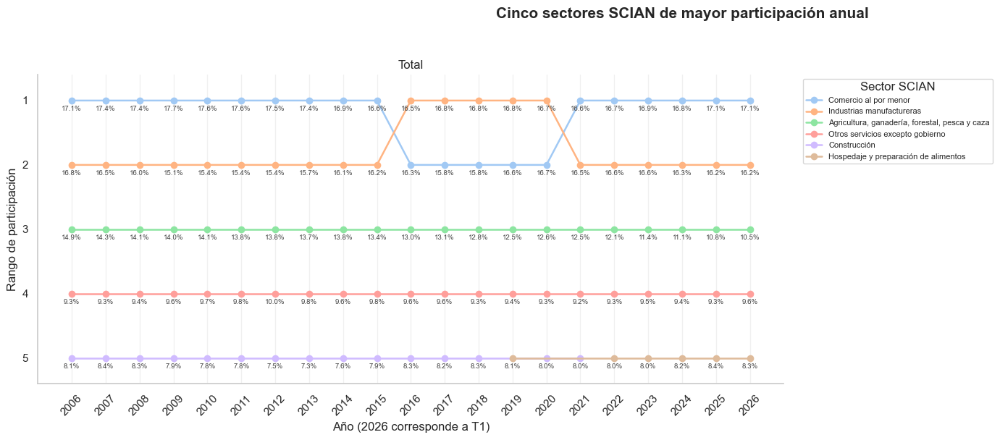

,anio,rango,scian,sector,participacion_pct
6,2006,1,7,Comercio al por menor,17.09
4,2006,2,5,Industrias manufactureras,16.77
0,2006,3,1,"Agricultura, ganadería, forestal, pesca y caza",14.89
18,2006,4,19,Otros servicios excepto gobierno,9.27
3,2006,5,4,Construcción,8.12
...,...,...,...,...,...
406,2026,1,7,Comercio al por menor,17.08
404,2026,2,5,Industrias manufactureras,16.22
400,2026,3,1,"Agricultura, ganadería, forestal, pesca y caza",10.47
418,2026,4,19,Otros servicios excepto gobierno,9.56


In [33]:
SCIAN_SECTORES = {
    1: "Agricultura, ganadería, forestal, pesca y caza", 2: "Minería", 3: "Electricidad, agua y gas", 4: "Construcción",
    5: "Industrias manufactureras", 6: "Comercio al por mayor", 7: "Comercio al por menor", 8: "Transportes, correos y almacenamiento",
    9: "Información en medios masivos", 10: "Servicios financieros y de seguros", 11: "Servicios inmobiliarios y alquiler",
    12: "Servicios profesionales, científicos y técnicos", 13: "Corporativos", 14: "Apoyo a negocios y manejo de desechos",
    15: "Servicios educativos", 16: "Salud y asistencia social", 17: "Esparcimiento, cultura y deporte",
    18: "Hospedaje y preparación de alimentos", 19: "Otros servicios excepto gobierno", 20: "Gobierno y organismos internacionales"
}

def principales_scian(dimensiones):
    dimensiones = [_identificador(d) for d in dimensiones]; dims = ", ".join(dimensiones); prefijo = f"{dims}, " if dims else ""
    particion = f"periodo, {dims}" if dims else "periodo"; grupo = f"anio, periodo, {dims}, scian" if dims else "anio, periodo, scian"
    anual_grupo = f"anio, {dims}, scian" if dims else "anio, scian"
    return con.sql(f"""
        WITH trimestral AS (
            SELECT anio, periodo, {prefijo}scian, SUM(fac_tri) AS peso FROM {TABLA_ANALISIS}
            WHERE es_ocupado AND factor_valido AND fac_tri > 0 AND scian BETWEEN 1 AND 20 AND periodo <> '2020T2'
            GROUP BY {grupo}
        ), porcentajes AS (
            SELECT *, 100.0 * peso / SUM(peso) OVER (PARTITION BY {particion}) AS participacion_pct FROM trimestral
        ) SELECT anio, {prefijo}scian, AVG(participacion_pct) AS participacion_pct FROM porcentajes GROUP BY {anual_grupo}
    """).df()

def preparar_bump_scian(datos, dimensiones):
    grupos = ["anio"] + dimensiones
    datos = datos.copy().sort_values(grupos + ["participacion_pct"], ascending=[True] * len(grupos) + [False])
    datos["rango"] = datos.groupby(grupos).cumcount() + 1; datos["sector"] = datos["scian"].map(SCIAN_SECTORES)
    return datos

def graficar_bump_scian(datos, facetas, titulo):
    combinaciones = [()] if not facetas else list(datos[facetas].drop_duplicates().itertuples(index=False, name=None))
    fig, axes = plt.subplots(len(combinaciones), 1, figsize=(19, max(6, 6 * len(combinaciones))), squeeze=False)
    for ax, valores in zip(axes.flat, combinaciones):
        mascara = pd.Series(True, index=datos.index)
        for columna, valor in zip(facetas, valores): mascara &= datos[columna].eq(valor)
        panel = datos[mascara].copy(); top_ids = panel.loc[panel["rango"] <= 5, "scian"].unique()
        colores = dict(zip(top_ids, sns.color_palette("pastel", n_colors=len(top_ids)).as_hex()))
        for scian in top_ids:
            serie = panel[(panel["scian"] == scian) & (panel["rango"] <= 5)].sort_values("anio")
            if serie.empty: continue
            ax.plot(serie["anio"], serie["rango"], marker="o", linewidth=1.8, color=colores[scian], label=SCIAN_SECTORES[scian])
            for fila in serie.itertuples(index=False):
                ax.annotate(f"{fila.participacion_pct:.1f}%", (fila.anio, fila.rango), xytext=(0, -10), textcoords="offset points", ha="center", fontsize=7, color="#444444")
        subtitulo = " — ".join(map(str, valores)) if valores else "Total"
        ax.set(title=subtitulo, xlabel="Año (2026 corresponde a T1)", ylabel="Rango de participación", yticks=range(1, 6), ylim=(5.4, 0.6))
        estilo_linea(ax, sorted(panel["anio"].unique())); ax.legend(title="Sector SCIAN", bbox_to_anchor=(1.02, 1), loc="upper left", fontsize=8)
    fig.suptitle(titulo, y=1.01, fontsize=15, fontweight="bold"); plt.tight_layout(rect=(0, 0, 0.74, 0.98)); plt.show()

df_scian_general = preparar_bump_scian(principales_scian([]), [])
graficar_bump_scian(df_scian_general, [], "Cinco sectores SCIAN de mayor participación anual")
display(df_scian_general.query("rango <= 5")[["anio", "rango", "scian", "sector", "participacion_pct"]].round(2))


## El ranking nacional esconde especializaciones

Se vuelve a ordenar dentro de cada sexo y después dentro de cada combinación de sexo y formalidad; cada porcentaje usa el total clasificado del grupo correspondiente.

**Lectura.** En 2006 la agricultura encabezaba el empleo masculino (20.76%), pero entre los hombres formales lideraban las manufacturas (24.59%). En 2026T1 el comercio al por menor reúne 24.16% del empleo femenino clasificado y 30.49% del femenino informal. No son porcentajes del empleo total nacional.

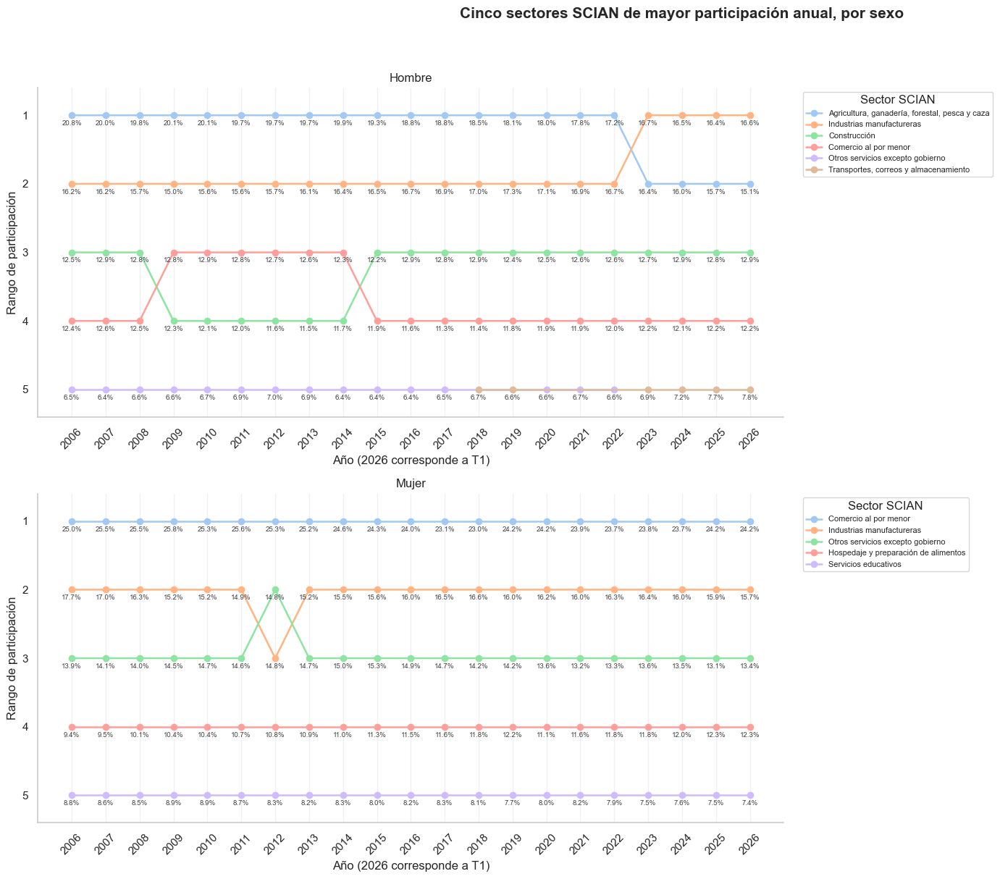

,anio,sexo,scian,participacion_pct,rango,sector
578,2006,Hombre,1,20.76,1,"Agricultura, ganadería, forestal, pesca y caza"
469,2006,Hombre,5,16.23,2,Industrias manufactureras
154,2006,Hombre,4,12.51,3,Construcción
155,2006,Hombre,7,12.44,4,Comercio al por menor
374,2006,Hombre,19,6.52,5,Otros servicios excepto gobierno
...,...,...,...,...,...,...
92,2026,Mujer,7,24.16,1,Comercio al por menor
728,2026,Mujer,5,15.73,2,Industrias manufactureras
837,2026,Mujer,19,13.37,3,Otros servicios excepto gobierno
417,2026,Mujer,18,12.35,4,Hospedaje y preparación de alimentos


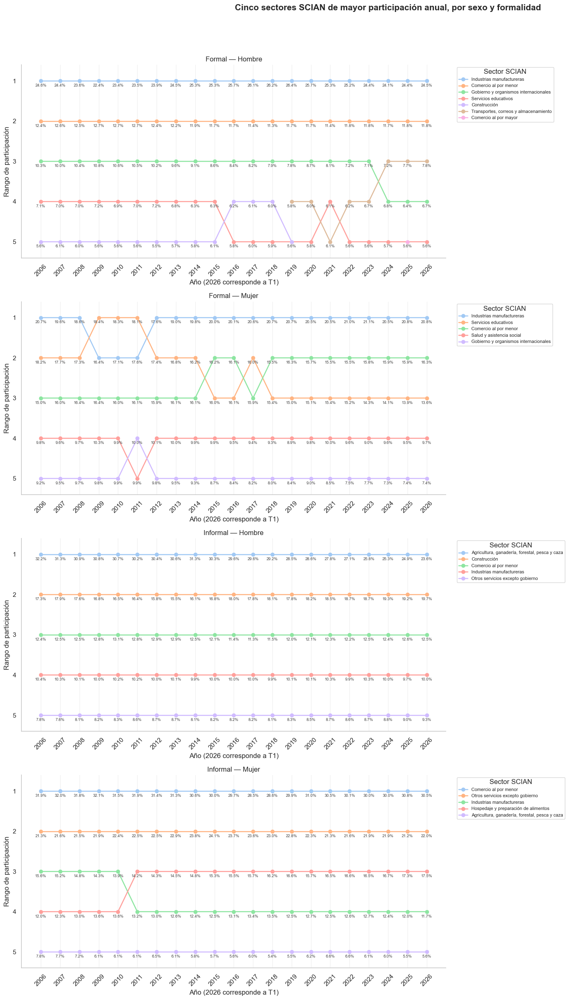

,anio,sexo,tipo_empleo,scian,participacion_pct,rango,sector
834,2006,Hombre,Formal,5,24.59,1,Industrias manufactureras
230,2006,Hombre,Formal,7,12.45,2,Comercio al por menor
644,2006,Hombre,Formal,20,10.25,3,Gobierno y organismos internacionales
430,2006,Hombre,Formal,15,7.08,4,Servicios educativos
229,2006,Hombre,Formal,4,5.59,5,Construcción
...,...,...,...,...,...,...,...
409,2026,Mujer,Informal,7,30.49,1,Comercio al por menor
1430,2026,Mujer,Informal,19,21.98,2,Otros servicios excepto gobierno
619,2026,Mujer,Informal,18,17.54,3,Hospedaje y preparación de alimentos
1032,2026,Mujer,Informal,5,11.67,4,Industrias manufactureras


In [34]:
df_scian_sexo = preparar_bump_scian(principales_scian(["sexo"]).query("sexo in ['Hombre', 'Mujer']"), ["sexo"])
graficar_bump_scian(df_scian_sexo, ["sexo"], "Cinco sectores SCIAN de mayor participación anual, por sexo")
display(df_scian_sexo.query("rango <= 5").round(2))

df_scian_sexo_empleo = preparar_bump_scian(
    principales_scian(["sexo", "tipo_empleo"]).query("sexo in ['Hombre', 'Mujer'] and tipo_empleo in ['Formal', 'Informal']"),
    ["tipo_empleo", "sexo"]
)
graficar_bump_scian(df_scian_sexo_empleo, ["tipo_empleo", "sexo"], "Cinco sectores SCIAN de mayor participación anual, por sexo y formalidad")
display(df_scian_sexo_empleo.query("rango <= 5").round(2))


## ¿Más personas con dos trabajos significa que el segundo empleo es más frecuente?

Se expande el número con segundo empleo y, por separado, se calcula qué proporción representa entre los ocupados de cada sexo con respuesta clasificable a P7. Los niveles anuales son promedios trimestrales.

**Lectura.** El conteo pasa de unos 2.89 millones en 2006 a 3.20 millones en 2026T1. La participación masculina, sin embargo, baja de 7.81% a 5.74%; la femenina cambia de 4.86% a 4.79%. Un número absoluto creciente puede coexistir con una proporción decreciente.

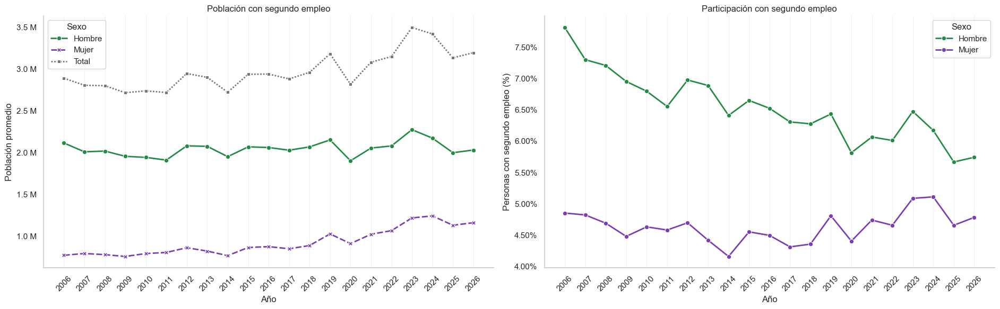

,anio,sexo,poblacion_promedio,trimestres_disponibles
0,2006,Hombre,"2,117,308.00",4
1,2006,Mujer,"774,543.75",4
2,2007,Hombre,"2,012,088.75",4
3,2007,Mujer,"795,985.75",4
4,2008,Hombre,"2,020,727.50",4
...,...,...,...,...
58,2022,Total,"3,151,299.50",4
59,2023,Total,"3,498,098.50",4
60,2024,Total,"3,421,452.50",4
61,2025,Total,"3,135,165.50",4


,anio,sexo,segundo_pct
0,2006,Hombre,7.81
1,2006,Mujer,4.86
2,2007,Hombre,7.30
3,2007,Mujer,4.82
4,2008,Hombre,7.21
5,2008,Mujer,4.69
6,2009,Hombre,6.95
7,2009,Mujer,4.48
8,2010,Hombre,6.80
9,2010,Mujer,4.63


In [35]:
df_segundo_conteo = promedio_trimestral_expandido(
    ["sexo"], "es_ocupado AND tiene_segundo_empleo AND sexo IN ('Hombre', 'Mujer')"
)
df_segundo_total = (df_segundo_conteo.groupby("anio", as_index=False)
                    .agg(poblacion_promedio=("poblacion_promedio", "sum"), trimestres_disponibles=("trimestres_disponibles", "max"))
                    .assign(sexo="Total"))
df_segundo_serie = pd.concat([df_segundo_conteo, df_segundo_total], ignore_index=True)
df_segundo_pct = con.sql(f"""
    WITH trimestral AS (
        SELECT anio, periodo, sexo,
               100.0 * SUM(CASE WHEN tiene_segundo_empleo THEN fac_tri ELSE 0 END) / SUM(fac_tri) AS segundo_pct
        FROM {TABLA_ANALISIS}
        WHERE es_ocupado AND factor_valido AND fac_tri > 0 AND p7 BETWEEN 1 AND 7
          AND sexo IN ('Hombre', 'Mujer') AND periodo <> '2020T2'
        GROUP BY ALL
    )
    SELECT anio, sexo, AVG(segundo_pct) AS segundo_pct FROM trimestral GROUP BY ALL ORDER BY anio, sexo
""").df()

fig, axes = plt.subplots(1, 2, figsize=(19, 6))
sns.lineplot(data=df_segundo_serie, x="anio", y="poblacion_promedio", hue="sexo",
             hue_order=["Hombre", "Mujer", "Total"], palette={**COLOR_SEXO, "Total": "#777777"},
             style="sexo", markers=True, linewidth=2, ax=axes[0])
axes[0].set(title="Población con segundo empleo", xlabel="Año", ylabel="Población promedio")
axes[0].yaxis.set_major_formatter(FuncFormatter(lambda x, _: f"{x / 1e6:.1f} M"))
estilo_linea(axes[0], sorted(df_segundo_serie["anio"].unique())); axes[0].legend(title="Sexo")
sns.lineplot(data=df_segundo_pct, x="anio", y="segundo_pct", hue="sexo", hue_order=["Hombre", "Mujer"],
             palette=COLOR_SEXO, marker="o", linewidth=2, ax=axes[1])
axes[1].set(title="Participación con segundo empleo", xlabel="Año", ylabel="Personas con segundo empleo (%)")
axes[1].yaxis.set_major_formatter(PercentFormatter()); estilo_linea(axes[1], sorted(df_segundo_pct["anio"].unique()))
axes[1].legend(title="Sexo"); plt.tight_layout(); plt.show()
display(df_segundo_serie, df_segundo_pct.round(2))


## Qué aporta ese segundo trabajo cuando se observa su monto

Se estiman el ingreso mensual positivo del segundo empleo y sus horas reportadas usando sus respectivos registros válidos. La serie con montos comienza en 2007; no se imputa cero cuando falta el módulo.

**Lectura.** En 2026T1 las medianas son $3,000 y 10 horas para hombres; $2,000 y 8 horas para mujeres. Los universos de ingreso y horas no son idénticos. Tampoco se debe sumar estas medianas a las del trabajo principal para estimar una mediana de ingreso total.

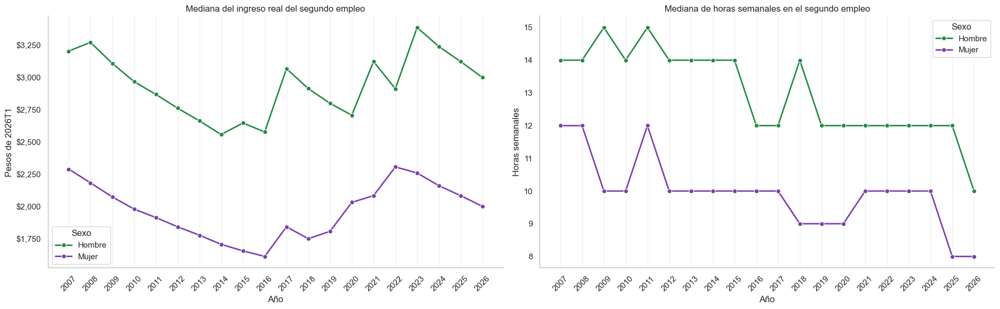

,anio,sexo,n_muestral,peso_total,media,desviacion_estandar,p25,mediana,p75
0,2007,Hombre,"5,705.00","1,408,696.00","5,916.92","9,791.75","1,575.04","3,205.03","6,867.92"
1,2007,Mujer,"2,845.00","618,765.00","4,747.56","39,402.34",915.72,"2,289.31","4,578.61"
2,2008,Hombre,"5,760.00","1,476,798.00","5,773.84","9,269.40","1,636.52","3,273.03","6,546.07"
3,2008,Mujer,"2,988.00","666,565.00","4,161.25","5,785.19","1,091.01","2,182.02","5,018.65"
4,2009,Hombre,"4,960.00","1,300,803.00","5,585.56","15,856.56","1,658.50","3,109.68","6,219.36"
5,2009,Mujer,"2,513.00","551,566.00","3,896.26","5,734.85","1,036.56","2,073.12","4,146.24"
6,2010,Hombre,"5,139.00","1,333,108.00","4,953.19","7,585.35","1,385.34","2,968.58","5,937.16"
7,2010,Mujer,"2,626.00","585,279.00","3,606.16","4,929.59",791.62,"1,979.05","3,958.10"
8,2011,Hombre,"4,492.00","1,160,996.00","4,773.35","6,943.98","1,530.25","2,869.22","5,738.43"
9,2011,Mujer,"2,376.00","554,624.00","3,780.38","5,651.21",956.41,"1,912.81","3,825.62"


,anio,sexo,n_muestral,peso_total,media,desviacion_estandar,p25,mediana,p75
0,2007,Hombre,"6,348.00","1,615,254.00",16.70,11.76,8.00,14.00,24.00
1,2007,Mujer,"3,233.00","733,215.00",14.89,11.26,6.00,12.00,21.00
2,2008,Hombre,"6,550.00","1,736,418.00",16.74,11.68,8.00,14.00,24.00
3,2008,Mujer,"3,534.00","786,950.00",14.21,10.74,6.00,12.00,20.00
4,2009,Hombre,"5,469.00","1,423,609.00",17.17,11.65,8.00,15.00,24.00
5,2009,Mujer,"2,901.00","650,206.00",13.83,10.50,6.00,10.00,20.00
6,2010,Hombre,"5,411.00","1,408,245.00",16.54,11.45,8.00,14.00,24.00
7,2010,Mujer,"3,018.00","706,754.00",13.72,10.91,6.00,10.00,20.00
8,2011,Hombre,"4,940.00","1,327,130.00",17.12,11.87,8.00,15.00,24.00
9,2011,Mujer,"2,732.00","659,963.00",14.52,11.32,6.00,12.00,20.00


In [36]:
filtro_segundo = ("es_ocupado AND tiene_segundo_empleo AND factor_valido "
                  "AND sexo IN ('Hombre', 'Mujer') AND periodo <> '2020T2'")
df_ingreso_segundo = resumen_ponderado(
    "ingreso_segundo_real", ["anio", "sexo"], filtro_segundo + " AND ingreso_segundo_real > 0"
)
df_horas_segundo = resumen_ponderado(
    "p7f_horas", ["anio", "sexo"], filtro_segundo + " AND p7f_horas BETWEEN 1 AND 97"
)

fig, axes = plt.subplots(1, 2, figsize=(19, 6))
if not df_ingreso_segundo.empty:
    sns.lineplot(data=df_ingreso_segundo, x="anio", y="mediana", hue="sexo", hue_order=["Hombre", "Mujer"],
                 palette=COLOR_SEXO, marker="o", linewidth=2, ax=axes[0])
axes[0].set(title="Mediana del ingreso real del segundo empleo", xlabel="Año", ylabel="Pesos de 2026T1")
axes[0].yaxis.set_major_formatter(FuncFormatter(formato_pesos))
if not df_horas_segundo.empty:
    sns.lineplot(data=df_horas_segundo, x="anio", y="mediana", hue="sexo", hue_order=["Hombre", "Mujer"],
                 palette=COLOR_SEXO, marker="o", linewidth=2, ax=axes[1])
axes[1].set(title="Mediana de horas semanales en el segundo empleo", xlabel="Año", ylabel="Horas semanales")
for ax, datos in zip(axes, [df_ingreso_segundo, df_horas_segundo]):
    if not datos.empty:
        estilo_linea(ax, sorted(datos["anio"].unique())); ax.legend(title="Sexo")
plt.tight_layout(); plt.show()
display(df_ingreso_segundo.round(2), df_horas_segundo.round(2))


# 7. Las personas detrás de los puestos: escolaridad y hogares

La pregunta inicial no es cuánto gana un universitario, sino cómo cambia la composición de la población de 15 años y más. Se promedian los conteos expandidos por trimestre y se separan por sexo. NIV_INS **no distingue** media superior, licenciatura y posgrado por separado.

**Lectura.** La categoría conjunta «Media superior y superior» pasa de 17.49 millones en 2006–2010 a 41.51 millones en 2026T1 (20.19 millones de hombres y 21.32 de mujeres en el último corte). Los 233,806 registros expandidos del código 5 en 2026T1 son **nivel no especificado**, no población con posgrado. Para afinar el análisis se usan a continuación los años aprobados.

**Nota editorial.** Se corrigieron las etiquetas de la V3 según la [estructura de la base de datos ENOE, campo NIV_INS](https://www.inegi.org.mx/contenidos/programas/enoe/15ymas/doc/enoe_n_321_fd_c_bas_amp.pdf). Las tres figuras se redibujaron desde los agregados completos guardados en la V3; la corrección no recalcula los conteos ni altera las medianas por años aprobados.

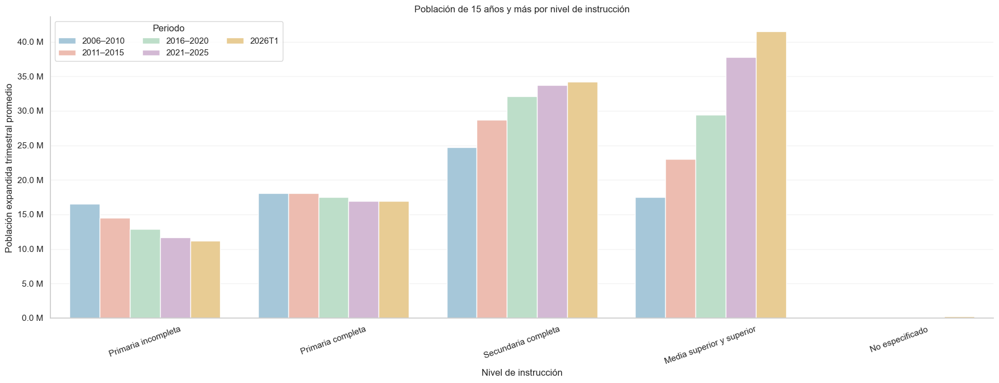

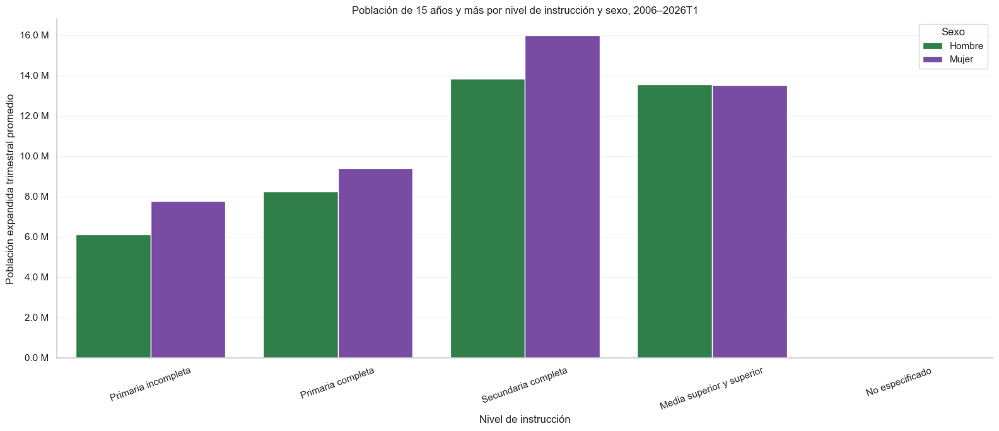

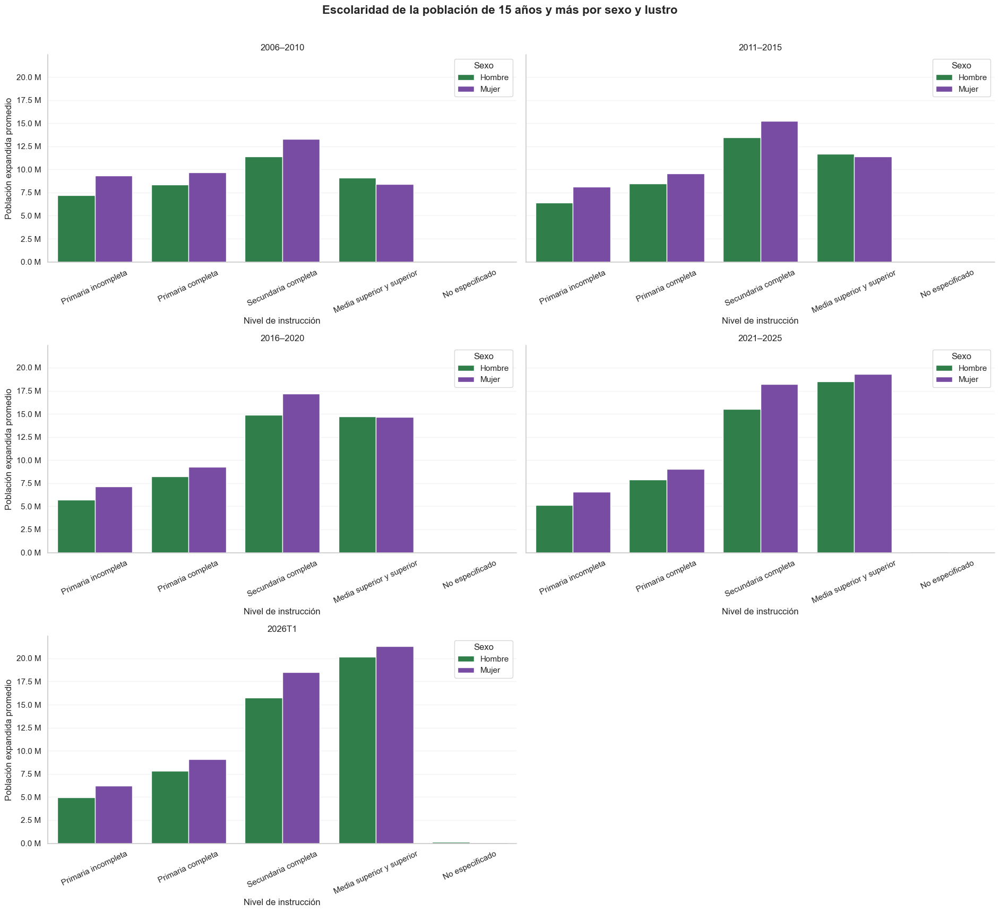

,periodo_analisis,nivel_instruccion,poblacion_promedio,trimestres_disponibles
0,2006–2010,Primaria incompleta,"16,525,126.10",20
1,2006–2010,Primaria completa,"18,053,800.30",20
17,2006–2010,Secundaria completa,"24,693,647.85",20
2,2006–2010,Media superior y superior,"17,492,263.75",20
18,2006–2010,No especificado,"45,987.60",20
21,2011–2015,Primaria incompleta,"14,537,111.50",20
20,2011–2015,Primaria completa,"18,050,305.55",20
13,2011–2015,Secundaria completa,"28,690,809.10",20
19,2011–2015,Media superior y superior,"23,060,984.10",20
14,2011–2015,No especificado,"48,055.15",20


,nivel_instruccion,sexo,poblacion_promedio,trimestres_disponibles
5,Primaria incompleta,Hombre,"6,109,085.58",80
3,Primaria incompleta,Mujer,"7,781,424.56",80
0,Primaria completa,Hombre,"8,248,614.48",80
9,Primaria completa,Mujer,"9,391,060.62",80
8,Secundaria completa,Hombre,"13,833,813.62",80
7,Secundaria completa,Mujer,"15,997,470.48",80
4,Media superior y superior,Hombre,"13,565,943.88",80
1,Media superior y superior,Mujer,"13,524,748.31",80
2,No especificado,Hombre,"38,405.55",80
6,No especificado,Mujer,"36,919.40",80


,periodo_analisis,nivel_instruccion,sexo,poblacion_promedio,trimestres_disponibles
38,2006–2010,Primaria incompleta,Hombre,"7,197,802.85",20
9,2006–2010,Primaria incompleta,Mujer,"9,327,323.25",20
11,2006–2010,Primaria completa,Hombre,"8,368,805.45",20
27,2006–2010,Primaria completa,Mujer,"9,684,994.85",20
1,2006–2010,Secundaria completa,Hombre,"11,406,712.85",20
33,2006–2010,Secundaria completa,Mujer,"13,286,935.00",20
46,2006–2010,Media superior y superior,Hombre,"9,086,623.00",20
15,2006–2010,Media superior y superior,Mujer,"8,405,640.75",20
0,2006–2010,No especificado,Hombre,"22,886.45",20
32,2006–2010,No especificado,Mujer,"23,101.15",20


In [37]:
ORDEN_NIVEL_INSTRUCCION = [
    "Primaria incompleta", "Primaria completa", "Secundaria completa", "Media superior y superior", "No especificado"
]
filtro_educacion_poblacion = (
    "eda >= 15 AND factor_valido AND fac_tri > 0 "
    "AND nivel_instruccion IN ('Primaria incompleta', 'Primaria completa', 'Secundaria completa', 'Media superior y superior', 'No especificado') "
    "AND periodo <> '2020T2'"
)

df_educacion_lustros = con.sql(f"""
    WITH trimestral AS (
        SELECT periodo_analisis, periodo, nivel_instruccion, SUM(fac_tri) AS poblacion
        FROM {TABLA_ANALISIS}
        WHERE {filtro_educacion_poblacion}
        GROUP BY periodo_analisis, periodo, nivel_instruccion
    )
    SELECT periodo_analisis, nivel_instruccion, AVG(poblacion) AS poblacion_promedio,
           COUNT(DISTINCT periodo) AS trimestres_disponibles
    FROM trimestral
    GROUP BY periodo_analisis, nivel_instruccion
""").df()
df_educacion_lustros["periodo_analisis"] = pd.Categorical(
    df_educacion_lustros["periodo_analisis"], ORDEN_PERIODOS, ordered=True
)
df_educacion_lustros["nivel_instruccion"] = pd.Categorical(
    df_educacion_lustros["nivel_instruccion"], ORDEN_NIVEL_INSTRUCCION, ordered=True
)

fig, ax = plt.subplots(figsize=(18, 7))
sns.barplot(data=df_educacion_lustros, x="nivel_instruccion", y="poblacion_promedio",
            hue="periodo_analisis", hue_order=ORDEN_PERIODOS, palette=PALETA_PASTEL[:5],
            errorbar=None, ax=ax)
ax.set(title="Población de 15 años y más por nivel de instrucción", xlabel="Nivel de instrucción",
       ylabel="Población expandida trimestral promedio")
ax.yaxis.set_major_formatter(FuncFormatter(formato_millones)); ax.tick_params(axis="x", rotation=20)
ax.grid(axis="y", alpha=0.22); ax.grid(axis="x", visible=False); ax.legend(title="Periodo", ncol=3)
sns.despine(ax=ax); plt.tight_layout(); plt.show()

df_educacion_sexo_total = con.sql(f"""
    WITH trimestral AS (
        SELECT periodo, nivel_instruccion, sexo, SUM(fac_tri) AS poblacion
        FROM {TABLA_ANALISIS}
        WHERE {filtro_educacion_poblacion} AND sexo IN ('Hombre', 'Mujer')
        GROUP BY periodo, nivel_instruccion, sexo
    )
    SELECT nivel_instruccion, sexo, AVG(poblacion) AS poblacion_promedio,
           COUNT(DISTINCT periodo) AS trimestres_disponibles
    FROM trimestral
    GROUP BY nivel_instruccion, sexo
""").df()
df_educacion_sexo_total["nivel_instruccion"] = pd.Categorical(
    df_educacion_sexo_total["nivel_instruccion"], ORDEN_NIVEL_INSTRUCCION, ordered=True
)
fig, ax = plt.subplots(figsize=(16, 7))
sns.barplot(data=df_educacion_sexo_total, x="nivel_instruccion", y="poblacion_promedio",
            hue="sexo", hue_order=["Hombre", "Mujer"], palette=COLOR_SEXO, errorbar=None, ax=ax)
ax.set(title="Población de 15 años y más por nivel de instrucción y sexo, 2006–2026T1",
       xlabel="Nivel de instrucción", ylabel="Población expandida trimestral promedio")
ax.yaxis.set_major_formatter(FuncFormatter(formato_millones)); ax.tick_params(axis="x", rotation=20)
ax.grid(axis="y", alpha=0.22); ax.grid(axis="x", visible=False); ax.legend(title="Sexo")
sns.despine(ax=ax); plt.tight_layout(); plt.show()

df_educacion_sexo_lustros = con.sql(f"""
    WITH trimestral AS (
        SELECT periodo_analisis, periodo, nivel_instruccion, sexo, SUM(fac_tri) AS poblacion
        FROM {TABLA_ANALISIS}
        WHERE {filtro_educacion_poblacion} AND sexo IN ('Hombre', 'Mujer')
        GROUP BY periodo_analisis, periodo, nivel_instruccion, sexo
    )
    SELECT periodo_analisis, nivel_instruccion, sexo, AVG(poblacion) AS poblacion_promedio,
           COUNT(DISTINCT periodo) AS trimestres_disponibles
    FROM trimestral
    GROUP BY periodo_analisis, nivel_instruccion, sexo
""").df()
df_educacion_sexo_lustros["periodo_analisis"] = pd.Categorical(
    df_educacion_sexo_lustros["periodo_analisis"], ORDEN_PERIODOS, ordered=True
)
df_educacion_sexo_lustros["nivel_instruccion"] = pd.Categorical(
    df_educacion_sexo_lustros["nivel_instruccion"], ORDEN_NIVEL_INSTRUCCION, ordered=True
)
fig, axes = plt.subplots(3, 2, figsize=(19, 17), sharey=True)
for ax, periodo in zip(axes.flat, ORDEN_PERIODOS):
    datos = df_educacion_sexo_lustros.query("periodo_analisis == @periodo")
    sns.barplot(data=datos, x="nivel_instruccion", y="poblacion_promedio", hue="sexo",
                hue_order=["Hombre", "Mujer"], palette=COLOR_SEXO, errorbar=None, ax=ax)
    ax.set(title=periodo, xlabel="Nivel de instrucción", ylabel="Población expandida promedio")
    ax.yaxis.set_major_formatter(FuncFormatter(formato_millones)); ax.tick_params(axis="x", rotation=25)
    ax.grid(axis="y", alpha=0.22); ax.grid(axis="x", visible=False); ax.legend(title="Sexo")
    sns.despine(ax=ax)
axes.flat[-1].axis("off")
fig.suptitle("Escolaridad de la población de 15 años y más por sexo y lustro", y=1.01,
             fontsize=16, fontweight="bold")
plt.tight_layout(); plt.show()

display(
    df_educacion_lustros.sort_values(["periodo_analisis", "nivel_instruccion"]).round(2),
    df_educacion_sexo_total.sort_values(["nivel_instruccion", "sexo"]).round(2),
    df_educacion_sexo_lustros.sort_values(["periodo_analisis", "nivel_instruccion", "sexo"]).round(2),
)


## Años aprobados: una comparación más fina que el grado agrupado

Se calcula la mediana de los ingresos positivos según años aprobados, primero en la serie combinada y luego por sexo y periodo. Se excluyen los códigos fuera de 0–30; las observaciones publicadas llegan a 24 años.

**Lectura.** La mediana combinada es $6,328 con seis años, $8,301 con doce y $12,745 con dieciséis. Hay asociación, no una tasa de retorno causal: cambian también edades y ocupaciones. En 2026T1 el punto femenino de 24 años proviene de **una observación**; no conviene interpretar ese extremo como una tendencia.

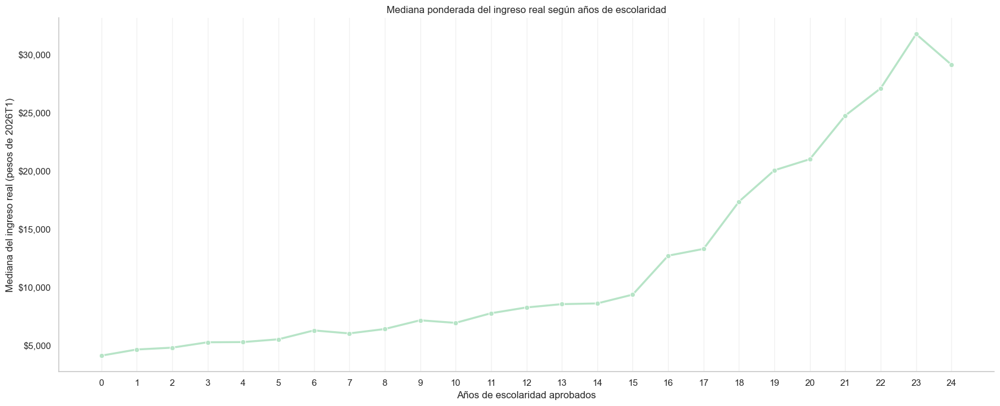

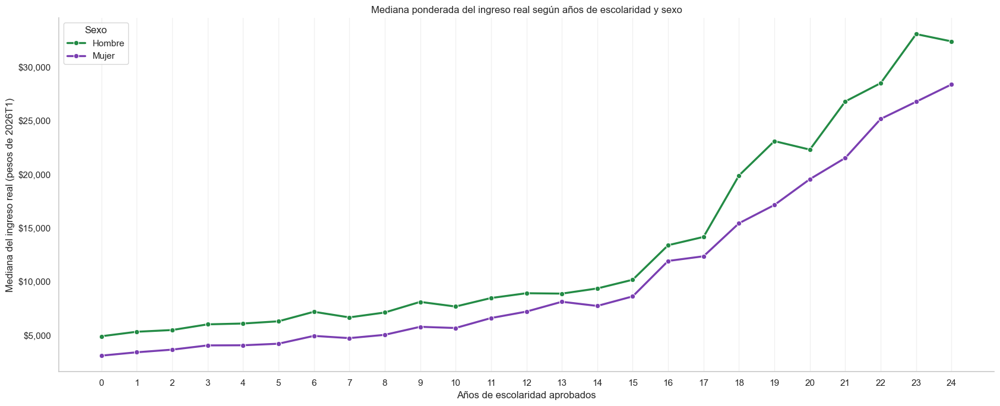

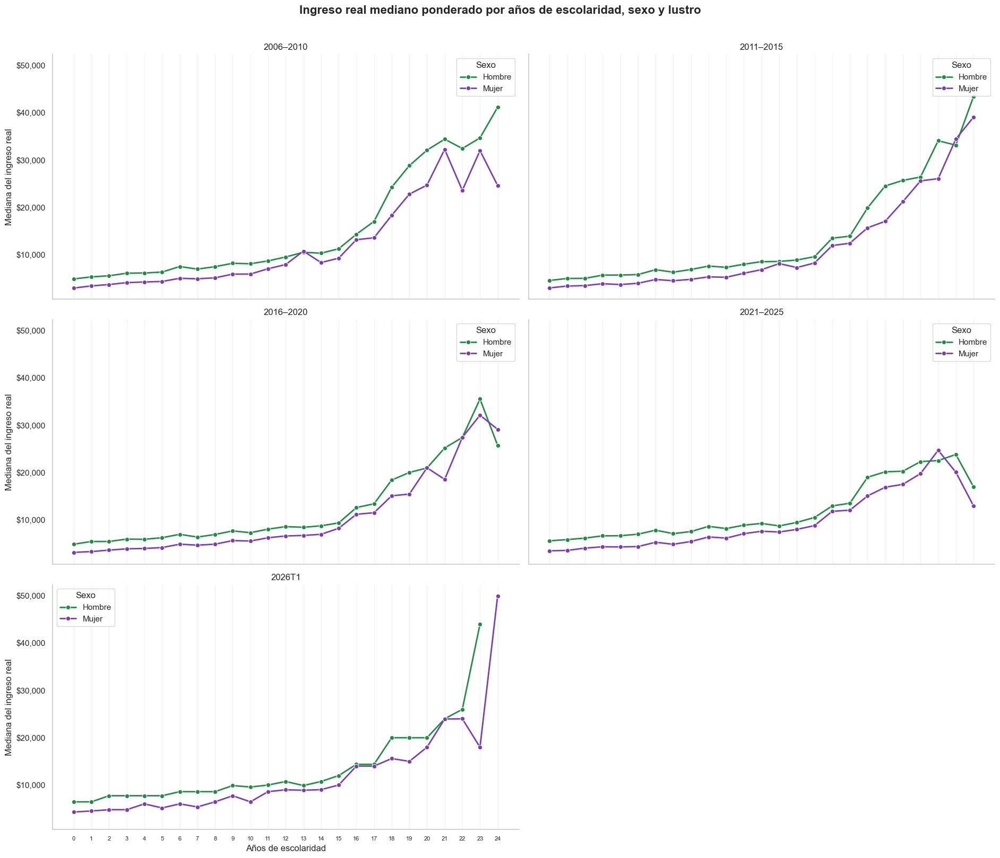

,anios_esc,n_muestral,peso_total,media,desviacion_estandar,p25,mediana,p75
0,0,"355,991.00","125,798,597.00","4,999.04","5,099.43","1,939.66","4,163.25","6,831.08"
1,1,"91,635.00","30,208,427.00","5,569.83","7,410.28","2,359.94","4,691.35","7,390.35"
2,2,"188,620.00","64,725,143.00","5,727.53","5,190.43","2,473.70","4,848.76","7,672.47"
3,3,"296,549.00","98,334,470.00","6,180.31","5,438.67","2,879.81","5,311.90","8,170.16"
4,4,"149,742.00","48,499,369.00","6,157.33","5,726.26","2,878.46","5,328.87","8,145.87"
5,5,"135,792.00","43,981,523.00","6,362.07","6,736.07","3,018.27","5,567.88","8,340.53"
6,6,"1,596,814.00","511,310,629.00","7,146.11","6,240.23","3,883.12","6,328.34","9,000.25"
7,7,"132,459.00","39,494,794.00","6,913.84","5,777.80","3,477.94","6,072.23","8,854.74"
8,8,"254,076.00","76,317,727.00","7,293.05","6,658.38","3,958.89","6,450.00","9,108.35"
9,9,"2,884,595.00","857,262,238.00","8,111.40","6,382.43","4,898.37","7,199.51","9,870.11"


,anios_esc,sexo,n_muestral,peso_total,media,desviacion_estandar,p25,mediana,p75
0,0,Hombre,"215,333.00","77,352,596.00","5,690.93","5,742.64","2,428.51","4,913.53","7,683.08"
1,0,Mujer,"140,658.00","48,446,001.00","3,894.30","3,589.50","1,583.56","3,106.04","5,312.85"
2,1,Hombre,"59,701.00","20,158,642.00","6,231.90","5,679.83","2,951.06","5,333.82","8,220.66"
3,1,Mujer,"31,934.00","10,049,785.00","4,241.81","9,884.64","1,737.83","3,420.08","5,542.45"
4,2,Hombre,"125,022.00","43,543,561.00","6,369.34","5,605.91","2,951.06","5,494.34","8,426.27"
5,2,Mujer,"63,598.00","21,181,582.00","4,408.14","3,889.95","1,910.49","3,665.73","5,869.63"
6,3,Hombre,"197,716.00","66,876,044.00","6,858.75","5,791.25","3,445.41","6,023.20","8,859.62"
7,3,Mujer,"98,833.00","31,458,426.00","4,738.03","4,254.79","2,133.98","4,061.28","6,262.34"
8,4,Hombre,"99,211.00","32,610,644.00","6,859.22","5,732.21","3,474.95","6,101.64","8,874.40"
9,4,Mujer,"50,531.00","15,888,725.00","4,716.74","5,437.25","2,078.00","4,072.93","6,234.00"


,periodo_analisis,anios_esc,sexo,n_muestral,peso_total,media,desviacion_estandar,p25,mediana,p75
0,2006–2010,0,Hombre,"74,703.00","23,857,199.00","5,633.09","6,919.64","2,271.58","4,879.34","7,665.68"
1,2006–2010,0,Mujer,"46,922.00","14,865,461.00","3,786.69","3,746.95","1,463.80","2,953.21","5,117.62"
2,2006–2010,1,Hombre,"21,817.00","6,742,301.00","6,323.28","6,527.20","2,927.60","5,312.85","8,188.19"
3,2006–2010,1,Mujer,"11,166.00","3,298,925.00","4,399.57","16,322.31","1,703.48","3,404.19","5,651.66"
4,2006–2010,2,Hombre,"46,399.00","14,229,498.00","6,537.76","6,126.76","2,945.73","5,550.99","8,518.43"
...,...,...,...,...,...,...,...,...,...,...
244,2026T1,22,Hombre,17.00,"4,033.00","28,159.00","11,730.26","20,000.00","26,000.00","36,000.00"
245,2026T1,22,Mujer,12.00,"3,657.00","20,993.61","5,075.79","17,000.00","24,000.00","24,000.00"
246,2026T1,23,Hombre,3.00,216.00,"43,684.00","3,565.96","44,000.00","44,000.00","44,000.00"
247,2026T1,23,Mujer,3.00,"2,624.00","18,195.88",975.17,"18,000.00","18,000.00","18,000.00"


In [38]:
filtro_ingreso_escolaridad = (
    "es_ocupado AND factor_valido AND ingreso_laboral_ind_real > 0 "
    "AND anios_esc BETWEEN 0 AND 30 AND periodo <> '2020T2'"
)
df_ingreso_anios_estudio = resumen_ponderado(
    "ingreso_laboral_ind_real", ["anios_esc"], filtro_ingreso_escolaridad
)
df_ingreso_anios_estudio_sexo = resumen_ponderado(
    "ingreso_laboral_ind_real", ["anios_esc", "sexo"],
    filtro_ingreso_escolaridad + " AND sexo IN ('Hombre', 'Mujer')"
)
df_ingreso_anios_estudio_lustro_sexo = resumen_ponderado(
    "ingreso_laboral_ind_real", ["periodo_analisis", "anios_esc", "sexo"],
    filtro_ingreso_escolaridad + " AND sexo IN ('Hombre', 'Mujer')"
)
df_ingreso_anios_estudio_lustro_sexo["periodo_analisis"] = pd.Categorical(
    df_ingreso_anios_estudio_lustro_sexo["periodo_analisis"], ORDEN_PERIODOS, ordered=True
)
anios_estudio = list(range(
    int(df_ingreso_anios_estudio["anios_esc"].min()),
    int(df_ingreso_anios_estudio["anios_esc"].max()) + 1,
))

fig, ax = plt.subplots(figsize=(17, 7))
sns.lineplot(data=df_ingreso_anios_estudio, x="anios_esc", y="mediana", color=PALETA_PASTEL[2],
             marker="o", linewidth=2.4, ax=ax)
ax.set(title="Mediana ponderada del ingreso real según años de escolaridad",
       xlabel="Años de escolaridad aprobados", ylabel="Mediana del ingreso real (pesos de 2026T1)")
ax.set_xticks(anios_estudio); ax.yaxis.set_major_formatter(FuncFormatter(formato_pesos))
ax.grid(axis="x", alpha=0.28); ax.grid(axis="y", visible=False); sns.despine(ax=ax)
plt.tight_layout(); plt.show()

fig, ax = plt.subplots(figsize=(17, 7))
sns.lineplot(data=df_ingreso_anios_estudio_sexo, x="anios_esc", y="mediana", hue="sexo",
             hue_order=["Hombre", "Mujer"], palette=COLOR_SEXO, marker="o", linewidth=2.4, ax=ax)
ax.set(title="Mediana ponderada del ingreso real según años de escolaridad y sexo",
       xlabel="Años de escolaridad aprobados", ylabel="Mediana del ingreso real (pesos de 2026T1)")
ax.set_xticks(anios_estudio); ax.yaxis.set_major_formatter(FuncFormatter(formato_pesos))
ax.grid(axis="x", alpha=0.28); ax.grid(axis="y", visible=False); ax.legend(title="Sexo"); sns.despine(ax=ax)
plt.tight_layout(); plt.show()

fig, axes = plt.subplots(3, 2, figsize=(19, 16), sharex=True, sharey=True)
for ax, periodo in zip(axes.flat, ORDEN_PERIODOS):
    datos = df_ingreso_anios_estudio_lustro_sexo.query("periodo_analisis == @periodo")
    sns.lineplot(data=datos, x="anios_esc", y="mediana", hue="sexo", hue_order=["Hombre", "Mujer"],
                 palette=COLOR_SEXO, marker="o", linewidth=2.0, ax=ax)
    ax.set(title=periodo, xlabel="Años de escolaridad", ylabel="Mediana del ingreso real")
    ax.set_xticks(anios_estudio); ax.tick_params(axis="x", labelsize=8)
    ax.yaxis.set_major_formatter(FuncFormatter(formato_pesos)); ax.grid(axis="x", alpha=0.25)
    ax.grid(axis="y", visible=False); ax.legend(title="Sexo"); sns.despine(ax=ax)
axes.flat[-1].axis("off")
fig.suptitle("Ingreso real mediano ponderado por años de escolaridad, sexo y lustro", y=1.01,
             fontsize=16, fontweight="bold")
plt.tight_layout(); plt.show()

display(
    df_ingreso_anios_estudio.sort_values("anios_esc").round(2),
    df_ingreso_anios_estudio_sexo.sort_values(["anios_esc", "sexo"]).round(2),
    df_ingreso_anios_estudio_lustro_sexo.sort_values(["periodo_analisis", "anios_esc", "sexo"]).round(2),
)


## ¿La diferencia por sexo es igual en todos los estados conyugales?

Se comparan medianas de ingresos positivos dentro de cada estado conyugal declarado y periodo. Las personas con condición no especificada no integran la comparación.

**Lectura.** Entre personas solteras en 2026T1 las medianas son cercanas: $9,582 para hombres y $9,460 para mujeres. No se deduce de ello que la diferencia nacional haya desaparecido, ni que contraer matrimonio modifique por sí mismo el ingreso.

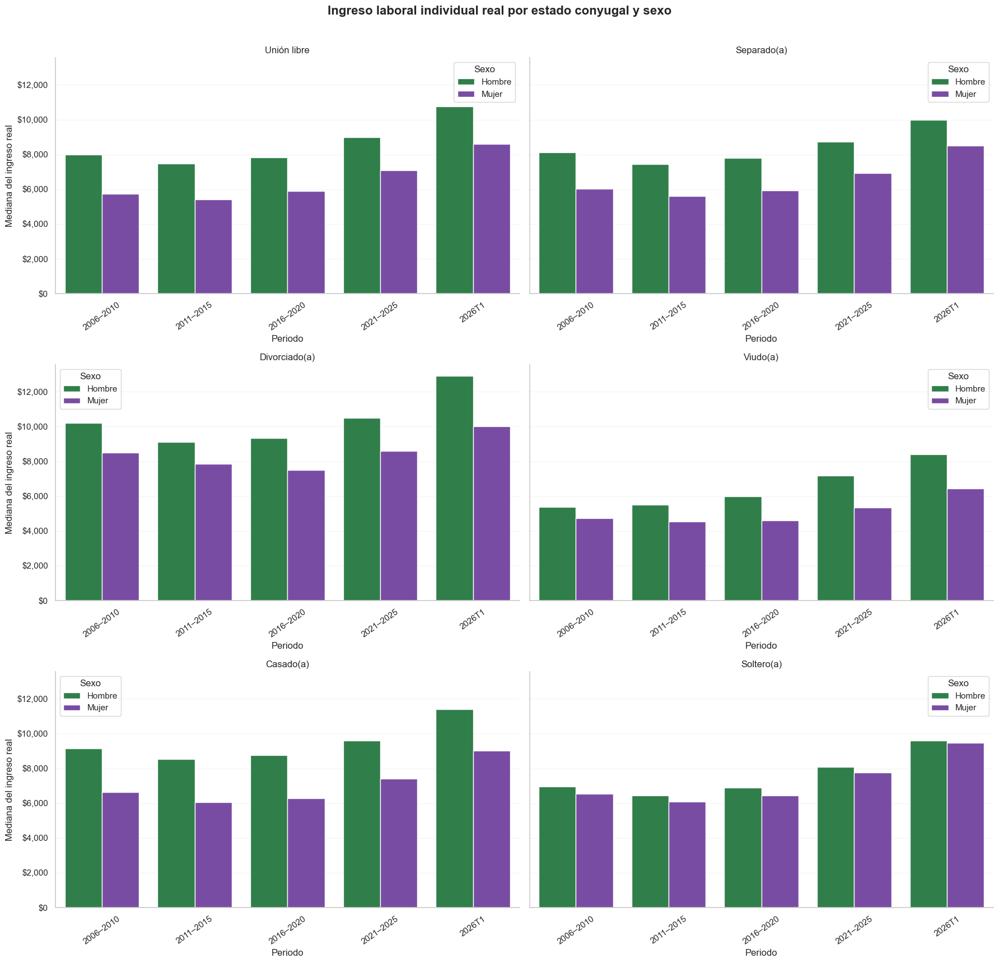

,periodo_analisis,estado_conyugal,sexo,n_muestral,peso_total,media,desviacion_estandar,p25,mediana,p75
8,2006–2010,Unión libre,Hombre,"249,648.00","74,074,081.00","9,604.79","9,665.95","5,216.92","7,975.29","11,426.81"
9,2006–2010,Unión libre,Mujer,"107,645.00","29,168,036.00","7,195.21","7,374.60","3,236.62","5,719.78","8,570.10"
20,2011–2015,Unión libre,Hombre,"300,728.00","95,132,761.00","8,751.76","8,464.06","5,048.30","7,467.54","10,565.34"
21,2011–2015,Unión libre,Mujer,"138,340.00","39,739,421.00","6,709.88","6,333.75","3,249.70","5,400.15","8,216.56"
32,2016–2020,Unión libre,Hombre,"320,326.00","107,852,660.00","9,089.19","7,421.46","5,486.39","7,814.30","10,776.83"
33,2016–2020,Unión libre,Mujer,"158,981.00","48,563,126.00","7,108.15","6,255.70","3,535.34","5,902.12","8,771.99"
44,2021–2025,Unión libre,Hombre,"410,151.00","132,045,160.00","10,793.30","9,079.75","6,460.13","8,986.46","12,860.36"
45,2021–2025,Unión libre,Mujer,"228,385.00","68,444,013.00","8,488.26","7,456.47","4,241.14","7,094.83","10,456.17"
56,2026T1,Unión libre,Hombre,"22,248.00","7,119,688.00","12,302.06","9,201.81","7,740.00","10,750.00","14,373.00"
57,2026T1,Unión libre,Mujer,"12,560.00","3,828,210.00","9,858.90","8,181.18","4,791.00","8,600.00","12,900.00"


In [39]:
ORDEN_CONYUGAL = ["Unión libre", "Separado(a)", "Divorciado(a)", "Viudo(a)", "Casado(a)", "Soltero(a)"]
df_ingreso_conyugal = resumen_ponderado(
    "ingreso_laboral_ind_real", ["periodo_analisis", "estado_conyugal", "sexo"],
    "es_ocupado AND factor_valido AND ingreso_laboral_ind_real > 0 "
    "AND sexo IN ('Hombre', 'Mujer') AND estado_conyugal NOT IN ('No sabe', 'No especificado') "
    "AND periodo <> '2020T2'"
)
df_ingreso_conyugal["periodo_analisis"] = pd.Categorical(df_ingreso_conyugal["periodo_analisis"], ORDEN_PERIODOS, ordered=True)
df_ingreso_conyugal["estado_conyugal"] = pd.Categorical(df_ingreso_conyugal["estado_conyugal"], ORDEN_CONYUGAL, ordered=True)

fig, axes = plt.subplots(3, 2, figsize=(18, 17), sharey=True)
for ax, estado in zip(axes.flat, ORDEN_CONYUGAL):
    datos = df_ingreso_conyugal[df_ingreso_conyugal["estado_conyugal"] == estado]
    sns.barplot(data=datos, x="periodo_analisis", y="mediana", hue="sexo", hue_order=["Hombre", "Mujer"],
                palette=COLOR_SEXO, errorbar=None, ax=ax)
    ax.set(title=estado, xlabel="Periodo", ylabel="Mediana del ingreso real")
    ax.tick_params(axis="x", rotation=35); ax.yaxis.set_major_formatter(FuncFormatter(formato_pesos))
    ax.grid(axis="y", alpha=0.20); ax.grid(axis="x", visible=False); ax.legend(title="Sexo"); sns.despine(ax=ax)
fig.suptitle("Ingreso laboral individual real por estado conyugal y sexo", y=1.01, fontsize=16, fontweight="bold")
plt.tight_layout(); plt.show()
display(df_ingreso_conyugal.sort_values(["estado_conyugal", "periodo_analisis", "sexo"]).round(2))


## Antes de preguntar por los hijos, ¿a quién se le hizo la pregunta?

Se cuenta la cobertura directa de hijos declarados en registros de 15 años y más, sin ponderar ese diagnóstico. Para mujeres ocupadas con respuestas válidas se calculan luego cuantiles ponderados.

**Lectura.** Hay **cero respuestas masculinas** entre 11,182,971 registros de hombres; entre mujeres, 12,488,397 de 12,488,978 tienen dato. La mediana femenina es dos hijos tanto en 2006 como en 2026T1. La ausencia de respuesta masculina no significa cero hijos.

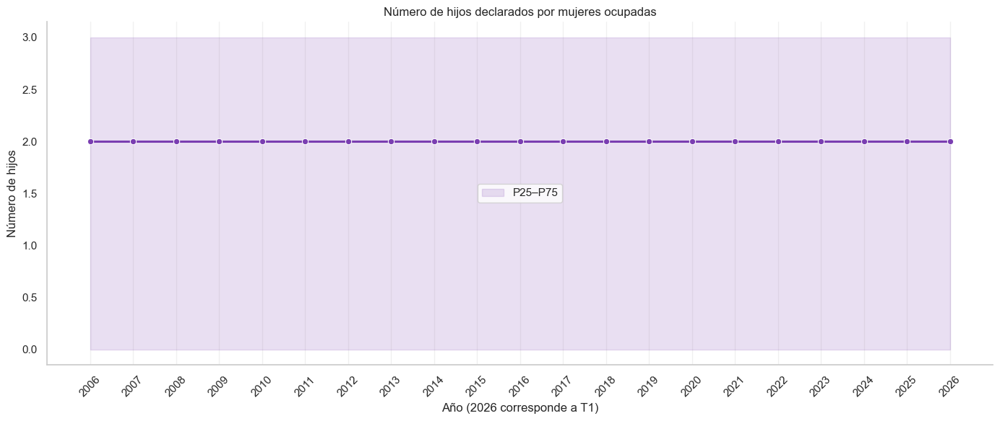

,sexo,n_muestral,respuestas_hijos,cobertura_pct
0,Hombre,11182971,0,0.00
1,Mujer,12488978,12488397,100.00


,anio,n_muestral,peso_total,media,desviacion_estandar,p25,mediana,p75
0,2006,"264,848.00","64,085,267.00",2.17,2.37,0.00,2.00,3.00
1,2007,"268,501.00","66,160,370.00",2.16,2.32,0.00,2.00,3.00
2,2008,"266,081.00","66,842,989.00",2.15,2.26,0.00,2.00,3.00
3,2009,"258,516.00","68,080,024.00",2.15,2.23,0.00,2.00,3.00
4,2010,"259,327.00","68,855,466.00",2.12,2.21,0.00,2.00,3.00
5,2011,"259,034.00","70,638,314.00",2.10,2.14,0.00,2.00,3.00
6,2012,"264,167.00","73,858,559.00",2.11,2.12,0.00,2.00,3.00
7,2013,"262,970.00","74,804,005.00",2.10,2.09,0.00,2.00,3.00
8,2014,"265,545.00","74,149,694.00",2.09,2.05,0.00,2.00,3.00
9,2015,"268,008.00","76,305,073.00",2.08,2.01,0.00,2.00,3.00


In [40]:
df_cobertura_hijos_sexo = con.sql(f"""
    SELECT sexo, COUNT(*) AS n_muestral,
           COUNT(numero_hijos_declarado) AS respuestas_hijos,
           100.0 * COUNT(numero_hijos_declarado) / COUNT(*) AS cobertura_pct
    FROM {TABLA_ANALISIS}
    WHERE eda >= 15 AND sexo IN ('Hombre', 'Mujer')
    GROUP BY sexo ORDER BY sexo
""").df()

df_hijos_anual = resumen_ponderado(
    "numero_hijos_declarado", ["anio"],
    "es_ocupado AND factor_valido AND sexo = 'Mujer' AND numero_hijos_declarado BETWEEN 0 AND 30 "
    "AND periodo <> '2020T2'"
)
fig, ax = plt.subplots(figsize=(14, 6))
sns.lineplot(data=df_hijos_anual, x="anio", y="mediana", color=COLOR_SEXO["Mujer"],
             marker="o", linewidth=2.2, ax=ax)
ax.fill_between(df_hijos_anual["anio"], df_hijos_anual["p25"], df_hijos_anual["p75"],
                color=COLOR_SEXO["Mujer"], alpha=0.16, label="P25–P75")
ax.set(title="Número de hijos declarados por mujeres ocupadas", xlabel="Año (2026 corresponde a T1)",
       ylabel="Número de hijos")
estilo_linea(ax, sorted(df_hijos_anual["anio"].unique())); ax.legend(); plt.tight_layout(); plt.show()
display(df_cobertura_hijos_sexo.round(2), df_hijos_anual.round(2))


## Entre mujeres solteras, ¿cambia la mediana con hijos declarados?

Se comparan mujeres ocupadas con ingreso positivo, estado conyugal identificado y respuesta válida de hijos. Se contrastan las dos curvas dentro del mismo estado conyugal.

**Lectura.** En 2026T1 la mediana de las solteras con hijos declarados es $9,200 frente a $9,500 sin hijos declarados. La diferencia es descriptiva: no identifica una penalización causal por maternidad ni informa sobre custodia.

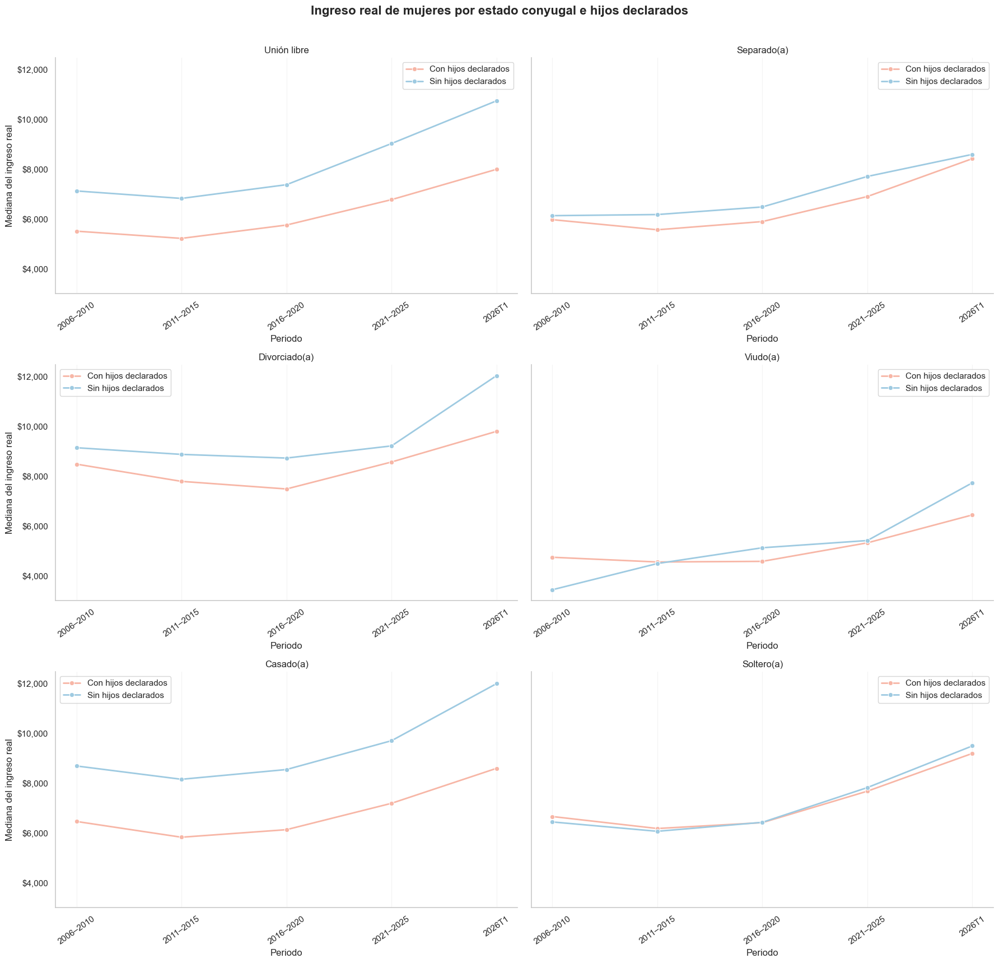

,periodo_analisis,estado_conyugal,tiene_hijos_declarados,n_muestral,peso_total,media,desviacion_estandar,p25,mediana,p75,condicion_hijos
9,2006–2010,Unión libre,True,"95,769.00","26,075,851.00","6,879.69","6,964.90","3,070.57","5,517.28","8,367.42",Con hijos declarados
8,2006–2010,Unión libre,False,"11,862.00","3,090,628.00","9,857.53","9,799.30","4,879.34","7,131.54","11,439.56",Sin hijos declarados
21,2011–2015,Unión libre,True,"121,707.00","35,152,177.00","6,406.35","5,914.93","3,068.99","5,227.28","7,969.44",Con hijos declarados
20,2011–2015,Unión libre,False,"16,629.00","4,586,873.00","9,035.93","8,562.51","4,602.24","6,831.26","10,653.54",Sin hijos declarados
33,2016–2020,Unión libre,True,"138,553.00","42,295,821.00","6,771.04","5,845.24","3,420.83","5,762.66","8,436.07",Con hijos declarados
32,2016–2020,Unión libre,False,"20,427.00","6,267,132.00","9,383.25","8,167.81","5,077.36","7,382.27","11,117.55",Sin hijos declarados
45,2021–2025,Unión libre,True,"190,902.00","57,249,494.00","7,881.30","6,629.45","3,965.88","6,782.33","9,867.81",Con hijos declarados
44,2021–2025,Unión libre,False,"37,474.00","11,193,451.00","11,592.54","10,181.31","6,146.47","9,034.79","13,461.76",Sin hijos declarados
57,2026T1,Unión libre,True,"10,363.00","3,174,420.00","9,112.62","7,500.74","4,791.00","8,000.00","11,610.00",Con hijos declarados
56,2026T1,Unión libre,False,"2,196.00","653,769.00","13,482.34","10,144.54","7,955.00","10,750.00","15,000.00",Sin hijos declarados


In [41]:
df_mujeres_hijos = resumen_ponderado(
    "ingreso_laboral_ind_real", ["periodo_analisis", "estado_conyugal", "tiene_hijos_declarados"],
    "es_ocupado AND factor_valido AND sexo = 'Mujer' AND ingreso_laboral_ind_real > 0 "
    "AND numero_hijos_declarado BETWEEN 0 AND 30 AND estado_conyugal NOT IN ('No sabe', 'No especificado') "
    "AND periodo <> '2020T2'"
)
df_mujeres_hijos["condicion_hijos"] = df_mujeres_hijos["tiene_hijos_declarados"].map(
    {True: "Con hijos declarados", False: "Sin hijos declarados"}
)
df_mujeres_hijos["periodo_analisis"] = pd.Categorical(df_mujeres_hijos["periodo_analisis"], ORDEN_PERIODOS, ordered=True)
df_mujeres_hijos["estado_conyugal"] = pd.Categorical(df_mujeres_hijos["estado_conyugal"], ORDEN_CONYUGAL, ordered=True)
COLOR_HIJOS = {"Con hijos declarados": PALETA_PASTEL[1], "Sin hijos declarados": PALETA_PASTEL[0]}

fig, axes = plt.subplots(3, 2, figsize=(18, 17), sharey=True)
for ax, estado in zip(axes.flat, ORDEN_CONYUGAL):
    datos = df_mujeres_hijos[df_mujeres_hijos["estado_conyugal"] == estado]
    sns.lineplot(data=datos, x="periodo_analisis", y="mediana", hue="condicion_hijos",
                 hue_order=["Con hijos declarados", "Sin hijos declarados"], palette=COLOR_HIJOS,
                 marker="o", linewidth=2, ax=ax)
    ax.set(title=estado, xlabel="Periodo", ylabel="Mediana del ingreso real")
    ax.tick_params(axis="x", rotation=35); ax.yaxis.set_major_formatter(FuncFormatter(formato_pesos))
    ax.grid(axis="x", alpha=0.20); ax.grid(axis="y", visible=False); ax.legend(title=None); sns.despine(ax=ax)
fig.suptitle("Ingreso real de mujeres por estado conyugal e hijos declarados", y=1.01,
             fontsize=16, fontweight="bold")
plt.tight_layout(); plt.show()
display(df_mujeres_hijos.sort_values(["estado_conyugal", "periodo_analisis", "condicion_hijos"]).round(2))


## Qué hogares aparecen detrás de ese contraste salarial

Ahora se cambia de magnitud: no se compara el ingreso, sino el número trimestral promedio de mujeres ocupadas con uno o más hijos declarados, según estado conyugal.

**Lectura.** En 2026T1 se cuentan 6.72 millones de casadas y 2.77 millones de solteras. «Soltera con hijos declarados» describe dos respuestas; por sí sola no identifica a una madre que cría sin apoyo.

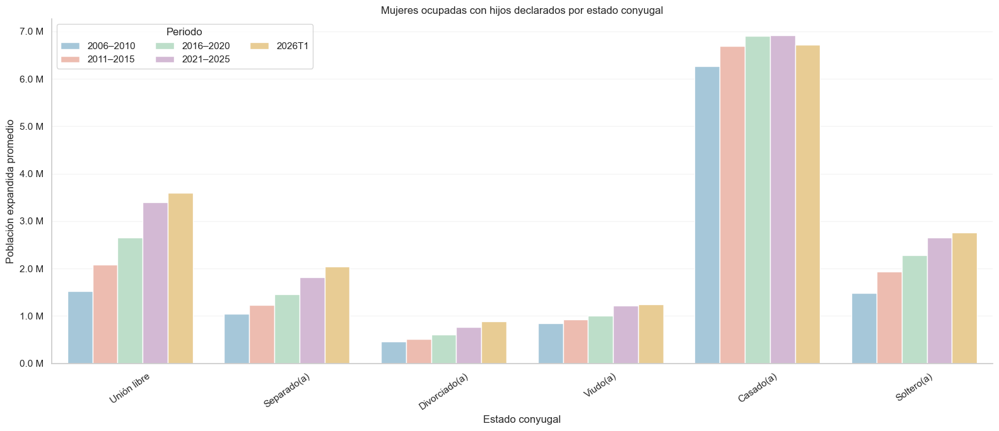

,periodo_analisis,estado_conyugal,poblacion_promedio
16,2006–2010,Unión libre,"1,523,316.90"
1,2006–2010,Separado(a),"1,050,364.60"
25,2006–2010,Divorciado(a),"459,217.15"
0,2006–2010,Viudo(a),"847,398.90"
10,2006–2010,Casado(a),"6,267,567.85"
11,2006–2010,Soltero(a),"1,491,044.50"
24,2011–2015,Unión libre,"2,081,028.45"
20,2011–2015,Separado(a),"1,231,179.10"
9,2011–2015,Divorciado(a),"511,723.10"
19,2011–2015,Viudo(a),"926,648.50"


In [42]:
df_mujeres_con_hijos_conyugal = con.sql(f"""
    WITH trimestral AS (
        SELECT periodo_analisis, periodo, estado_conyugal, SUM(fac_tri) AS poblacion
        FROM {TABLA_ANALISIS}
        WHERE es_ocupado AND factor_valido AND fac_tri > 0 AND sexo = 'Mujer'
          AND numero_hijos_declarado BETWEEN 1 AND 30
          AND estado_conyugal NOT IN ('No sabe', 'No especificado') AND periodo <> '2020T2'
        GROUP BY ALL
    )
    SELECT periodo_analisis, estado_conyugal, AVG(poblacion) AS poblacion_promedio
    FROM trimestral GROUP BY ALL
""").df()
df_mujeres_con_hijos_conyugal["periodo_analisis"] = pd.Categorical(
    df_mujeres_con_hijos_conyugal["periodo_analisis"], ORDEN_PERIODOS, ordered=True
)
df_mujeres_con_hijos_conyugal["estado_conyugal"] = pd.Categorical(
    df_mujeres_con_hijos_conyugal["estado_conyugal"], ORDEN_CONYUGAL, ordered=True
)
fig, ax = plt.subplots(figsize=(16, 7))
sns.barplot(data=df_mujeres_con_hijos_conyugal, x="estado_conyugal", y="poblacion_promedio",
            hue="periodo_analisis", hue_order=ORDEN_PERIODOS, palette=PALETA_PASTEL[:5], errorbar=None, ax=ax)
ax.set(title="Mujeres ocupadas con hijos declarados por estado conyugal",
       xlabel="Estado conyugal", ylabel="Población expandida promedio")
ax.yaxis.set_major_formatter(FuncFormatter(lambda x, _: f"{x / 1e6:.1f} M"))
ax.tick_params(axis="x", rotation=35); ax.grid(axis="y", alpha=0.20); ax.grid(axis="x", visible=False)
ax.legend(title="Periodo", ncol=3); sns.despine(ax=ax); plt.tight_layout(); plt.show()
display(df_mujeres_con_hijos_conyugal.sort_values(["periodo_analisis", "estado_conyugal"]))


## La comparación posible para hombres: corresidencia en jefaturas

Se reconstruye el hogar de cada trimestre y se restringe a jefaturas (101). Para ambos sexos, «con» significa que hay un integrante con parentesco 301–304; «sin» significa que no se identifica uno. La variante estricta para hombres solteros excluye pareja y otros integrantes según los códigos especificados.

**Lectura.** En 2026T1, los hombres solteros jefes con y sin hijos corresidentes registran medianas de $12,900 y $12,000; en jefas solteras, $9,460 y $10,000. El primer grupo masculino cuenta con 372 observaciones, frente a 4,415 sin hijos corresidentes. No es una comparación entre padres y no padres: no se observan hijos que residen fuera, filiación biológica ni custodia. La suma diagnóstica del periodo completo cuenta personas-trimestre expandidas, no padres únicos.

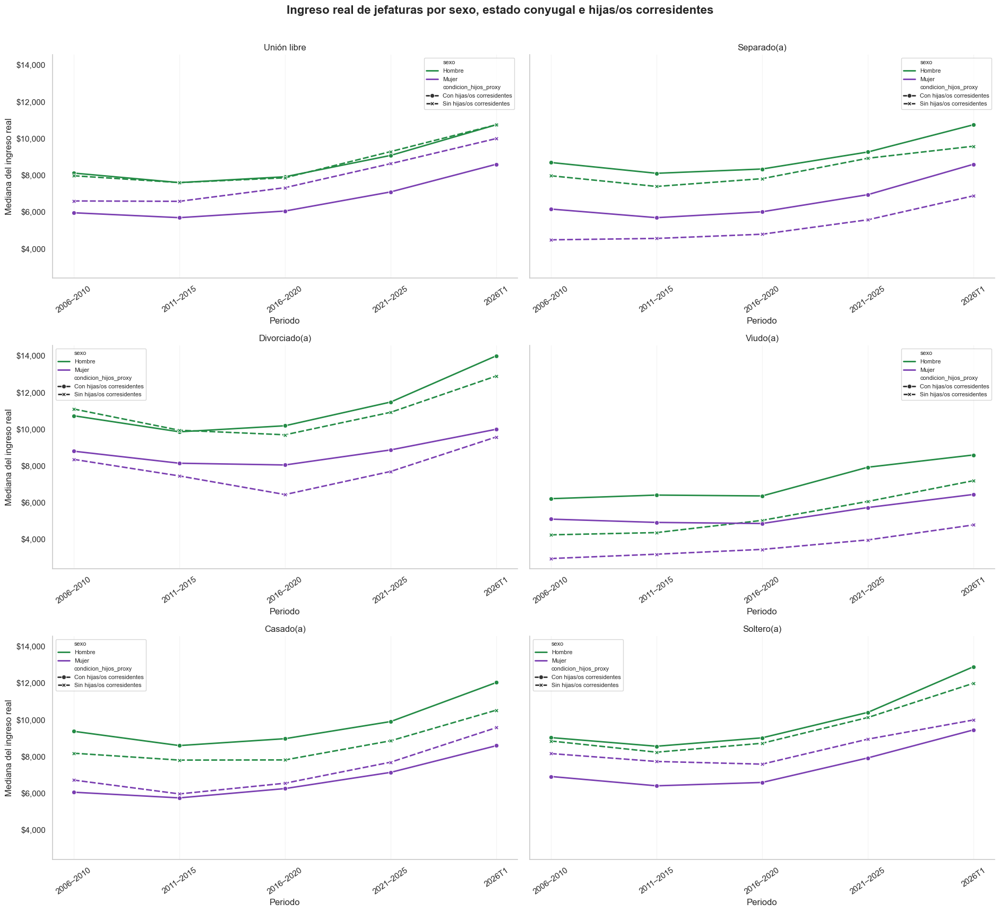

,periodo_analisis,estado_conyugal,sexo,condicion_hijos_proxy,n_muestral,peso_total,media,desviacion_estandar,p25,mediana,p75
16,2006–2010,Unión libre,Hombre,Con hijas/os corresidentes,"160,651.00","49,440,679.00","9,704.68","9,719.62","5,216.92","8,118.18","11,710.41"
17,2006–2010,Unión libre,Hombre,Sin hijas/os corresidentes,"29,897.00","8,259,385.00","10,347.77","12,573.99","5,004.32","7,972.11","11,874.31"
18,2006–2010,Unión libre,Mujer,Con hijas/os corresidentes,"13,072.00","3,357,100.00","7,529.36","7,764.14","3,479.98","5,956.95","8,967.76"
19,2006–2010,Unión libre,Mujer,Sin hijas/os corresidentes,"2,942.00","741,069.00","8,993.44","9,722.56","3,839.74","6,599.75","10,512.20"
40,2011–2015,Unión libre,Hombre,Con hijas/os corresidentes,"183,512.00","60,104,975.00","8,844.65","9,155.91","5,017.46","7,600.17","10,690.75"
...,...,...,...,...,...,...,...,...,...,...,...
87,2021–2025,Soltero(a),Mujer,Sin hijas/os corresidentes,"43,843.00","13,161,044.00","11,950.72","11,426.40","5,328.87","8,955.57","14,519.06"
108,2026T1,Soltero(a),Hombre,Con hijas/os corresidentes,372.00,"112,799.00","16,110.47","13,162.49","8,600.00","12,900.00","19,350.00"
109,2026T1,Soltero(a),Hombre,Sin hijas/os corresidentes,"4,415.00","1,321,507.00","14,393.88","12,082.76","8,400.00","12,000.00","16,000.00"
110,2026T1,Soltero(a),Mujer,Con hijas/os corresidentes,"3,517.00","1,135,754.00","10,777.20","7,681.09","6,450.00","9,460.00","14,000.00"


,sexo,condicion_hijos_proxy,n_muestral,poblacion_expandida,padres_solteros_proxy_estrictos
0,Hombre,Con hijas/os corresidentes,3935356,"1,194,519,312.00","2,825,711.00"
1,Hombre,Sin hijas/os corresidentes,1172590,"348,229,302.00",0.00
2,Mujer,Con hijas/os corresidentes,995485,"280,065,394.00",0.00
3,Mujer,Sin hijas/os corresidentes,357979,"101,432,695.00",0.00


In [43]:
con.execute(f"""
    CREATE OR REPLACE TEMP VIEW jefaturas_parentalidad AS
    WITH composicion_hogar AS (
        SELECT
            id_hogar_periodo,
            BOOL_OR(parentesco_codigo BETWEEN 301 AND 304) AS tiene_hijos_corresidentes,
            BOOL_OR(parentesco_codigo BETWEEN 201 AND 205) AS tiene_pareja_corresidente,
            BOOL_OR(parentesco_codigo >= 400) AS tiene_otros_parientes,
            BOOL_OR(parentesco_codigo >= 500) AS tiene_no_parientes
        FROM {TABLA_ANALISIS}
        GROUP BY id_hogar_periodo
    )
    SELECT
        e.*,
        h.tiene_hijos_corresidentes,
        h.tiene_pareja_corresidente,
        h.tiene_otros_parientes,
        h.tiene_no_parientes,
        CASE WHEN h.tiene_hijos_corresidentes
             THEN 'Con hijas/os corresidentes'
             ELSE 'Sin hijas/os corresidentes' END AS condicion_hijos_proxy,
        (
            e.sexo = 'Hombre'
            AND e.estado_conyugal = 'Soltero(a)'
            AND h.tiene_hijos_corresidentes
            AND NOT h.tiene_pareja_corresidente
            AND NOT h.tiene_otros_parientes
            AND NOT h.tiene_no_parientes
        ) AS padre_soltero_proxy_estricto
    FROM {TABLA_ANALISIS} AS e
    INNER JOIN composicion_hogar AS h USING (id_hogar_periodo)
    WHERE e.parentesco_codigo = 101
""")

ORDEN_HIJOS_PROXY = ["Con hijas/os corresidentes", "Sin hijas/os corresidentes"]
df_ingreso_jefaturas_hijos_proxy = resumen_ponderado(
    "ingreso_laboral_ind_real", ["periodo_analisis", "estado_conyugal", "sexo", "condicion_hijos_proxy"],
    "es_ocupado AND factor_valido AND ingreso_laboral_ind_real > 0 "
    "AND sexo IN ('Hombre', 'Mujer') AND estado_conyugal NOT IN ('No sabe', 'No especificado') "
    "AND periodo <> '2020T2'",
    tabla="jefaturas_parentalidad",
)
df_ingreso_jefaturas_hijos_proxy["periodo_analisis"] = pd.Categorical(
    df_ingreso_jefaturas_hijos_proxy["periodo_analisis"], ORDEN_PERIODOS, ordered=True
)
df_ingreso_jefaturas_hijos_proxy["estado_conyugal"] = pd.Categorical(
    df_ingreso_jefaturas_hijos_proxy["estado_conyugal"], ORDEN_CONYUGAL, ordered=True
)
df_ingreso_jefaturas_hijos_proxy["condicion_hijos_proxy"] = pd.Categorical(
    df_ingreso_jefaturas_hijos_proxy["condicion_hijos_proxy"], ORDEN_HIJOS_PROXY, ordered=True
)

fig, axes = plt.subplots(3, 2, figsize=(19, 17), sharey=True)
for ax, estado in zip(axes.flat, ORDEN_CONYUGAL):
    datos = df_ingreso_jefaturas_hijos_proxy.query("estado_conyugal == @estado")
    sns.lineplot(
        data=datos, x="periodo_analisis", y="mediana", hue="sexo", style="condicion_hijos_proxy",
        hue_order=["Hombre", "Mujer"], style_order=ORDEN_HIJOS_PROXY, palette=COLOR_SEXO,
        markers=True, dashes=True, linewidth=2.0, ax=ax,
    )
    ax.set(title=estado, xlabel="Periodo", ylabel="Mediana del ingreso real")
    ax.tick_params(axis="x", rotation=35); ax.yaxis.set_major_formatter(FuncFormatter(formato_pesos))
    ax.grid(axis="x", alpha=0.20); ax.grid(axis="y", visible=False); ax.legend(title=None, fontsize=8)
    sns.despine(ax=ax)
fig.suptitle("Ingreso real de jefaturas por sexo, estado conyugal e hijas/os corresidentes", y=1.01,
             fontsize=16, fontweight="bold")
plt.tight_layout(); plt.show()

df_diagnostico_proxy = con.sql("""
    SELECT sexo, condicion_hijos_proxy, COUNT(*) AS n_muestral, SUM(fac_tri) AS poblacion_expandida,
           SUM(CASE WHEN padre_soltero_proxy_estricto THEN fac_tri ELSE 0 END) AS padres_solteros_proxy_estrictos
    FROM jefaturas_parentalidad
    WHERE es_ocupado AND factor_valido AND fac_tri > 0 AND periodo <> '2020T2'
      AND sexo IN ('Hombre', 'Mujer')
    GROUP BY sexo, condicion_hijos_proxy
    ORDER BY sexo, condicion_hijos_proxy
""").df()
display(
    df_ingreso_jefaturas_hijos_proxy.sort_values(
        ["estado_conyugal", "periodo_analisis", "sexo", "condicion_hijos_proxy"]
    ).round(2),
    df_diagnostico_proxy.round(2),
)


# 8. Un último punto de referencia: ¿qué representa el salario mínimo frente a la mediana?

El Kaitz divide el mínimo general mensual real entre el P50 mensual real de ocupados con ingreso positivo. Se toma el piso entre zonas en las fechas registradas, se completa el calendario diario, se mensualiza con 30.4 días, se deflacta por trimestre y se promedia por año.

**Lectura.** En 2006 el mínimo de referencia ($3,286) equivalía a 0.41 veces la mediana ($7,972). En 2026T1 son $9,577.22 frente a $9,582: casi uno, no exactamente uno. No es la proporción que cobra el mínimo, una prueba de cumplimiento ni una tasa de pobreza laboral. El piso no representa el mínimo diferenciado de la frontera norte.

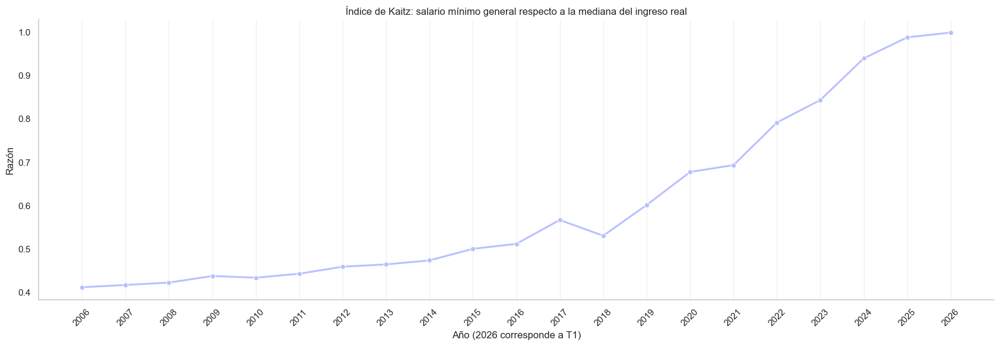

,anio,salario_minimo_mensual_real,mediana,indice_kaitz
0,2006,"3,285.99","7,972.11",0.41
1,2007,"3,284.06","7,866.67",0.42
2,2008,"3,249.30","7,684.42",0.42
3,2009,"3,237.86","7,390.63",0.44
4,2010,"3,259.40","7,506.48",0.43
5,2011,"3,281.08","7,402.58",0.44
6,2012,"3,283.84","7,144.95",0.46
7,2013,"3,286.49","7,069.93",0.47
8,2014,"3,282.60","6,923.67",0.47
9,2015,"3,509.66","7,008.40",0.50


In [44]:
if RUTA_SALARIO_MINIMO.exists():
    salario_minimo = pd.read_csv(RUTA_SALARIO_MINIMO)
    requeridas_sm = {"inicio_vigencia", "zona_salarial", "salario_minimo_general"}
    if not requeridas_sm.issubset(salario_minimo.columns):
        raise ValueError(f"El CSV de salario mínimo debe contener {sorted(requeridas_sm)}")

    salario_minimo["inicio_vigencia"] = pd.to_datetime(
        salario_minimo["inicio_vigencia"], errors="coerce"
    ).dt.normalize()
    salario_minimo["salario_minimo_general"] = pd.to_numeric(
        salario_minimo["salario_minimo_general"], errors="coerce"
    )
    sm_piso = (salario_minimo
               .dropna(subset=["inicio_vigencia", "salario_minimo_general"])
               .groupby("inicio_vigencia", as_index=False)["salario_minimo_general"].min()
               .sort_values("inicio_vigencia"))

    calendario = pd.DataFrame({"fecha": pd.date_range("2006-01-01", "2026-03-31", freq="D")})
    calendario["fecha"] = pd.to_datetime(calendario["fecha"]).dt.normalize()
    calendario = calendario.merge(
        sm_piso.rename(columns={"inicio_vigencia": "fecha"}), on="fecha", how="left", validate="one_to_one"
    )
    calendario["salario_minimo_diario"] = calendario["salario_minimo_general"].ffill()
    if calendario["salario_minimo_diario"].isna().any():
        raise ValueError("La serie de salario mínimo no cubre el inicio del calendario de análisis.")

    calendario["anio"] = calendario["fecha"].dt.year
    calendario["trimestre"] = calendario["fecha"].dt.quarter
    sm_trimestral = (calendario.groupby(["anio", "trimestre"], as_index=False)["salario_minimo_diario"].mean()
                     .merge(inpc_trimestral[["anio", "trimestre", "factor_deflactor"]],
                            on=["anio", "trimestre"], how="left", validate="one_to_one"))
    sm_trimestral["salario_minimo_mensual_real"] = (
        sm_trimestral["salario_minimo_diario"] * 30.4 * sm_trimestral["factor_deflactor"]
    )
    sm_anual = sm_trimestral.groupby("anio", as_index=False)["salario_minimo_mensual_real"].mean()
    df_kaitz = sm_anual.merge(df_ingreso_anual[["anio", "mediana"]], on="anio", how="inner", validate="one_to_one")
    df_kaitz["indice_kaitz"] = df_kaitz["salario_minimo_mensual_real"] / df_kaitz["mediana"]

    fig, ax = plt.subplots(figsize=(17, 6))
    sns.lineplot(data=df_kaitz, x="anio", y="indice_kaitz", color=PALETA_PASTEL[5],
                 marker="o", linewidth=2.2, ax=ax)
    ax.set(title="Índice de Kaitz: salario mínimo general respecto a la mediana del ingreso real",
           xlabel="Año (2026 corresponde a T1)", ylabel="Razón")
    estilo_linea(ax, sorted(df_kaitz["anio"].unique()))
    plt.tight_layout(); plt.show(); display(df_kaitz.round(3))
else:
    print("Índice de Kaitz pendiente: no se encontró", RUTA_SALARIO_MINIMO)
    print("Guarda el archivo 'sm_general_profesionales_zonas.csv' en data/raw/salarios_minimos/.")


## Mismo mínimo, otro denominador: solo empleo formal

Se conserva la serie de salario mínimo y se recalcula la mediana entre ocupados con empleo principal formal e ingreso positivo. Esta única diferencia permite interpretar el contraste con el índice anterior.

**Lectura.** El Kaitz formal pasa de 0.32 en 2006 a 0.74 en 2026T1. Al cierre, el mismo piso de $9,577.22 se compara aquí con $12,900, no con $9,582. Que la razón sea menor refleja un denominador mayor, no un salario mínimo diferente.

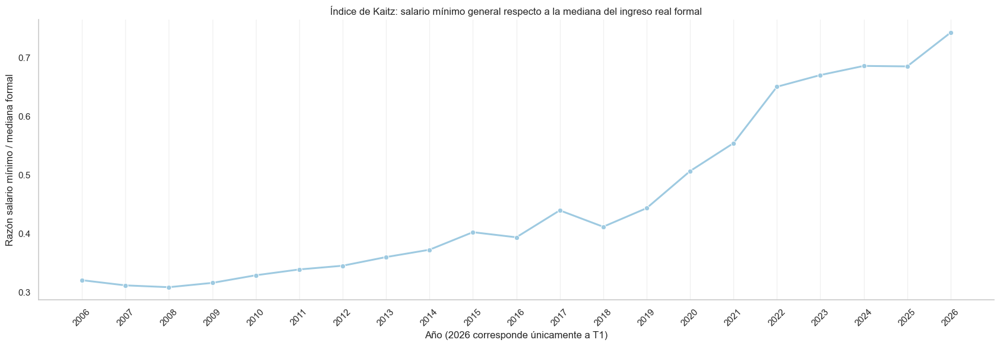

,anio,salario_minimo_mensual_real,mediana_ingreso_real_formal,indice_kaitz_formal
0,2006,"3,285.99","10,236.51",0.32
1,2007,"3,284.06","10,519.38",0.31
2,2008,"3,249.30","10,512.20",0.31
3,2009,"3,237.86","10,232.17",0.32
4,2010,"3,259.40","9,895.26",0.33
5,2011,"3,281.08","9,670.15",0.34
6,2012,"3,283.84","9,501.33",0.35
7,2013,"3,286.49","9,120.21",0.36
8,2014,"3,282.60","8,804.45",0.37
9,2015,"3,509.66","8,714.88",0.40


In [45]:
# Índice de Kaitz con denominador: ingreso laboral de empleo formal
df_ingreso_anual_formal = resumen_ponderado(
    "ingreso_laboral_ind_real",
    ["anio"],
    """
        es_ocupado
        AND factor_valido
        AND fac_tri > 0
        AND ingreso_laboral_ind_real > 0
        AND tipo_empleo = 'Formal'
        AND periodo <> '2020T2'
    """
)

df_kaitz_formal = sm_anual.merge(
    df_ingreso_anual_formal[["anio", "mediana"]],
    on="anio",
    how="inner",
    validate="one_to_one"
)

df_kaitz_formal["indice_kaitz_formal"] = (
    df_kaitz_formal["salario_minimo_mensual_real"]
    / df_kaitz_formal["mediana"]
)

fig, ax = plt.subplots(figsize=(17, 6))

sns.lineplot(
    data=df_kaitz_formal,
    x="anio",
    y="indice_kaitz_formal",
    color=COLOR_EMPLEO["Formal"],
    marker="o",
    linewidth=2.2,
    ax=ax
)

ax.set(
    title="Índice de Kaitz: salario mínimo general respecto a la mediana del ingreso real formal",
    xlabel="Año (2026 corresponde únicamente a T1)",
    ylabel="Razón salario mínimo / mediana formal"
)

estilo_linea(ax, sorted(df_kaitz_formal["anio"].unique()))
plt.tight_layout()
plt.show()

display(
    df_kaitz_formal.rename(
        columns={"mediana": "mediana_ingreso_real_formal"}
    ).round(3)
)

## Cómo reproducir la radiografía del mercado laboral

El análisis exploratorio se reproduce mediante el repositorio de código y el paquete de datos histórico. El repositorio contiene el notebook, la documentación, las dependencias y la estructura de carpetas; los insumos pesados se distribuyen mediante Mega.

- **Repositorio de código y notebook:**  
  <https://github.com/DevArmando99/enoe-mercado-laboral-mexico-2006-2026>

- **Paquete de datos para reproducción:**  
  <https://mega.nz/folder/RtVilTqL#HwadnXj5Ch8BmGkU55xvfw>

### Ruta corta: ejecutar el análisis exploratorio

1. Clonar el repositorio y entrar a su carpeta raíz:

   ```bash
   git clone https://github.com/DevArmando99/enoe-mercado-laboral-mexico-2006-2026.git
   cd enoe-mercado-laboral-mexico-2006-2026

2. Descargar desde Mega la carpeta data/ y copiarla dentro de la raíz del repositorio clonado. Debe conservarse la estructura y los nombres de archivo:
   ```text
   enoe-mercado-laboral-mexico-2006-2026/
    ├── data/
    │   ├── geo/
    │   │   └── entidades_federativas.geojson
    │   ├── parquet/
    │   │   └── historical/
    │   │       └── enoe_analisis_pl_2006T1_2026T1.parquet
    │   └── raw/
    │       ├── INPC/
    │       │   └── INP_INP20260831105110.xlsx
    │       └── salarios_minimos/
    │           └── sm_general_profesionales_zonas.csv
    └── notebooks/
        └── Exploracion_ENOE_reorganizado.ipynb

3. Crear y activar un entorno virtual. En Windows mediante CMD:

   ```bash
    py -m venv .venv
    .venv\Scripts\activate
    python -m pip install --upgrade pip
    pip install -r requirements.txt
    

4. Iniciar Jupyter desde la raíz del repositorio, no desde la carpeta notebooks/:

   ```bash
   jupyter lab


5. Abrir notebooks/Exploracion_ENOE_reorganizado.ipynb, seleccionar el kernel del entorno creado y ejecutar todas las celdas de arriba hacia abajo.

El notebook resuelve sus rutas desde la raíz del proyecto. Por ello, al ejecutarse desde notebooks/, debe verificarse que el directorio de trabajo del kernel corresponda a enoe-mercado-laboral-mexico-2006-2026/; de lo contrario, debe ajustarse la variable RAIZ.

**Insumos requeridos**
| Obtención | Ruta dentro del proyecto | Finalidad |
|---|---|---|
| Mega | `data/parquet/historical/enoe_analisis_pl_2006T1_2026T1.parquet` | Base histórica analítica concatenada; incluye las variables educativas `niv_ins` y `anios_esc`. |
| Mega | `data/raw/INPC/INP_INP20260831105110.xlsx` | Serie del INPC usada para deflactar los ingresos a pesos de 2026T1. Debe conservar la hoja «Página 1» y su disposición original. |
| Mega | `data/raw/salarios_minimos/sm_general_profesionales_zonas.csv` | Fechas de vigencia, zonas y montos usados para construir el índice de Kaitz. |
| Mega | `data/geo/entidades_federativas.geojson` | Geometría de las 32 entidades federativas para elaborar los mapas estatales. |

No se requiere instalar `enoe-utilities` para ejecutar el análisis exploratorio con el Parquet histórico final. Esa biblioteca solo es necesaria para reconstruir la base desde los microdatos trimestrales originales.

Controles de réplica esperados
La base histórica utilizada por el notebook contiene:
- 31,788,662 filas;
- 80 columnas;
- 80 trimestres, desde 2006T1 hasta 2026T1;
- cero filas sin INPC asociado;
- factor de deflactación igual a 1 en 2026T1.
El segundo trimestre de 2020 se excluye debido a la interrupción del levantamiento habitual de la ENOE. Para 2026 se incorpora únicamente el primer trimestre.

Como control adicional, la mediana ponderada del ingreso laboral individual real para el total de personas ocupadas con ingreso positivo en 2026T1 es aproximadamente $9,582 mensuales, expresados en pesos de 2026T1.


**Ruta larga: reconstruir y auditar el Parquet**

La reconstrucción integral de la base histórica no es necesaria para reproducir las gráficas y tablas del notebook exploratorio. Se trata de una ruta adicional orientada a auditoría metodológica y reconstrucción desde los microdatos originales.

Esta ruta requiere:
- Replica_Indice_Pobreza_Laboral.ipynb;
- la versión de enoe-utilities que incorporó las variables educativas;
- los 80 archivos ZIP trimestrales de microdatos originales, sin incluir 2020T2;
- data/raw/lpei/indicadores_linea_pobreza.csv;
- opcionalmente, data/raw/lp/pl_2005t_2026t.xlsx para contrastar la réplica del indicador de pobreza laboral.
El proceso genera bases convertidas, uniones trimestrales, archivos analíticos y, finalmente, el Parquet histórico empleado por el EDA.
Archivos no requeridos para el EDA
Los Parquet trimestrales intermedios —incluidos converted/, merged/ y analytical/—, los productos de outputs/paradata/, outputs/indicators/, los ZIP de microdatos y los checkpoints de Jupyter son útiles para auditoría o reconstrucción completa, pero no son necesarios para reproducir las visualizaciones del análisis exploratorio.

Los resultados son elaborados mediante una investigación independiente con datos abiertos. No constituyen una publicación oficial del INEGI.


# Conclusión general · Un mercado más grande, con una recuperación desigual

La historia no es la de una mejora uniforme durante veinte años. México llega a 2026T1 con más personas ocupadas tanto en el empleo formal como en el informal. La formalidad ganó **4.14 puntos porcentuales** frente a 2006, pero todavía había cerca de **33 millones** de personas en empleo principal informal y **27 millones** en formal. El aumento del empleo registrado en cada categoría y el predominio relativo de la informalidad son dos hechos compatibles. También se estrechó la diferencia entre las proporciones ocupadas de hombres y mujeres, aunque al cierre seguía siendo de unos 28 puntos.

**La recuperación del ingreso real se aprecia mejor mirando la trayectoria que comparando solo los extremos.** La mediana mensual de quienes tenían ingreso positivo descendió de 7,972 MXN en 2006 a 6,924 MXN en 2014. Hacia 2025 había alcanzado 8,815 MXN, por encima del inicio incluso antes de incorporar el corte parcial de 9,582 MXN en 2026T1. Los umbrales inferiores y superiores no se movieron al mismo ritmo: tanto P50/P10 como P99/P50 terminan por debajo de sus valores iniciales. Esto describe una menor distancia relativa en esos dos puntos de la distribución observada; no mide toda la desigualdad de los hogares. Tampoco identifica un efecto del salario mínimo, aunque el Kaitz muestra que el piso de referencia se acercó a la mediana general mucho más que a la formal.

**El mes y la hora revelan desigualdades distintas.** En 2026T1 las medianas mensuales de hombres y mujeres difieren en 1,935 MXN (10,535 MXN frente a 8,600 MXN). Por hora difieren en 2.53 MXN (55.56 MXN frente a 53.03 MXN); en empleo formal la distancia por hora se reduce a 1.45 MXN. La mediana de horas fue de 46 para hombres y 40 para mujeres. Las horas aportan contexto al contraste mensual, pero esas medianas no permiten descomponerlo aritméticamente ni concluir que dos personas reciben igual pago por el mismo trabajo.

**El promedio nacional no describe un único mercado.** En 2026T1 una ocupada urbana con ingreso positivo tenía una mediana mensual de 9,460 MXN frente a 5,375 MXN en el ámbito rural. A su vez, dos estados con igual mediana mensual —Yucatán y Zacatecas— no tienen la misma mediana por hora. El comercio al por menor mantiene un peso cercano al 17% del empleo clasificado en los dos extremos, pero llega a 30.49% entre las mujeres en empleo informal del último corte. Cambiar de territorio, sector o grupo cambia la comparación.

La escolaridad y el hogar también ayudan a formular mejores preguntas. Con doce y dieciséis años aprobados, las medianas combinadas de ingreso son 8,301 MXN y 12,745 MXN: una asociación que merece estudiarse controlando edad, horas, sector y territorio. En el ámbito familiar, la comparación defendible para ambos sexos es entre **jefaturas con o sin hijas/os corresidentes**, no entre todos los padres y todas las madres. Y un segundo empleo no es necesariamente cada vez más frecuente solo porque haya crecido su número absoluto.

**Alcance del diagnóstico.** El último dato es enero–marzo, no el año 2026; 2020 no incluye T2. Las distribuciones no siguen a personas únicas durante dos décadas. Los ingresos positivos recuperados excluyen faltantes y ceros; el INPC nacional no corrige diferencias locales del costo de vida. No hay intervalos de confianza de diseño ni pruebas de causalidad. La conclusión defendible es más concreta: **se recuperó el centro de la distribución del ingreso real observado, mientras la informalidad, el territorio y la distribución de las jornadas siguieron distinguiendo experiencias laborales muy diferentes**. El siguiente paso para explicarlas sería separar cambios de composición de cambios dentro de grupos y estimar incertidumbre con el diseño muestral.